<a href="https://colab.research.google.com/github/maxirios27/WAVE_CLUST/blob/main/WAVE_Clust_global.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Workflow Summary and Model Overview

This Google Colab notebook provides a comprehensive, publication-ready pipeline for analyzing multicellular functional dynamics. It is designed to extract wavelet-based features, perform dimensionality reduction, identify cellular subpopulations via hierarchical clustering, and run rigorous statistical and phase coupling evaluations.

### Workflow Stages:

1. **Data Preprocessing & Verification (Blocks 1-3):**
   * Standardizes libraries and sets global aesthetic/analytical configurations.
   * Automatically loads high-dimensional raw signal profiles and filters features to protect downstream Z-scores from division errors.

2. **Feature Extraction with `PureWaveletSegmentedExtractor` (Block 3):**
   * A custom transformer segmenting temporal signals into **basal**, **early**, and **late** windows relative to stimulus onset.
   * Extracts robust metrics (signal standard deviation, skewness, mean wavelet period, and mean wavelet amplitude).
   * Incorporates a strict **Cone of Influence (COI)** mathematical filter ($1.414 \times \text{period}$) to suppress edge artifacts, and computes Signal-to-Noise Ratio (SNR) trajectories.

3. **Dimensionality Reduction & Clustering (Block 3):**
   * Performs Z-score standardization within each experimental well to mitigate batch effects.
   * Imputes missing values via median imputation, drops highly collinear variables, Z-scores remaining variables, and projects them onto principal components (PCA).
   * Groups cells via Hierarchical Agglomerative Clustering (Ward's linkage) and visualizes the results on a 2D UMAP projection.
   * Trains a Random Forest Classifier to score feature importance.

4. **Cluster Evaluation & Subpopulation Diagnostics (Blocks 5-10):**
   * Computes Silhouette, Davies-Bouldin, and Calinski-Harabasz metrics to justify the optimal cluster division alongside a tree-cut dendrogram.
   * Displays interactive UMAP subpopulation profiles, Chi-squared well-association tests, and exports ROI mappings grouped by well for ImageJ/Fiji macro integration.
   * Plots temporal averages of detrended signals, periods, and amplitudes by cluster with localized COI shading.

5. **Intra-Cluster & Inter-Cluster Statistical Reporting (Block 12):**
   * Compiles paired Wilcoxon Signed-Rank tests for internal temporal shifts and non-parametric Kruskal-Wallis/post-hoc Mann-Whitney U tests (with Benjamini-Hochberg FDR adjustments) to compare key features across subpopulations.

6. **Phase Coupling & Synchronization Analysis (Blocks 15-18):**
   * Determines instantaneous cell-to-centroid phase differences outside the COI.
   * Generates polar coordinate coupling maps with Rayleigh uniformity testing and non-parametric circular permutation tests (2000 shuffles) comparing Early vs. Late synchronization.
   * Visualizes intra-cluster phase locking dynamics $R(t)$ over time with 95% bootstrap confidence intervals.

# BLOCK 1: Libraries

In [ ]:
# ==============================================================================
# BLOCK 1: External Libraries and Dependencies
# ==============================================================================

# Standard library imports
import io
import os
import re
import sys
import warnings
from itertools import combinations

# Data manipulation and analysis
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import plotly.express as px
import seaborn as sns

# Scientific computing and statistics
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import fcluster, leaves_list, linkage
from scipy.stats import chi2_contingency, kruskal, mannwhitneyu, norm, skew, wilcoxon

# Machine learning, preprocessing and evaluation
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.preprocessing import PowerTransformer

# Statistical models and multi-test corrections
from statsmodels.stats.multitest import multipletests

# Google Colab specific utility
from google.colab import files

# Optional dimensionality reduction libraries with fallback options
try:
    import umap
    HAS_UMAP = True
except ImportError:
    from sklearn.manifold import TSNE
    HAS_UMAP = False

# Filter warnings to keep the output clean
warnings.filterwarnings('ignore')

#BLOCK 2: Uploading Files to Colab 📂


In [ ]:

print("Selecciona el archivo CSV de datos integrados:")
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df_raw = pd.read_csv(io.BytesIO(uploaded[file_name]))
print(f"\n[OK] Datos cargados exitosamente. Matriz: {df_raw.shape}")

Selecciona el archivo CSV de datos integrados:


Saving df_wavelet_Results_well_2-APB.csv to df_wavelet_Results_well_2-APB.csv

[OK] Datos cargados exitosamente. Matriz: (300, 449)


In [ ]:
df_raw


,time,Cell_1_raw,Cell_1_norm,Cell_1_delta_f_f0,Cell_1_detrended,Cell_1_periods,Cell_1_phase,Cell_1_power,Cell_1_amplitude,Cell_2_raw,...,Cell_55_power,Cell_55_amplitude,Cell_56_raw,Cell_56_norm,Cell_56_delta_f_f0,Cell_56_detrended,Cell_56_periods,Cell_56_phase,Cell_56_power,Cell_56_amplitude
0,0.0,1.014250,1.014135,0.014135,0.782989,45.731544,0.415767,4.679010,0.166754,1.019552,...,NaN,NaN,1.022868,1.021008,0.021008,0.553291,NaN,NaN,NaN,NaN
1,1.0,1.019583,1.019467,0.019467,0.872011,45.731544,0.552410,4.843003,0.169651,1.018959,...,NaN,NaN,0.989292,0.987493,-0.012507,-0.080663,NaN,NaN,NaN,NaN
2,2.0,0.974071,0.973961,-0.026039,-0.389312,45.731544,0.689497,5.012145,0.172588,0.983815,...,NaN,NaN,0.999888,0.998070,-0.001930,0.118603,NaN,NaN,NaN,NaN
3,3.0,0.958196,0.958088,-0.041912,-0.758012,45.731544,0.826274,5.181331,0.175477,0.911438,...,NaN,NaN,1.039570,1.037680,0.037680,0.864123,NaN,NaN,NaN,NaN
4,4.0,1.015806,1.015691,0.015691,0.623285,45.731544,0.962773,5.349002,0.178294,0.995972,...,NaN,NaN,0.932894,0.931198,-0.068802,-1.141716,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,295.0,1.135355,1.135226,0.135226,0.662567,NaN,NaN,NaN,NaN,0.937007,...,NaN,NaN,0.806303,0.804837,-0.195163,0.023358,74.536913,5.788746,6.273957,0.158842
296,296.0,1.106489,1.106364,0.106364,0.101967,NaN,NaN,NaN,NaN,0.900715,...,NaN,NaN,0.786928,0.785497,-0.214503,-0.328623,74.536913,5.872259,6.180905,0.157660
297,297.0,1.109798,1.109673,0.109673,0.176647,NaN,NaN,NaN,NaN,0.889203,...,NaN,NaN,0.783798,0.782373,-0.217627,-0.382792,74.536913,5.954539,6.030475,0.155730
298,298.0,1.142250,1.142120,0.142120,0.894912,NaN,NaN,NaN,NaN,0.913051,...,NaN,NaN,0.849190,0.847646,-0.152354,0.825858,75.033557,6.013026,6.004719,0.154882


#BLOCK 3: Global Variables

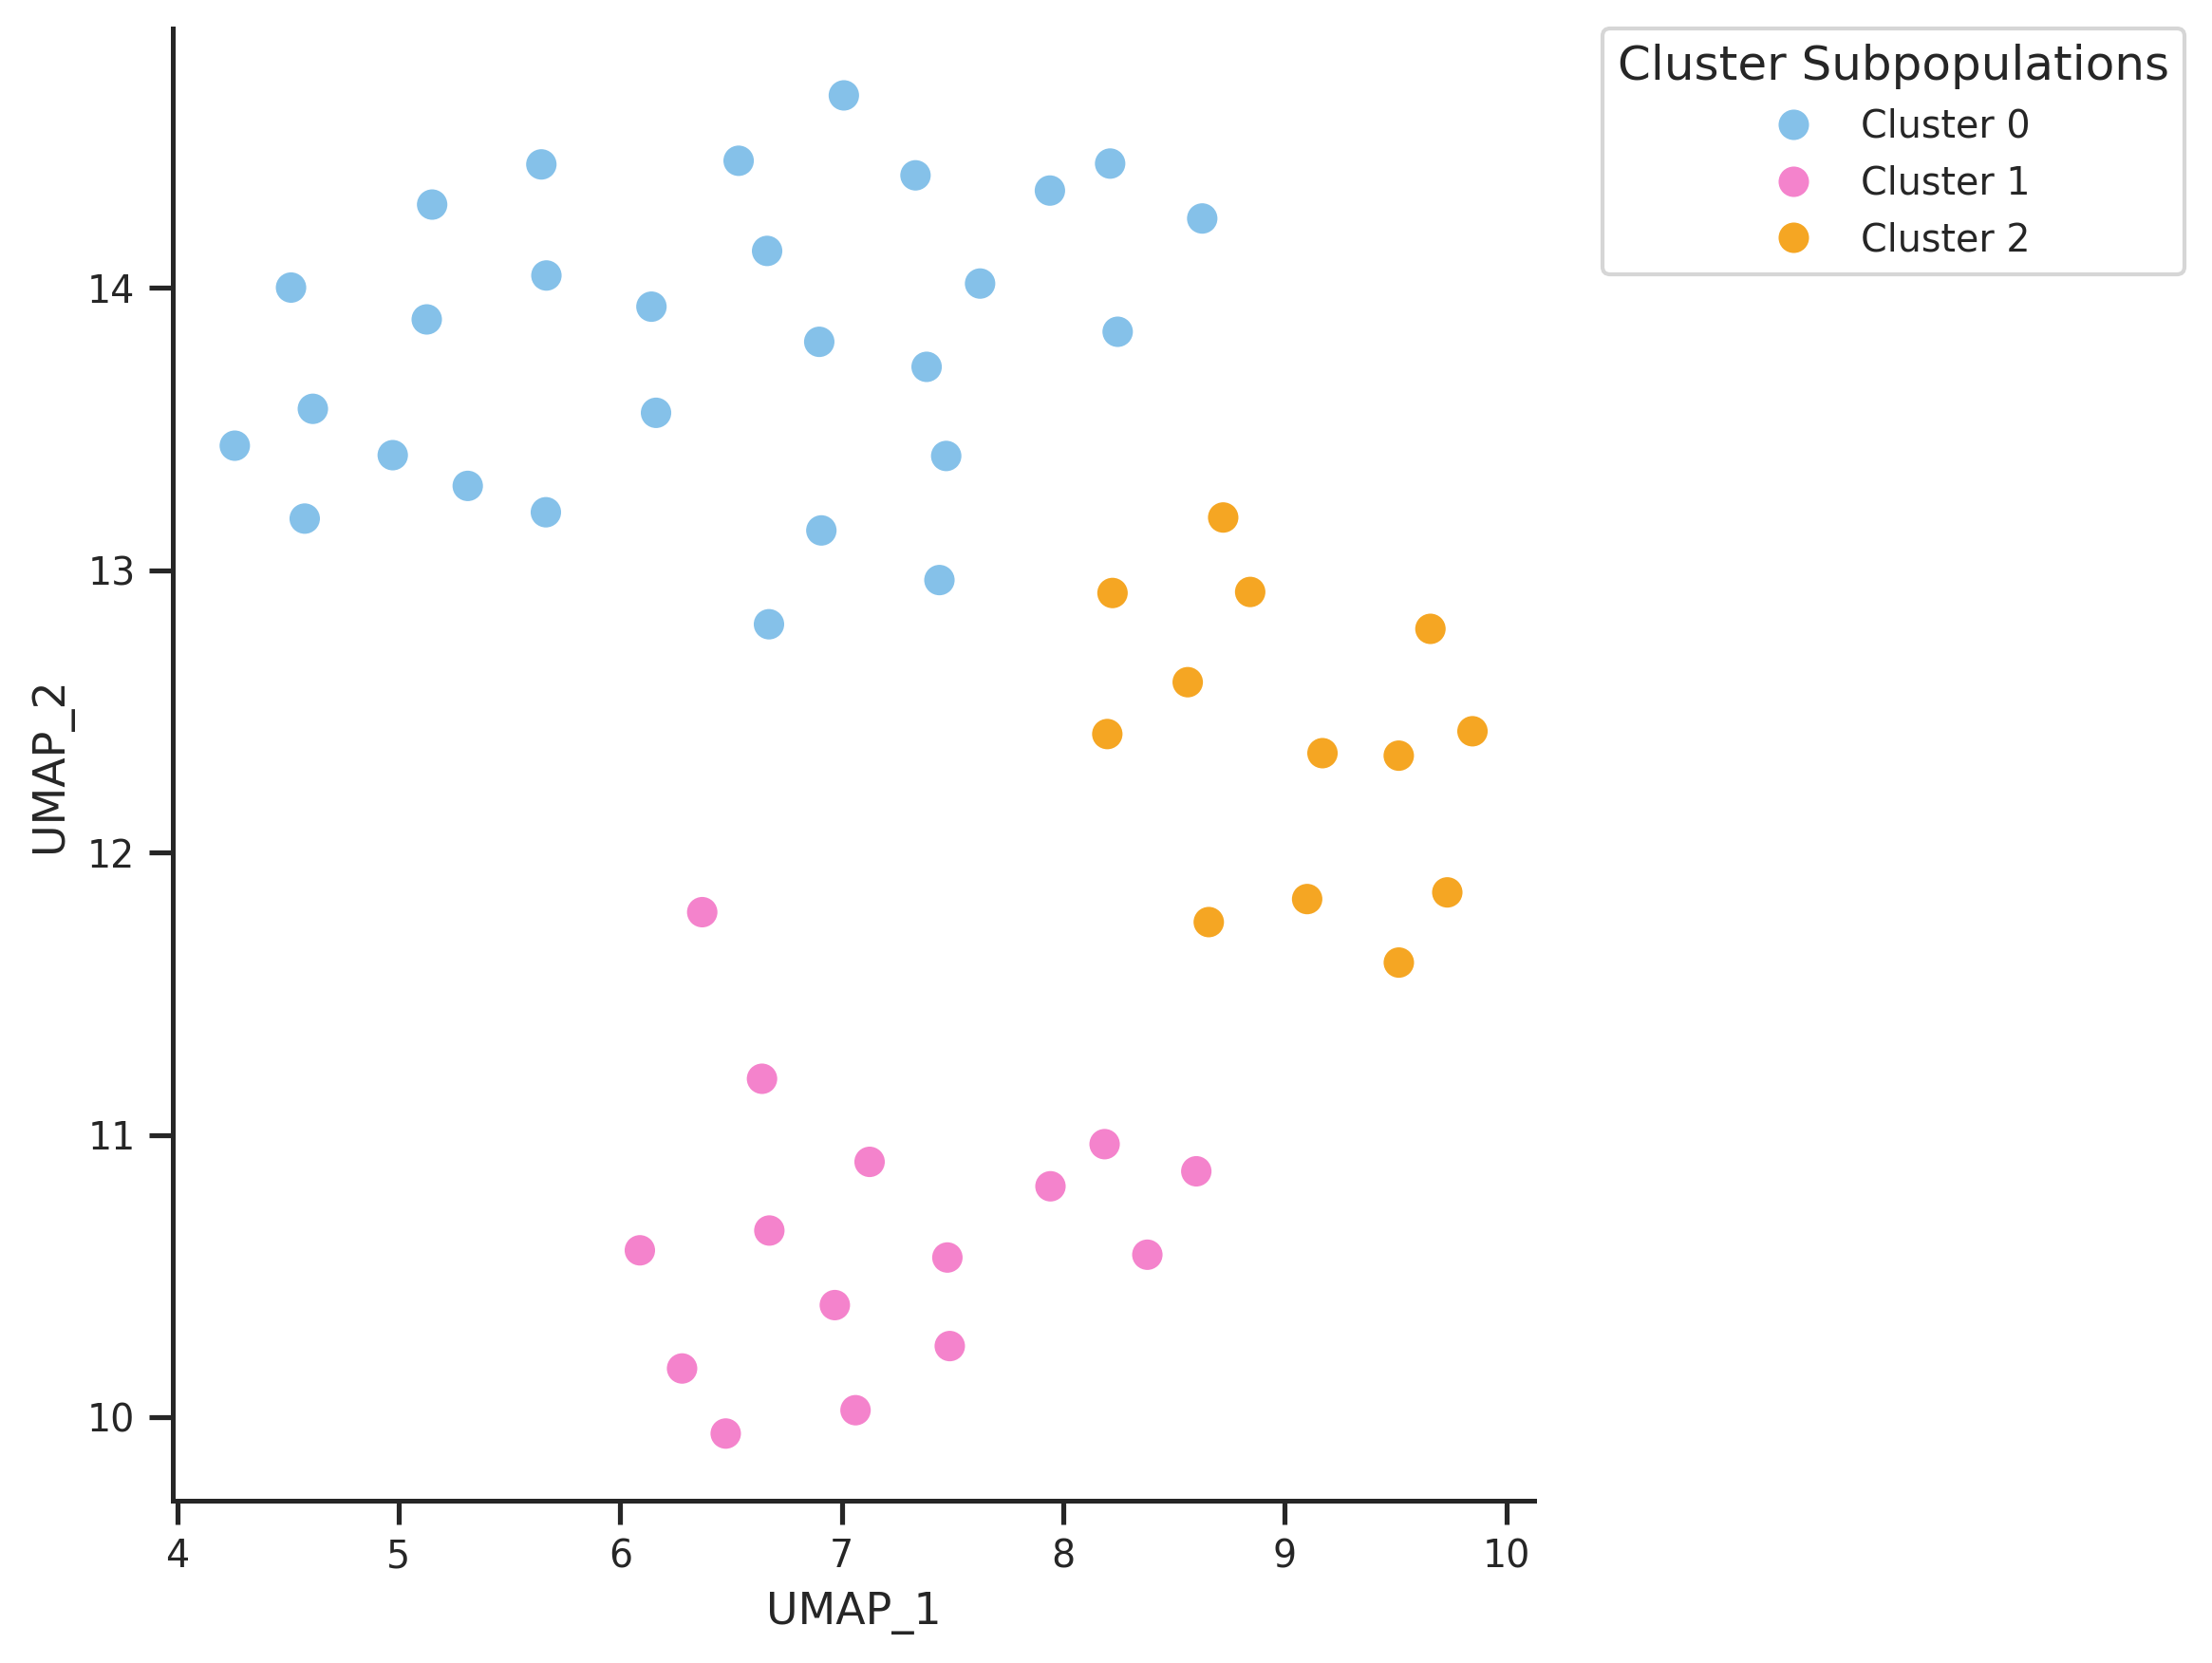

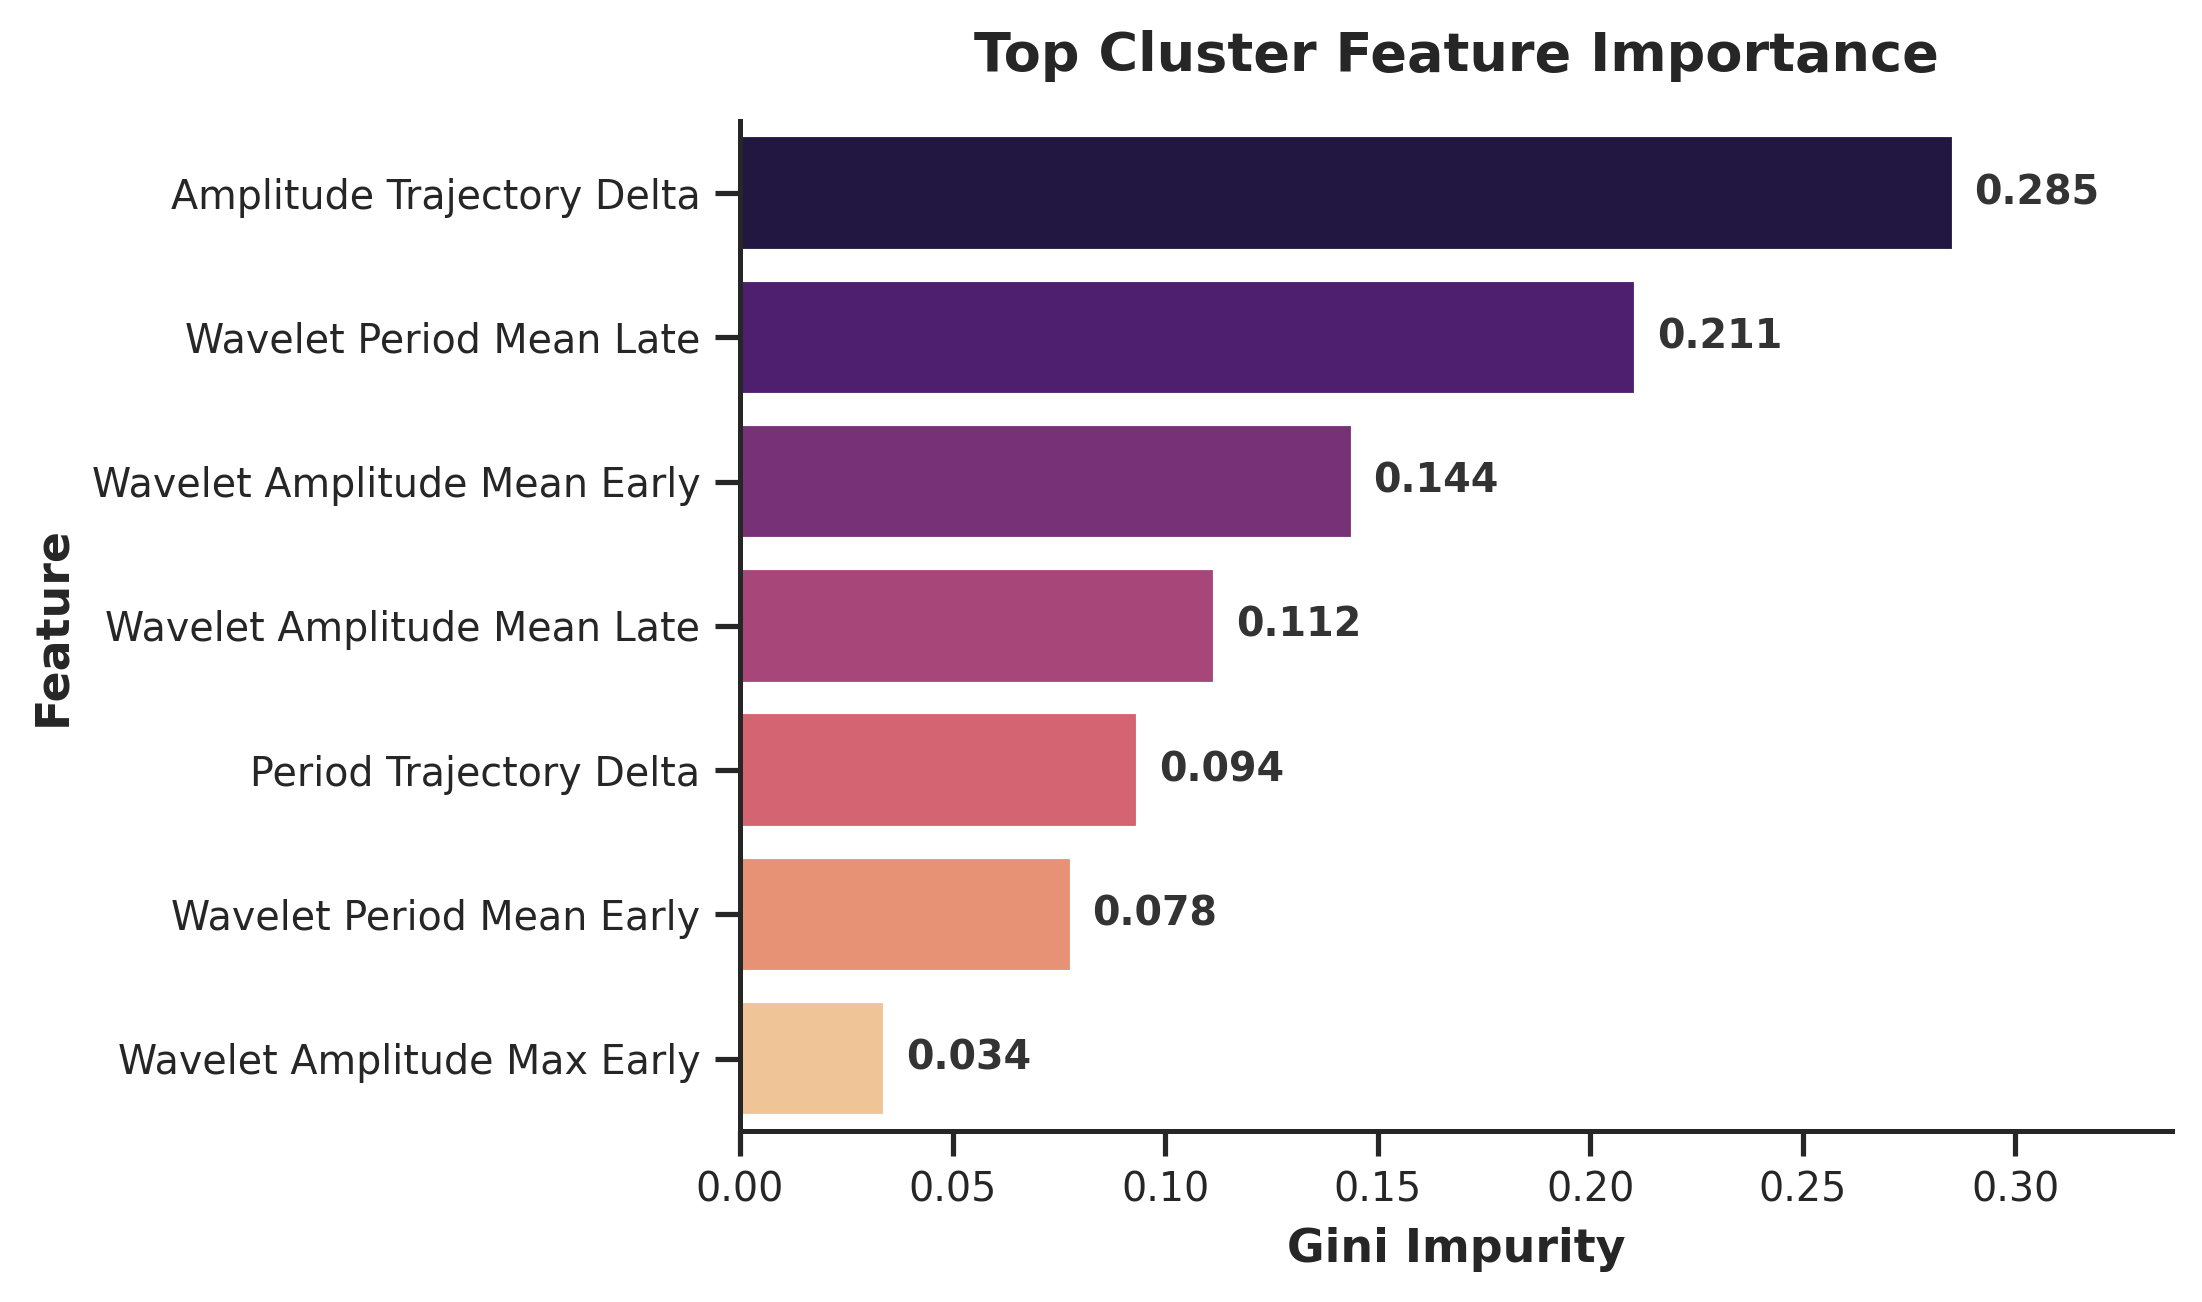

In [ ]:

# ==============================================================================
# CONFIGURATION (Adjusted for Neurons / MIOm1 + Well Correction)
# ==============================================================================
CONFIG = {
    'n_clusters':3,
    'stimulus_onset': 40.0,  # 60.0s for Neuronas and MIOm1
    'min_cycles_per_window': 1.0,  # Window rigor for Neurons
    'coi_factor': 1.414,  # Factor for Morlet wavelet
    'use_spectral_only_for_clustering': True,
    'apply_intra_well_norm': True,  # Enables intra-well Z-score standardization
    'pca_variance_target': 0.85,
    'collinearity_threshold': 0.85,
    'linkage': 'ward',
    'umap_neighbors': 15,
    'umap_min_dist': 0.2,
    'title_font_size_global': 13,
    'label_font_size_global': 11,
    'tick_font_size_global': 9.5,
    'axis_line_width_global': 1.2,
    'legend_label_font_size_global': 9.5,
    'dpi_global': 300,
    'cell_type_global': 'Cluster',
    'cluster_color_map_global': {
        0: '#85C1E9',
        1: '#F483CC',
        2: '#F5A623',
        3: '#2CA02C',
        -1: '#808080',
    },
}


class PureWaveletSegmentedExtractor(BaseEstimator, TransformerMixin):

    def __init__(
        self,
        stimulus_onset=60.0,
        min_cycles_per_window=1.0,
        coi_factor=1.414
    ):
        self.stimulus_onset = stimulus_onset
        self.min_cycles_per_window = min_cycles_per_window
        self.coi_factor = coi_factor
        self.split_t = None

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        t_col = next(
            (c for c in ['time', 'Time', 'time_sec', 't'] if c in X.columns),
            None,
        )
        if t_col is None:
            raise ValueError("Time column ('time') not found.")

        time_arr = X[t_col].values.astype(float)
        total_duration = float(np.nanmax(time_arr))
        dt = time_arr[1] - time_arr[0] if len(time_arr) > 1 else 1.0

        t_min_global = np.min(time_arr)
        t_max_global = np.max(time_arr)

        split_t = (
            self.stimulus_onset + (total_duration - self.stimulus_onset) / 2.0
        )
        self.split_t = split_t

        suffixes = [
            '_raw',
            '_norm',
            '_delta_f_f0',
            '_detrended',
            '_detrend',
            '_periods',
            '_phase',
            '_power',
            '_amplitude',
        ]
        cell_ids = set()
        for col in X.columns:
            if col == t_col:
                continue
            for s in suffixes:
                if col.endswith(s):
                    cell_ids.add(col[: -len(s)])
                    break

        segments = [
            ('basal', time_arr < self.stimulus_onset),
            (
                'early',
                (time_arr >= self.stimulus_onset) & (time_arr < split_t),
            ),
            ('late', time_arr >= split_t),
        ]

        extracted = []
        for cell_id in sorted(list(cell_ids)):
            feat = {'cell_id': cell_id}
            detrend_col = next(
                (
                    f'{cell_id}{s}'
                    for s in ['_detrended', '_detrend', '_delta_f_f0']
                    if f'{cell_id}{s}' in X.columns
                ),
                None,
            )
            raw_col = f'{cell_id}_raw'
            basal_mask = time_arr < self.stimulus_onset

            if detrend_col:
                detrend_sig = X[detrend_col].values.astype(float)
            elif raw_col in X.columns:
                r_sig = X[raw_col].values.astype(float)
                f0 = (
                    np.nanmedian(r_sig[basal_mask])
                    if np.any(basal_mask)
                    else 1.0
                )
                f0_val = f0 if (pd.notna(f0) and f0 > 0) else 1e-4
                detrend_sig = (r_sig - f0_val) / f0_val
            else:
                detrend_sig = np.zeros_like(time_arr)

            per_col = f'{cell_id}_periods'
            amp_col = f'{cell_id}_amplitude'
            pow_col = f'{cell_id}_power'

            per_arr = (
                X[per_col].values.astype(float)
                if per_col in X.columns
                else np.full_like(time_arr, np.nan)
            )

            # Direct acquisition of Linear Amplitude (or conversion from power)
            if amp_col in X.columns:
                amp_arr = X[amp_col].values.astype(float)
            elif pow_col in X.columns:
                amp_arr = np.sqrt(
                    np.maximum(0.0, X[pow_col].values.astype(float))
                )
            else:
                amp_arr = np.full_like(time_arr, np.nan)

            basal_std = 1e-4

            for seg_name, seg_t_mask in segments:
                sig_seg = detrend_sig[seg_t_mask]
                seg_time = time_arr[seg_t_mask]
                seg_duration = float(np.sum(seg_t_mask) * dt)

                if len(sig_seg) > 0 and not np.all(np.isnan(sig_seg)):
                    std_val = float(np.nanstd(sig_seg))
                    feat[f'detrend_std_{seg_name}'] = std_val
                    feat[f'detrend_skewness_{seg_name}'] = float(
                        skew(sig_seg, nan_policy='omit')
                    )
                    if seg_name == 'basal':
                        basal_std = std_val if std_val > 0 else 1e-4
                else:
                    feat[f'detrend_std_{seg_name}'] = 0.0
                    feat[f'detrend_skewness_{seg_name}'] = 0.0

                if seg_name in ['early', 'late']:
                    if len(seg_time) > 0:
                        max_window_period = (
                            seg_duration / self.min_cycles_per_window
                        )
                        dist_to_edge = np.minimum(
                            time_arr - t_min_global, t_max_global - time_arr
                        )

                        # COI filter and strictly applied window rigor
                        valid_coi_mask = (
                            seg_t_mask
                            & (~np.isnan(per_arr))
                            & (per_arr <= max_window_period)
                            & (dist_to_edge >= self.coi_factor * per_arr)
                        )

                        if np.any(valid_coi_mask):
                            valid_periods = per_arr[valid_coi_mask]
                            valid_amps = amp_arr[valid_coi_mask]

                            feat[f'has_oscillation_{seg_name}'] = 1.0
                            feat[f'wavelet_period_mean_{seg_name}'] = float(
                                np.nanmean(valid_periods)
                            )
                            feat[f'wavelet_period_std_{seg_name}'] = float(
                                np.nanstd(valid_periods)
                            )
                            feat[f'wavelet_amplitude_mean_{seg_name}'] = float(
                                np.nanmean(valid_amps)
                            )
                            feat[f'wavelet_amplitude_max_{seg_name}'] = float(
                                np.nanmax(valid_amps)
                            )
                        else:
                            # Imputation of actual background for Amplitude
                            seg_amp_vals = amp_arr[seg_t_mask]
                            seg_amp_vals = seg_amp_vals[
                                ~np.isnan(seg_amp_vals)
                            ]
                            bg_amp_mean = (
                                float(np.mean(seg_amp_vals))
                                if len(seg_amp_vals) > 0
                                else 0.0
                            )
                            bg_amp_max = (
                                float(np.max(seg_amp_vals))
                                if len(seg_amp_vals) > 0
                                else 0.0
                            )

                            feat[f'has_oscillation_{seg_name}'] = 0.0
                            feat[f'wavelet_period_mean_{seg_name}'] = (
                                np.nan  # Subsequent imputation by median
                            )
                            feat[f'wavelet_period_std_{seg_name}'] = 0.0
                            feat[f'wavelet_amplitude_mean_{seg_name}'] = (
                                bg_amp_mean
                            )
                            feat[f'wavelet_amplitude_max_{seg_name}'] = (
                                bg_amp_max
                            )
                    else:
                        feat[f'has_oscillation_{seg_name}'] = 0.0
                        feat[f'wavelet_period_mean_{seg_name}'] = np.nan
                        feat[f'wavelet_period_std_{seg_name}'] = 0.0
                        feat[f'wavelet_amplitude_mean_{seg_name}'] = 0.0
                        feat[f'wavelet_amplitude_max_{seg_name}'] = 0.0

            std_e, std_l = (
                feat['detrend_std_early'],
                feat['detrend_std_late'],
            )
            feat['snr_early_vs_basal_log2fc'] = float(
                np.log2((std_e**2 + 1e-6) / (basal_std**2 + 1e-6))
            )
            feat['snr_late_vs_basal_log2fc'] = float(
                np.log2((std_l**2 + 1e-6) / (basal_std**2 + 1e-6))
            )

            p_e, p_l = (
                feat['wavelet_period_mean_early'],
                feat['wavelet_period_mean_late'],
            )
            a_e, a_l = (
                feat['wavelet_amplitude_mean_early'],
                feat['wavelet_amplitude_mean_late'],
            )

            # Continuous trajectories
            feat['period_trajectory_delta'] = (
                float(p_l - p_e)
                if (pd.notna(p_l) and pd.notna(p_e))
                else np.nan
            )
            feat['amplitude_trajectory_delta'] = (
                float(a_l - a_e)
                if (pd.notna(a_l) and pd.notna(a_e))
                else 0.0
            )

            extracted.append(feat)

        return pd.DataFrame(extracted)


def normalize_by_well(df, feature_cols, cell_id_col='cell_id'):
    """Standardizes numeric features within each well using Z-score.

    Subtracts the well mean and divides by its standard deviation to mitigate
    batch effects inherent to multi-well bioimaging.
    """
    df_norm = df.copy()

    # Identify the well ID from the cellular identifier (e.g., 'well2_cell15' -> 'well2')
    df_norm['well_id'] = df_norm[cell_id_col].apply(
        lambda x: str(x).split('_')[0] if '_' in str(x) else 'well_1'
    )

    for col in feature_cols:
        well_means = df_norm.groupby('well_id')[col].transform('mean')
        well_stds = df_norm.groupby('well_id')[col].transform('std')

        # Control to avoid division by zero in homogeneous or constant wells
        well_stds = well_stds.replace(0, 1.0).fillna(1.0)

        # Apply intra-well Z-score preserving NaNs for later imputation
        df_norm[col] = (df_norm[col] - well_means) / well_stds

    return df_norm.drop(columns=['well_id'])


def run_pipeline(df_raw, config=CONFIG):
    extractor = PureWaveletSegmentedExtractor(
        stimulus_onset=config['stimulus_onset'],
        min_cycles_per_window=config['min_cycles_per_window'],
        coi_factor=config.get('coi_factor', 1.414),
    )
    df_feat = extractor.transform(df_raw)

    globals().update({
        'stimulus_onset_time_global': config['stimulus_onset'],
        'post_stimulus_split_time_global': extractor.split_t,
        'title_font_size_global': config['title_font_size_global'],
        'label_font_size_global': config['label_font_size_global'],
        'tick_font_size_global': config['tick_font_size_global'],
        'axis_line_width_global': config['axis_line_width_global'],
        'legend_label_font_size_global': config[
            'legend_label_font_size_global'
        ],
        'dpi_global': config['dpi_global'],
        'cell_type_global': config['cell_type_global'],
        'cluster_color_map_global': config['cluster_color_map_global'],
    })

    # Filter spectral features keeping only valid metrics
    if config.get('use_spectral_only_for_clustering', True):
        feat_cols = [
            c
            for c in df_feat.columns
            if c != 'cell_id'
            and ('wavelet' in c or 'trajectory' in c or 'snr' in c)
            and not any(
                kw in c
                for kw in [
                    'std_basal',
                    'std_early',
                    'std_late',
                    'skewness',
                    'has_oscillation',
                ]
            )
        ]
    else:
        feat_cols = [
            c
            for c in df_feat.columns
            if c != 'cell_id' and 'has_oscillation' not in c
        ]

    # =========================================================================
    # BATCH EFFECT CORRECTION: Intra-Well Normalization (Z-Score)
    # =========================================================================
    if config.get('apply_intra_well_norm', True):
        df_feat_norm = normalize_by_well(
            df_feat, feat_cols, cell_id_col='cell_id'
        )
        X = df_feat_norm[feat_cols].copy()
    else:
        X = df_feat[feat_cols].copy()

    # Imputation of missing values using the median
    imputer = SimpleImputer(strategy='median')
    X_imputed = imputer.fit_transform(X)
    df_imputed = pd.DataFrame(X_imputed, columns=feat_cols)

    vt = VarianceThreshold(threshold=0.0001)
    X_vt = vt.fit_transform(df_imputed)
    selected_features = np.array(feat_cols)[vt.get_support()]

    df_vt = pd.DataFrame(X_vt, columns=selected_features)
    corr_matrix = df_vt.corr().abs()
    upper_tri = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    thresh = config.get('collinearity_threshold', 0.85)
    to_drop = [
        column
        for column in upper_tri.columns
        if any(upper_tri[column] > thresh)
    ]

    selected_features = [c for c in selected_features if c not in to_drop]
    X_filtered = df_vt[selected_features].values

    scaler = PowerTransformer(method='yeo-johnson')
    X_scaled = scaler.fit_transform(X_filtered)

    n_samples, n_features = X_scaled.shape
    if min(n_samples, n_features) > 2:
        pca = PCA(
            n_components=config['pca_variance_target'],
            svd_solver='full',
            random_state=42,
        )
        X_pca = pca.fit_transform(X_scaled)
    else:
        X_pca = X_scaled

    n_clusters = min(config['n_clusters'], n_samples)
    clustering = AgglomerativeClustering(
        n_clusters=n_clusters, linkage=config['linkage']
    )
    df_feat['cluster'] = clustering.fit_predict(X_pca)

    if HAS_UMAP:
        reducer = umap.UMAP(
            n_neighbors=min(config['umap_neighbors'], n_samples - 1),
            min_dist=config['umap_min_dist'],
            n_components=2,
            random_state=42,
        )
        proj_label = 'UMAP'
    else:
        reducer = TSNE(
            n_components=2,
            random_state=42,
            perplexity=min(15, max(2, n_samples - 1)),
        )
        proj_label = 't-SNE'

    embedding = reducer.fit_transform(X_pca)
    df_feat['UMAP_1'] = embedding[:, 0]
    df_feat['UMAP_2'] = embedding[:, 1]

    rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        class_weight='balanced',
        random_state=42,
    )
    rf.fit(X_filtered, df_feat['cluster'])
    importances = pd.DataFrame({
        'feature': selected_features,
        'importance': rf.feature_importances_,
    }).sort_values('importance', ascending=False)

    return df_feat, importances, proj_label, X_pca


# ==============================================================================
# EXECUTION AND VISUALIZATION
# ==============================================================================
df_feat, importances, proj_label, X_pca = run_pipeline(df_raw, CONFIG)

title_font_size = globals().get('title_font_size_global', 13)
label_font_size = globals().get('label_font_size_global', 11)
tick_font_size = globals().get('tick_font_size_global', 9.5)
axis_line_width = globals().get('axis_line_width_global', 1.2)
legend_label_font_size = globals().get('legend_label_font_size_global', 9.5)
dpi_val = globals().get('dpi_global', 300)
cell_type = globals().get('cell_type_global', 'Neurona')

cluster_color_map = globals().get(
    'cluster_color_map_global',
    {0: '#85C1E9', 1: '#F483CC', 2: '#F5A623', 3: '#2CA02C', -1: '#808080'},
)

plt.rcParams.update({
    'font.size': tick_font_size,
    'axes.labelsize': label_font_size,
    'xtick.labelsize': tick_font_size,
    'ytick.labelsize': tick_font_size,
    'legend.fontsize': legend_label_font_size,
    'axes.titlesize': title_font_size,
    'axes.linewidth': axis_line_width,
    'lines.linewidth': axis_line_width,
})
sns.set_theme(style='ticks')

plt.close('all')

# FIGURE 1: UMAP / t-SNE Projection
df_feat['cluster_label'] = df_feat['cluster'].apply(
    lambda c: f'{cell_type} {c}'
)
df_plot = df_feat.sort_values('cluster')

unique_clusters_in_plot = sorted(df_plot['cluster'].unique())
palette_dict = {
    f'{cell_type} {c}': cluster_color_map.get(c, '#808080')
    for c in unique_clusters_in_plot
}

fig, ax = plt.subplots(figsize=(8, 6), dpi=dpi_val)

sns.scatterplot(
    data=df_plot,
    x='UMAP_1',
    y='UMAP_2',
    hue='cluster_label',
    palette=palette_dict,
    s=70,
    edgecolor='w',
    ax=ax,
)

ax.legend(
    title=f'{cell_type} Subpopulations',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    borderaxespad=0.0,
    frameon=True,
    fontsize=legend_label_font_size,
)

ax.set_xlabel(f'{proj_label}_1', fontsize=label_font_size)
ax.set_ylabel(f'{proj_label}_2', fontsize=label_font_size)
ax.tick_params(axis='both', which='major', labelsize=tick_font_size)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_linewidth(axis_line_width)

plt.tight_layout()
plt.show()
plt.close(fig)

# FIGURE 2: Feature Importance (Amplitude and Periods)
fig2, ax2 = plt.subplots(figsize=(7.5, 4.5), dpi=dpi_val)
top_features = importances.head(7).copy()

if not top_features.empty and top_features['importance'].max() > 0:
    top_features['display_feature'] = (
        top_features['feature'].str.replace('_', ' ').str.title()
    )

    bars = sns.barplot(
        data=top_features,
        x='importance',
        y='display_feature',
        hue='display_feature',
        palette='magma',
        legend=False,
        ax=ax2,
    )

    max_imp = top_features['importance'].max()
    for p in bars.patches:
        width = p.get_width()
        if width > 0:
            ax2.annotate(
                f'{width:.3f}',
                (width, p.get_y() + p.get_height() / 2.0),
                ha='left',
                va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=tick_font_size,
                fontweight='bold',
                color='#333333',
            )

    ax2.set_title(
        f'Top {cell_type} Feature Importance',
        fontweight='bold',
        fontsize=title_font_size,
        pad=12,
    )
    ax2.set_xlabel(
        'Gini Impurity', fontweight='bold', fontsize=label_font_size
    )
    ax2.set_ylabel('Feature', fontweight='bold', fontsize=label_font_size)
    ax2.set_xlim(0, max_imp * 1.18)
    ax2.tick_params(axis='both', which='major', labelsize=tick_font_size)

    for spine in ['top', 'right']:
        ax2.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax2.spines[spine].set_linewidth(axis_line_width)

    sns.despine(ax=ax2)

plt.tight_layout()
plt.show()
plt.close(fig2)


#BLOCK 4: Data Upload and Description 📊

## Visualization of Feature Importance for Cluster Discrimination

This block trains a simple classifier to predict hierarchical cluster labels based on the designed features. The classifier's feature importance can be interpreted as a measure of how discriminatory the features are for the identified clusters.

##Determining the Optimal Number of Clusters for Hierarchical Clustering
This code block calculates the silhouette score for different numbers of clusters in hierarchical clustering to help determine the optimal number of clusters.

--- Evaluando Número Óptimo de Clusters & Dendrograma (Ajustado) ---
Éxito: La evaluación de clusters se realiza utilizando la matriz X_pca (datos PCA-reducidos), asegurando consistencia con el modelo de agrupación.


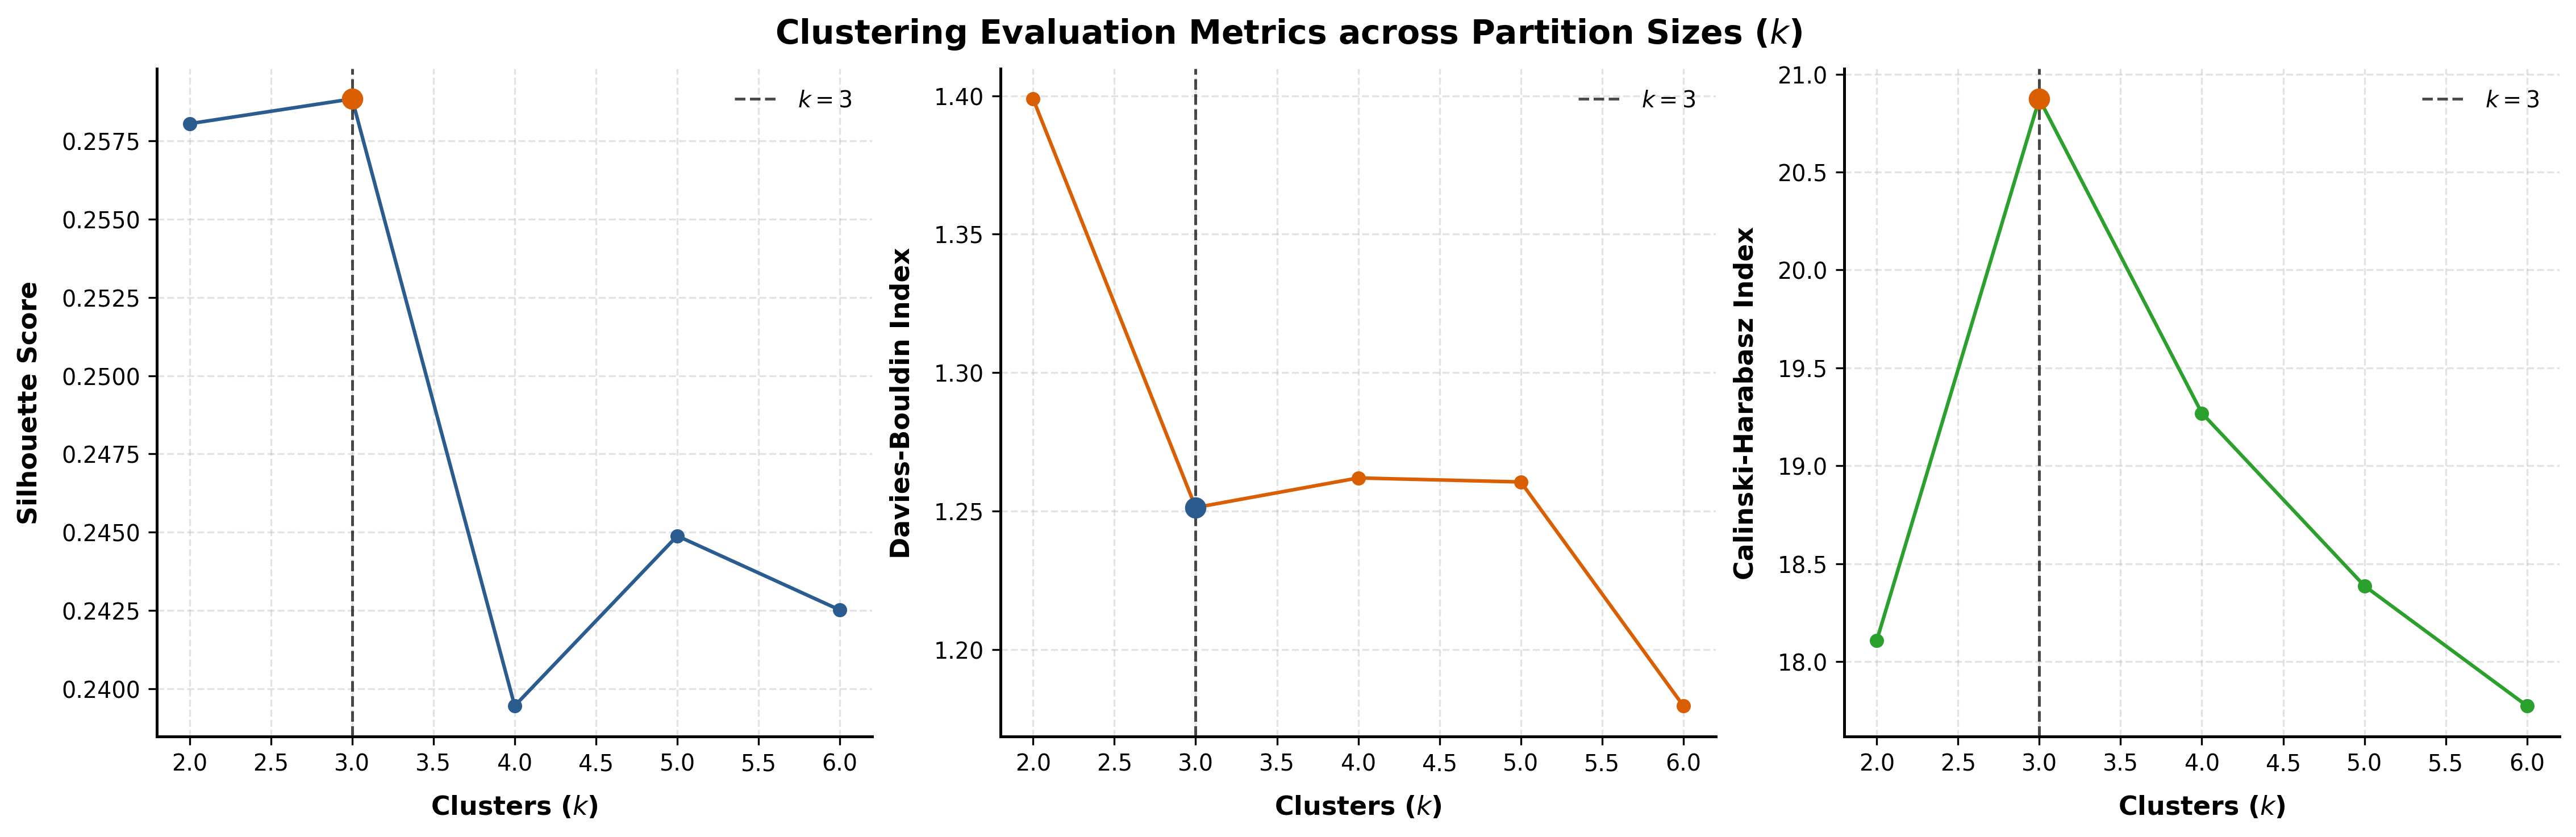

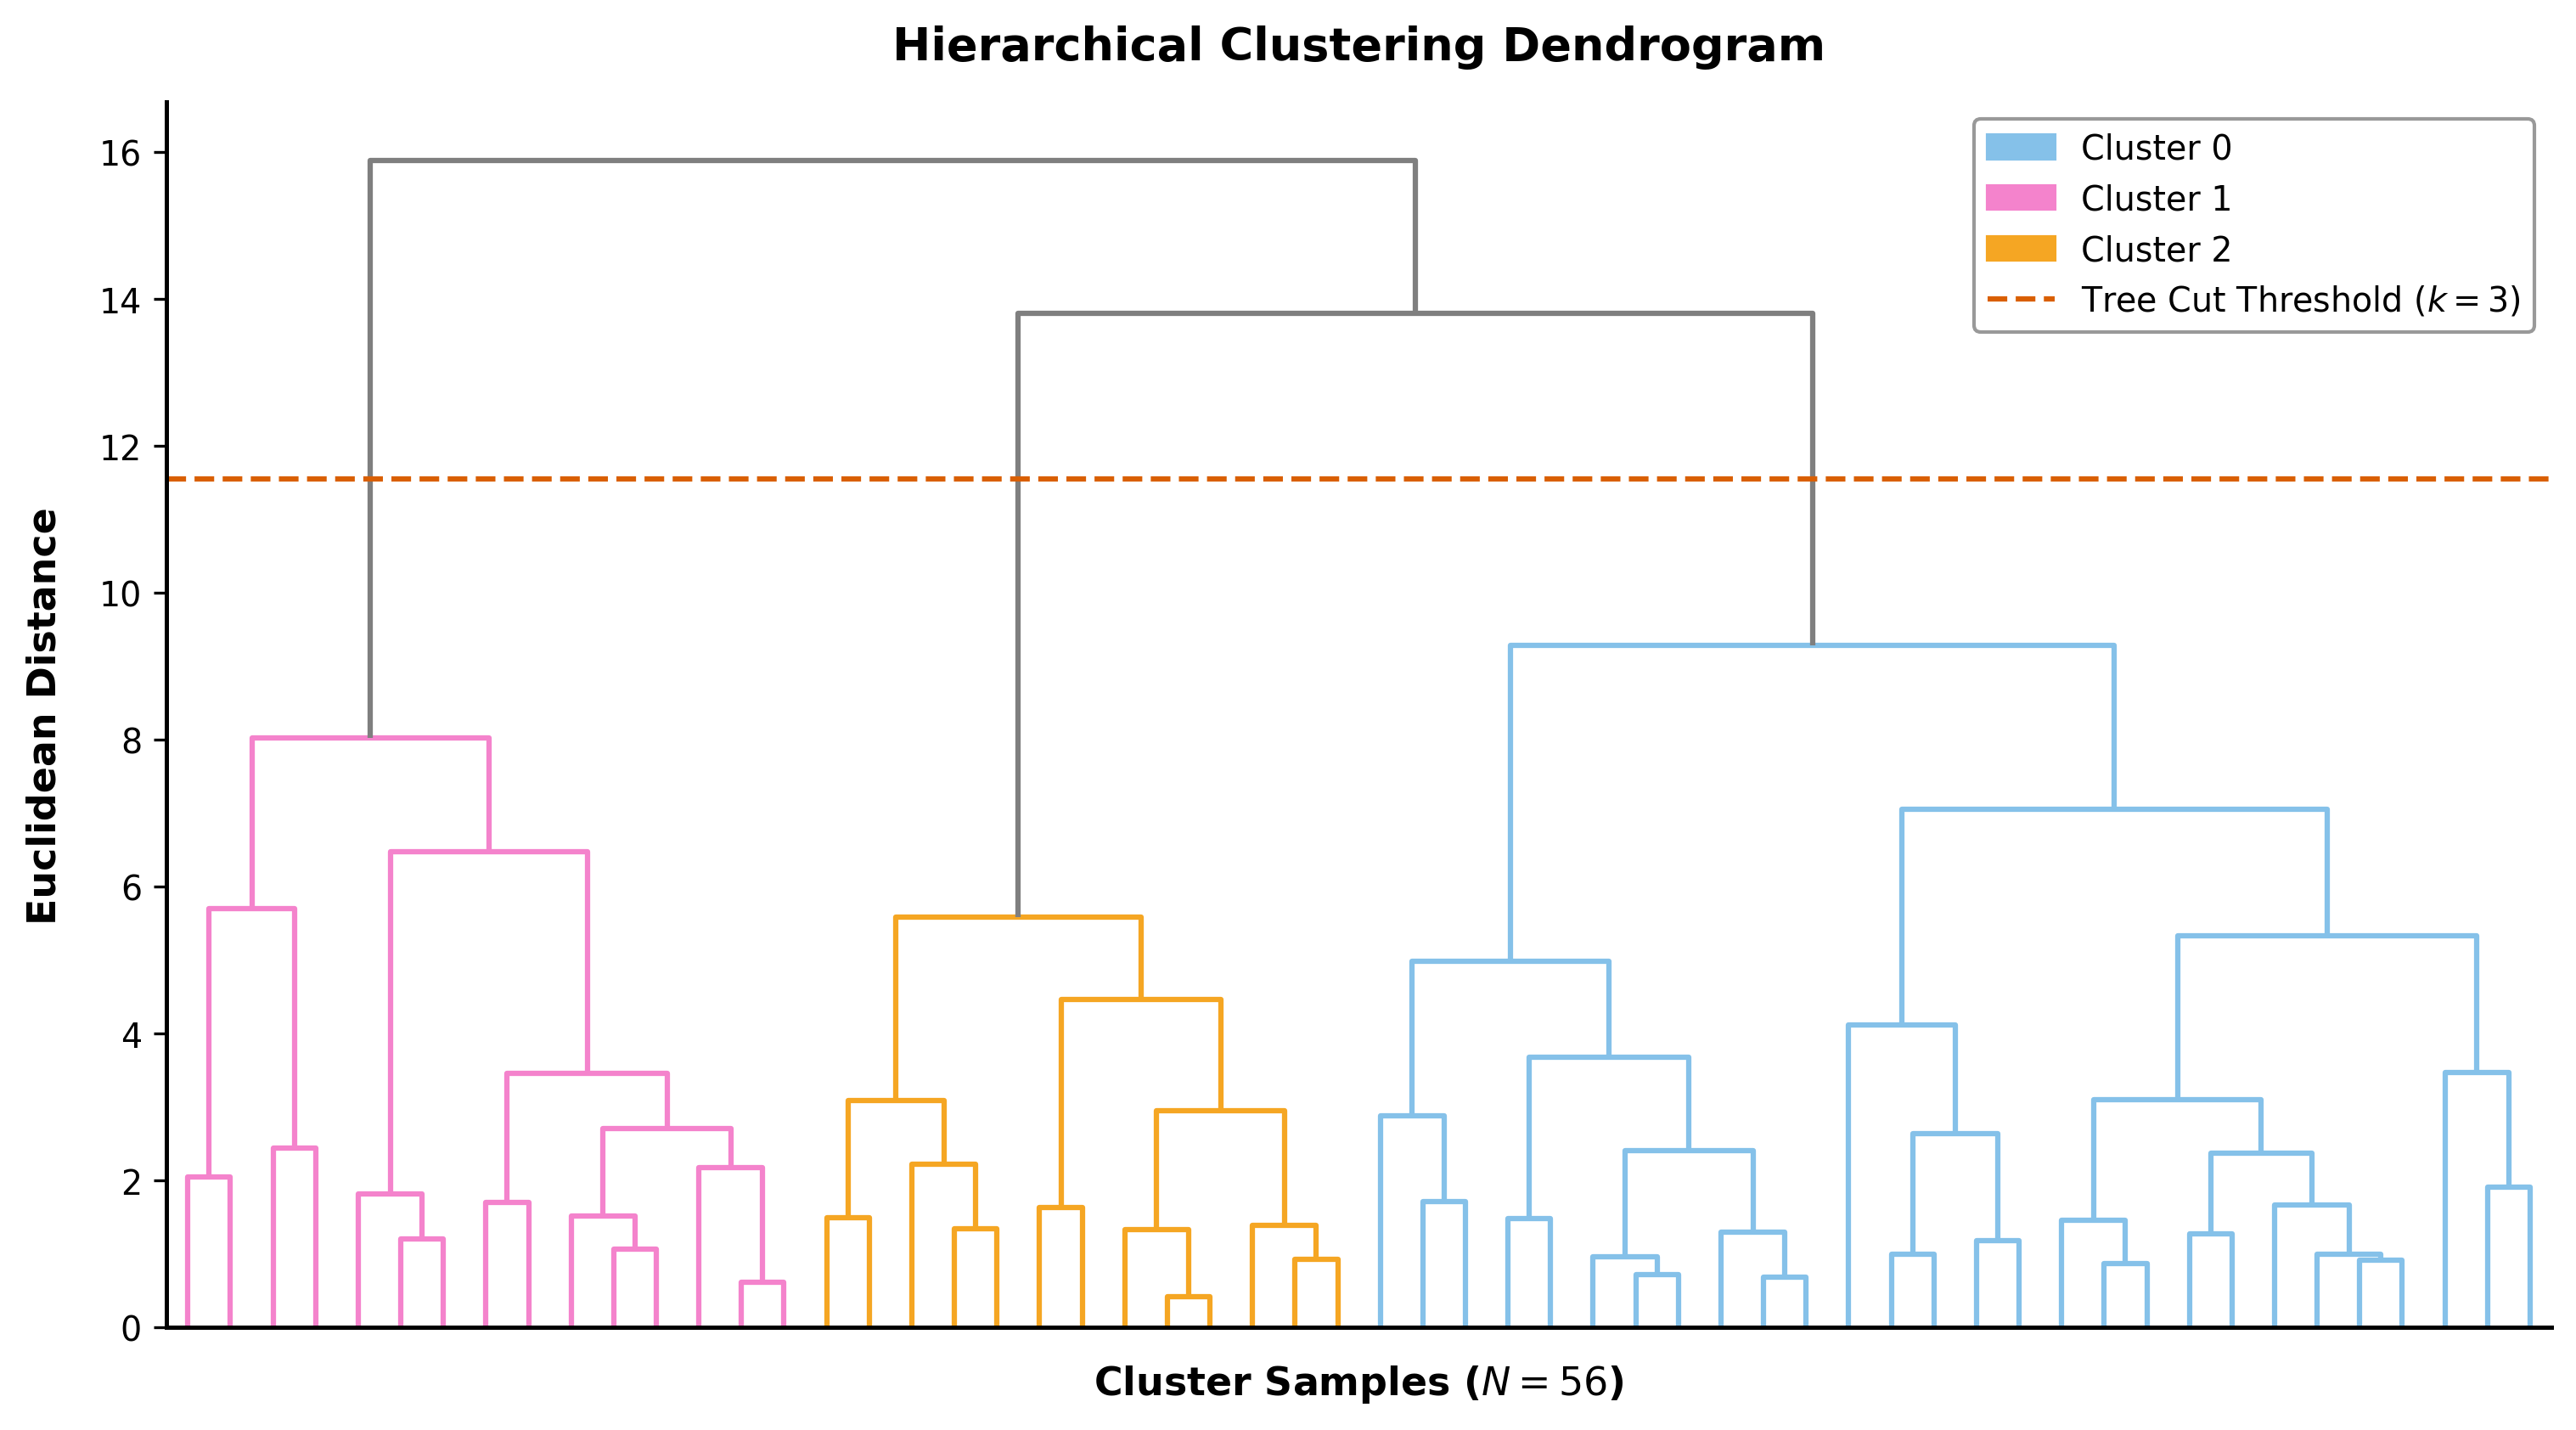

In [ ]:

print("--- Evaluating Optimal Number of Clusters & Dendrogram (Adjusted) ---")

# 0. Reset default styles to avoid visual conflicts
plt.rcParams.update(plt.rcParamsDefault)

# 1. Robust retrieval of parameters and feature matrix
config_dict = globals().get('CONFIG', {})
n_clusters_global = config_dict.get('n_clusters', 3)
linkage_m = config_dict.get('linkage', 'ward')

# Unified palette exactly aligned with the global map
c_map = globals().get(
    'cluster_color_map_global',
    {0: '#85C1E9', 1: '#F483CC', 2: '#F5A623', 3: '#2CA02C', -1: '#808080'}
)

# Retrieve clustering matrix X from the global environment
X_for_clustering = None
used_data_source_name = "Undefined"

for var_name in ['X_pca', 'X_pca_for_dendrogram', 'X_scaled']:
    if var_name in globals() and getattr(globals()[var_name], 'ndim', 0) == 2:
        X_for_clustering = globals()[var_name]
        used_data_source_name = var_name
        break

# Fallback: if the matrix does not exist in globals, try to build it from df_feat
if X_for_clustering is None and 'df_feat' in globals():
    df_feat_ref = globals()['df_feat']
    ignore_cols = ['cell_id', 'cluster', 'cluster_legend', 'Proj_1', 'Proj_2', 'cluster_label']
    feat_cols = [c for c in df_feat_ref.columns if c not in ignore_cols]
    if len(feat_cols) > 0:
        X_for_clustering = df_feat_ref[feat_cols].values
        used_data_source_name = "df_feat (fallback)"

# Report the data source used
if used_data_source_name == "X_pca":
    print("Success: The cluster evaluation is performed using the X_pca matrix (PCA-reduced data), ensuring consistency with the grouping model.")
elif used_data_source_name == "df_feat (fallback)":
    print("Warning: The cluster evaluation is using df_feat (raw variables) as a fallback. This can lead to metrics and dendrograms inconsistent with the grouping performed in X_pca.")
elif used_data_source_name == "Undefined":
    print("Error: No data matrix (X_pca, X_pca_for_dendrogram, X_scaled, or df_feat) could be found for clustering.")
else:
    print(f"Using the '{used_data_source_name}' matrix for cluster evaluation.")


if X_for_clustering is not None and len(X_for_clustering) >= 2:
    N = len(X_for_clustering)
    t_fs = globals().get('title_font_size_global', 12)
    l_fs = globals().get('label_font_size_global', 10)
    tk_fs = globals().get('tick_font_size_global', 8.5)
    ax_lw = globals().get('axis_line_width_global', 1.0)
    dpi_val = globals().get('dpi_global', 300)
    cell_type_global = globals().get('cell_type_global', 'Cellular')

    try:
        # 2. Hierarchical Linkage Matrix
        linked_matrix = linkage(X_for_clustering, method=linkage_m)
        globals()['linked_matrix'] = linked_matrix

        # Adaptive evaluation range based on the number of samples (N)
        max_k = min(N - 1, max(n_clusters_global + 3, 6))

        if max_k >= 2:
            range_k = list(range(2, max_k + 1))
            sil_scores, db_scores, ch_scores = [], [], []

            # 3. Calculation of Diagnostic Metrics
            for k in range_k:
                labels_k = fcluster(linked_matrix, k, criterion='maxclust') - 1

                if len(np.unique(labels_k)) > 1:
                    sil_scores.append(silhouette_score(X_for_clustering, labels_k))
                    db_scores.append(davies_bouldin_score(X_for_clustering, labels_k))
                    ch_scores.append(calinski_harabasz_score(X_for_clustering, labels_k))
                else:
                    sil_scores.append(0.0)
                    db_scores.append(0.0)
                    ch_scores.append(0.0)

            # 4. Rendering of Tripartite Evaluation Plots
            fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.8), dpi=dpi_val, layout='constrained')
            selected_idx = range_k.index(n_clusters_global) if n_clusters_global in range_k else None

            # Silhouette Score
            ax1.plot(range_k, sil_scores, marker='o', linewidth=ax_lw + 0.3, color='#2B5C8F', markersize=5)
            if selected_idx is not None:
                ax1.plot(n_clusters_global, sil_scores[selected_idx], marker='o', color='#D95F02', markersize=8, zorder=5)
            ax1.axvline(x=n_clusters_global, color='black', linestyle='--', alpha=0.7, linewidth=1.2, label=f'$k={n_clusters_global}$')
            ax1.set_xlabel('Clusters ($k$)', fontsize=l_fs, fontweight='bold', labelpad=8)
            ax1.set_ylabel('Silhouette Score', fontsize=l_fs, fontweight='bold', labelpad=8)
            ax1.grid(True, linestyle='--', alpha=0.35)
            ax1.legend(fontsize=tk_fs, frameon=False)

            # Davies-Bouldin Index
            ax2.plot(range_k, db_scores, marker='o', linewidth=ax_lw + 0.3, color='#D95F02', markersize=5)
            if selected_idx is not None:
                ax2.plot(n_clusters_global, db_scores[selected_idx], marker='o', color='#2B5C8F', markersize=8, zorder=5)
            ax2.axvline(x=n_clusters_global, color='black', linestyle='--', alpha=0.7, linewidth=1.2, label=f'$k={n_clusters_global}$')
            ax2.set_xlabel('Clusters ($k$)', fontsize=l_fs, fontweight='bold', labelpad=8)
            ax2.set_ylabel('Davies-Bouldin Index', fontsize=l_fs, fontweight='bold', labelpad=8)
            ax2.grid(True, linestyle='--', alpha=0.35)
            ax2.legend(fontsize=tk_fs, frameon=False)

            # Calinski-Harabasz Index
            ax3.plot(range_k, ch_scores, marker='o', linewidth=ax_lw + 0.3, color='#2CA02C', markersize=5)
            if selected_idx is not None:
                ax3.plot(n_clusters_global, ch_scores[selected_idx], marker='o', color='#D95F02', markersize=8, zorder=5)
            ax3.axvline(x=n_clusters_global, color='black', linestyle='--', alpha=0.7, linewidth=1.2, label=f'$k={n_clusters_global}$')
            ax3.set_xlabel('Clusters ($k$)', fontsize=l_fs, fontweight='bold', labelpad=8)
            ax3.set_ylabel('Calinski-Harabasz Index', fontsize=l_fs, fontweight='bold', labelpad=8)
            ax3.grid(True, linestyle='--', alpha=0.35)
            ax3.legend(fontsize=tk_fs, frameon=False)

            for ax in [ax1, ax2, ax3]:
                ax.tick_params(axis='both', labelsize=tk_fs)
                for spine in ['top', 'right']:
                    ax.spines[spine].set_visible(False)
                for spine in ['left', 'bottom']:
                    ax.spines[spine].set_linewidth(ax_lw)

            fig.suptitle('Clustering Evaluation Metrics across Partition Sizes ($k$)', fontsize=t_fs + 1, fontweight='bold')
            plt.savefig('clustering_metrics_evaluation.png', bbox_inches='tight', dpi=dpi_val)
            plt.show()

        # 5. Calculation of the Tree Cut Threshold
        if n_clusters_global > 1 and len(linked_matrix) >= (n_clusters_global - 1):
            dist_k = linked_matrix[-(n_clusters_global - 1), 2]
            dist_k_next = linked_matrix[-n_clusters_global, 2] if len(linked_matrix) >= n_clusters_global else 0.0
            threshold = (dist_k + dist_k_next) / 2.0
        else:
            threshold = 0.0

        # Synchronization of labels with df_feat
        if 'df_feat' in globals() and 'cluster' in globals()['df_feat'].columns:
            cluster_labels = np.array(globals()['df_feat']['cluster'], dtype=int)
        else:
            cluster_labels = fcluster(linked_matrix, n_clusters_global, criterion='maxclust') - 1

        # 6. Rendering of the Dendrogram
        fig, ax = plt.subplots(figsize=(10, 5.5), dpi=dpi_val, layout='constrained')

        # PALETTE CORRECTION: Extract leaves in visual order (left to right)
        # so that set_link_color_palette assigns the exact color to each subcluster.
        leaf_indices = leaves_list(linked_matrix)
        leaf_clusters = cluster_labels[leaf_indices]

        unique_clusters_in_order = []
        for k in leaf_clusters:
            if k not in unique_clusters_in_order and k >= 0:
                unique_clusters_in_order.append(k)

        palette_colors = [c_map.get(k, '#808080') for k in unique_clusters_in_order]
        sch.set_link_color_palette(palette_colors)

        sch.dendrogram(
            linked_matrix,
            orientation='top',
            no_labels=True,
            color_threshold=threshold,
            above_threshold_color='#7F7F7F',
            ax=ax,
        )

        # Reset global palette state in SciPy
        sch.set_link_color_palette(None)

        ax.axhline(
            y=threshold,
            color='#D95F02',
            linestyle='--',
            linewidth=1.5,
            label=f'Tree Cut Threshold ($k={n_clusters_global}$)',
        )

        ax.set_title('Hierarchical Clustering Dendrogram', fontsize=t_fs, fontweight='bold', pad=12)
        ax.set_ylabel('Euclidean Distance', fontsize=l_fs, fontweight='bold', labelpad=10)
        ax.set_xlabel(f'{cell_type_global} Samples ($N={N}$)', fontsize=l_fs, fontweight='bold', labelpad=10)

        # Building the legend sorted numerically by Cluster ID
        unique_clusters_sorted = sorted([k for k in np.unique(cluster_labels) if k >= 0])
        cluster_legend_handles = [
            mpatches.Patch(color=c_map.get(k, '#808080'), label=f'Cluster {k}')
            for k in unique_clusters_sorted
        ]

        all_handles = list(cluster_legend_handles)
        all_labels = [h.get_label() for h in all_handles]

        # Add threshold line if it exists
        if ax.lines and ax.lines[-1].get_label() == f'Tree Cut Threshold ($k={n_clusters_global}$)':
            all_handles.append(ax.lines[-1])
            all_labels.append(ax.lines[-1].get_label())

        ax.legend(
            handles=all_handles,
            labels=all_labels,
            fontsize=tk_fs,
            loc='upper right',
            frameon=True,
            facecolor='white',
            edgecolor='gray'
        )

        ax.tick_params(axis='both', labelsize=tk_fs)
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        for spine in ['left', 'bottom']:
            ax.spines[spine].set_linewidth(ax_lw)

        plt.savefig('dendrogram_synced.png', bbox_inches='tight', dpi=dpi_val)
        plt.show()

    except Exception as e:
        print(f'Error in cluster evaluation: {e}')


## Visualization of Clusters in UMAP Space

In [ ]:

# 1. Get df_feat generated by the model pipeline
df_plot = globals().get('df_feat')

if df_plot is None:
    raise ValueError(
        "Error: 'df_feat' not found. Ensure `run_pipeline(df_raw, CONFIG)` has been executed previously."
    )

df_plot = df_plot.copy()

# 2. Flexible retrieval and extraction of 'well' information
meta_working = globals().get('meta_working')

if 'well' not in df_plot.columns:
    # Case A: meta_working exists with the expected structure
    if (
        meta_working is not None
        and 'id_clean' in meta_working.columns
        and 'well_clean' in meta_working.columns
    ):
        df_plot['cell_id_str'] = df_plot['cell_id'].astype(str)
        meta_working['id_clean_str'] = meta_working['id_clean'].astype(str)
        cell_id_to_well = meta_working.set_index('id_clean_str')[
            'well_clean'
        ].to_dict()
        df_plot['well'] = df_plot['cell_id_str'].map(cell_id_to_well)

    # Case B: Extract 'well' directly from cell_id name if possible
    if 'well' not in df_plot.columns or df_plot['well'].isna().all():
        extracted_well = (
            df_plot['cell_id']
            .astype(str)
            .str.extract(r'(well\d+|W\d+|[A-H]\d+)', expand=False, flags=re.IGNORECASE)
        )
        df_plot['well'] = extracted_well.fillna('Well_1')

# Assign default label to possible missing null values
df_plot['well'] = df_plot['well'].fillna('Well_Unknown').astype(str)

# 3. Detect the original cluster column (numeric)
cluster_col = 'cluster' if 'cluster' in df_plot.columns else next(
    (c for c in ['cluster_label', 'hierarchical_cluster', 'k3_cluster'] if c in df_plot.columns),
    None
)

if cluster_col is None:
    raise ValueError("Error: No cluster column found in 'df_feat'.")

# Convert cluster to string for Plotly to apply discrete categorical colors
df_plot['cluster_str'] = df_plot[cluster_col].astype(str)

# Format the global color map for Plotly (convert keys to string)
c_map = globals().get('cluster_color_map_global', {})
plotly_color_map = {str(k): v for k, v in c_map.items()}

# 4. Create the interactive figure (UMAP scatter plot)
fig_umap = px.scatter(
    df_plot,
    x='UMAP_1',
    y='UMAP_2',
    color='cluster_str',
    symbol='well',
    hover_name='cell_id',
    hover_data={
        'cluster_str': True,
        'well': True,
        'UMAP_1': False,
        'UMAP_2': False,
    },
    title='Interactive UMAP of Cells by Cluster and Well',
    color_discrete_map=plotly_color_map if plotly_color_map else None,
    labels={
        'UMAP_1': 'UMAP 1',
        'UMAP_2': 'UMAP 2',
        'cluster_str': 'Cluster',
        'well': 'Well',
    },
)

fig_umap.update_layout(showlegend=True)
fig_umap.show()

# 5. Plot of cluster proportions by well
cluster_well_counts = (
    df_plot.groupby(['well', 'cluster_str']).size().unstack(fill_value=0)
)
cluster_well_proportions = cluster_well_counts.div(
    cluster_well_counts.sum(axis=1), axis=0
)

df_proportions = cluster_well_proportions.reset_index().melt(
    id_vars='well', var_name='cluster_str', value_name='proportion'
)

fig_proportions = px.bar(
    df_proportions,
    x='well',
    y='proportion',
    color='cluster_str',
    title='Cluster Proportion by Well',
    color_discrete_map=plotly_color_map if plotly_color_map else None,
    labels={'well': 'Well', 'proportion': 'Proportion', 'cluster_str': 'Cluster'},
    height=500,
)

fig_proportions.update_layout(yaxis_tickformat='.0%')
fig_proportions.show()

# 6. Chi-squared test for independence
print(f"\n--- Chi-squared Test for Independence of Clusters and Wells ---")

if cluster_well_counts.shape[0] > 1 and cluster_well_counts.shape[1] > 1:
    chi2, p_value, dof, expected = chi2_contingency(cluster_well_counts)
    print(f"Chi-squared Statistic: {chi2:.2f}")
    print(f"P-value: {p_value:.3e}")
    print(f"Degrees of Freedom: {dof}")

    if p_value < 0.05:
        print(
            "Conclusion: The P-value is less than 0.05, suggesting a statistically significant association "
            "between the distribution of clusters and wells (i.e., cluster distribution is NOT independent of the well)."
        )
    else:
        print(
            "Conclusion: The P-value is greater than 0.05, suggesting no statistically significant association "
            "between the distribution of clusters and wells (i.e., cluster distribution IS independent of the well)."
        )
else:
    print(
        "Warning: At least 2 wells and 2 different clusters are required to run the Chi-squared test."
    )


In [ ]:
# ==============================================================================
# WELL-BY-WELL EXPORT FOR FIJI (ALL CLUSTERS AND NUMERICAL ORDERING)
# ==============================================================================


def extract_well_name(cell_id):
    """Extracts the Well/Glass slide identifier."""
    match = re.search(
        r'^(.*?)(?:_Mean|_ROI|_cell|_roi|_c_?d+|_id\d+|\d+$)',
        str(cell_id),
        re.IGNORECASE,
    )
    if match and match.group(1):
        return match.group(1).rstrip('_')
    return str(cell_id).split('_')[0]


def extract_roi_num(cell_id):
    """Extracts the integer ROI number for correct sequential sorting."""
    nums = re.findall(r'\d+', str(cell_id))
    return int(nums[-1]) if nums else 0


# 1. Prepare the DataFrame with all cells (without filtering out any cluster)
df_mapeo_fiji = df_feat[['cell_id', 'cluster']].copy()
df_mapeo_fiji['cell_id'] = df_mapeo_fiji['cell_id'].astype(str).str.strip()
df_mapeo_fiji['well'] = df_mapeo_fiji['cell_id'].apply(extract_well_name)
df_mapeo_fiji['roi_num'] = df_mapeo_fiji['cell_id'].apply(extract_roi_num)

wells_unicos = sorted(df_mapeo_fiji['well'].unique())
print(
    f'Detected {len(wells_unicos)} wells/glass slides for Fiji export: {wells_unicos}'
)

# 2. Create output directory
os.makedirs('fiji_export_by_well_MIO', exist_ok=True)

# 3. Export CSV files grouped by well
for well in wells_unicos:
    # Filter by well and sort numerically using the ROI ID
    df_well = (
        df_mapeo_fiji[df_mapeo_fiji['well'] == well]
        .sort_values(by='roi_num')
        .reset_index(drop=True)
    )

    # Create mapping indices for ImageJ / Fiji (0-based and 1-based)
    df_well['fiji_roi_idx_0based'] = df_well.index
    df_well['fiji_roi_idx_1based'] = df_well.index + 1

    # Select final target columns for the macro execution
    df_well_export = df_well[[
        'cell_id',
        'roi_num',
        'fiji_roi_idx_0based',
        'fiji_roi_idx_1based',
        'cluster',
    ]]

    nombre_archivo = os.path.join(
        'fiji_export_by_well_MIO', f'mapeo_clusters_fiji_{well}.csv'
    )
    df_well_export.to_csv(nombre_archivo, index=False)
    print(
        f"  -> Saved '{nombre_archivo}' with {len(df_well_export)} ROIs (Clusters included: {sorted(df_well['cluster'].unique().tolist())})."
    )

print(
    "\nProcess completed. Output files are ready in the folder 'fiji_export_by_well_MIO/'."
)

## Visualization of Average Signals by Cluster and Cluster Distribution


--- Generando distribución de clústeres (K=3) ---


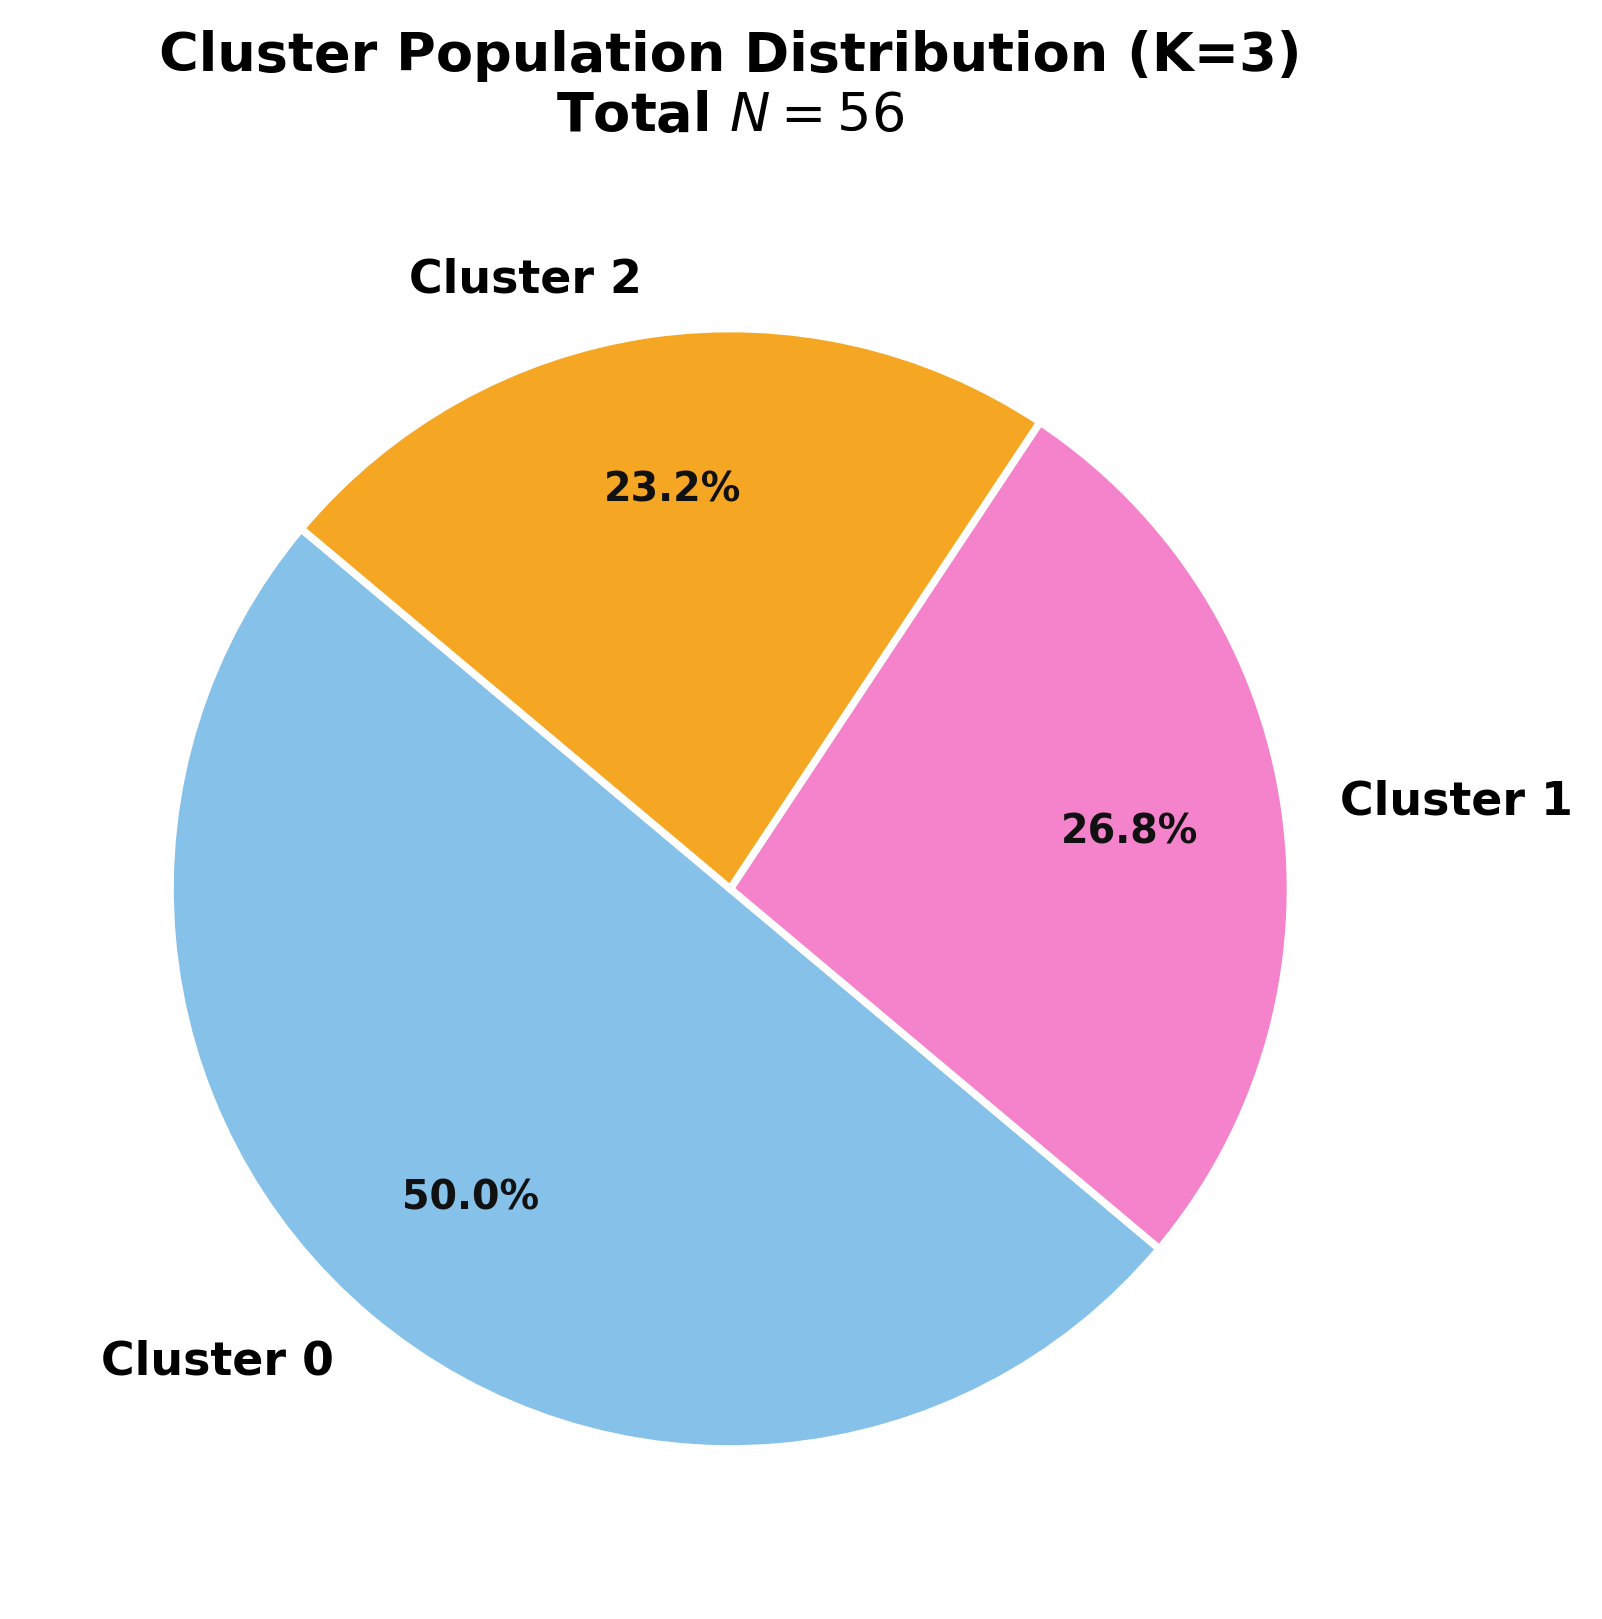

✅ Distribución calculada exitosamente (N=56):
cluster
0    28
1    15
2    13
Name: count, dtype: int64


In [ ]:

# Reset base Matplotlib parameters to avoid inheriting giant font sizes
plt.rcParams.update(plt.rcParamsDefault)


# ==============================================================================
# 1. ROBUST DATAFRAME AND CLUSTER COLUMN SELECTION
# ==============================================================================
df_target = None
cluster_col = None

# List of potential data sources in priority order
candidate_dfs = [
    'df_feat',
    'umap_df_pipeline',
    'df_output',
    'df_ridge_results',
    'df_umap',
    'df_clean',
]
candidate_cols = [
    'hierarchical_cluster',
    'cluster',
    'cluster_label',
    'k4_cluster',
    'k3_cluster',
    'Subensemble',
]

for df_name in candidate_dfs:
  df_obj = globals().get(df_name)
  if isinstance(df_obj, pd.DataFrame) and not df_obj.empty:
    for col in candidate_cols:
      if col in df_obj.columns:
        # Verify that the column contains more than a single value or valid values (>= 0)
        valid_vals = df_obj[col].dropna().unique()
        if len(valid_vals) > 1 or (
            len(valid_vals) == 1 and valid_vals[0] != -1
        ):
          df_target = df_obj
          cluster_col = col
          break
    if df_target is not None:
      break

# Fallback if no multi-cluster column was found
if df_target is None:
  for df_name in candidate_dfs:
    df_obj = globals().get(df_name)
    if isinstance(df_obj, pd.DataFrame) and not df_obj.empty:
      for col in candidate_cols:
        if col in df_obj.columns:
          df_target = df_obj
          cluster_col = col
          break
      if df_target is not None:
        break

if df_target is None or cluster_col is None:
  raise ValueError(
      "❌ Error: No valid DataFrame with cluster columns was found in memory."
  )

# ==============================================================================
# 2. COUNTING AND CHROMATIC MAPPING SYNCHRONIZED WITH THE MODEL
# ==============================================================================
# Counts cleaning and ordering
series_clusters = df_target[cluster_col].dropna()
cluster_counts = series_clusters.value_counts().sort_index()
total_n = len(series_clusters)
n_clusters_actual = len(cluster_counts) # Get actual number of clusters from data
if -1 in cluster_counts.index: # Adjust if -1 is a valid cluster (e.g., noise)
    n_clusters_actual -= 1

print(f"--- Generating cluster distribution (K={n_clusters_actual}) ---")

# Retrieve global chromatic palette, if it exists, or create a default one
c_map = globals().get('cluster_color_map_global', {})
if not c_map:
    # Default palette if global map not found or empty
    base_default_colors = ['#4FC3F7', '#E377C2', '#FF9900', '#2CA02C', '#9B59B6', '#F39C12']
    c_map = {i: base_default_colors[i % len(base_default_colors)] for i in range(n_clusters_actual)}
    c_map[-1] = '#808080' # Ensure inactive/QC is gray if it exists

labels, colors = [], []
for idx in cluster_counts.index:
  try:
    c_idx = int(idx)
  except (ValueError, TypeError):
    c_idx = str(idx)

  if c_idx == -1:
    labels.append('Inactive / QC (-1)')
  else:
    labels.append(f'Cluster {c_idx}')

  colors.append(c_map.get(c_idx, '#808080'))

# ==============================================================================
# 3. TYPOGRAPHICAL SCALING AND DONUT RENDERING
# ==============================================================================
# Strict size control to avoid visual clipping/overlapping
title_fs = globals().get('title_font_size_global', 13.0)
label_fs = globals().get('label_font_size_global', 10.0)
pct_fs = globals().get('tick_font_size_global', 9.5) # Using tick_font_size_global for percentage font size
dpi_val = globals().get('dpi_global', 300)
cell_type = globals().get('cell_type_global', 'Cellular')

fig, ax = plt.subplots(figsize=(5.5, 5.5), dpi=dpi_val)

wedges, texts, autotexts = ax.pie(
    cluster_counts,
    labels=labels,
    autopct='%1.1f%%',
    pctdistance=0.72,
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=1.0, edgecolor='white', linewidth=1.8), # Changed width to 1.0 for a full pie chart
    textprops={'fontsize': label_fs, 'fontweight': 'bold'},
)

# Style internal percentages
for autotext in autotexts:
  autotext.set_color('#111111')
  autotext.set_fontsize(pct_fs)
  autotext.set_fontweight('bold')

# Proportional Title
ax.set_title(
    f'{cell_type} Population Distribution (K={n_clusters_actual})\nTotal $N = {total_n}$',
    fontsize=title_fs,
    fontweight='bold',
    pad=14,
)

plt.tight_layout()
plt.savefig('cluster_distribution_pie.png', bbox_inches='tight', dpi=dpi_val)
plt.show()

print(f'✅ Distribution successfully calculated (N={total_n}):')
print(cluster_counts)

✅ Cargando señales desde DataFrame: 'df_raw'
✅ Found signals using suffix: '_detrended'

--- Verificación de Alineación Correcta ---
Células únicas asignadas por clúster:
clean_cluster
0    28
1    15
2    13
Name: col_id, dtype: int64


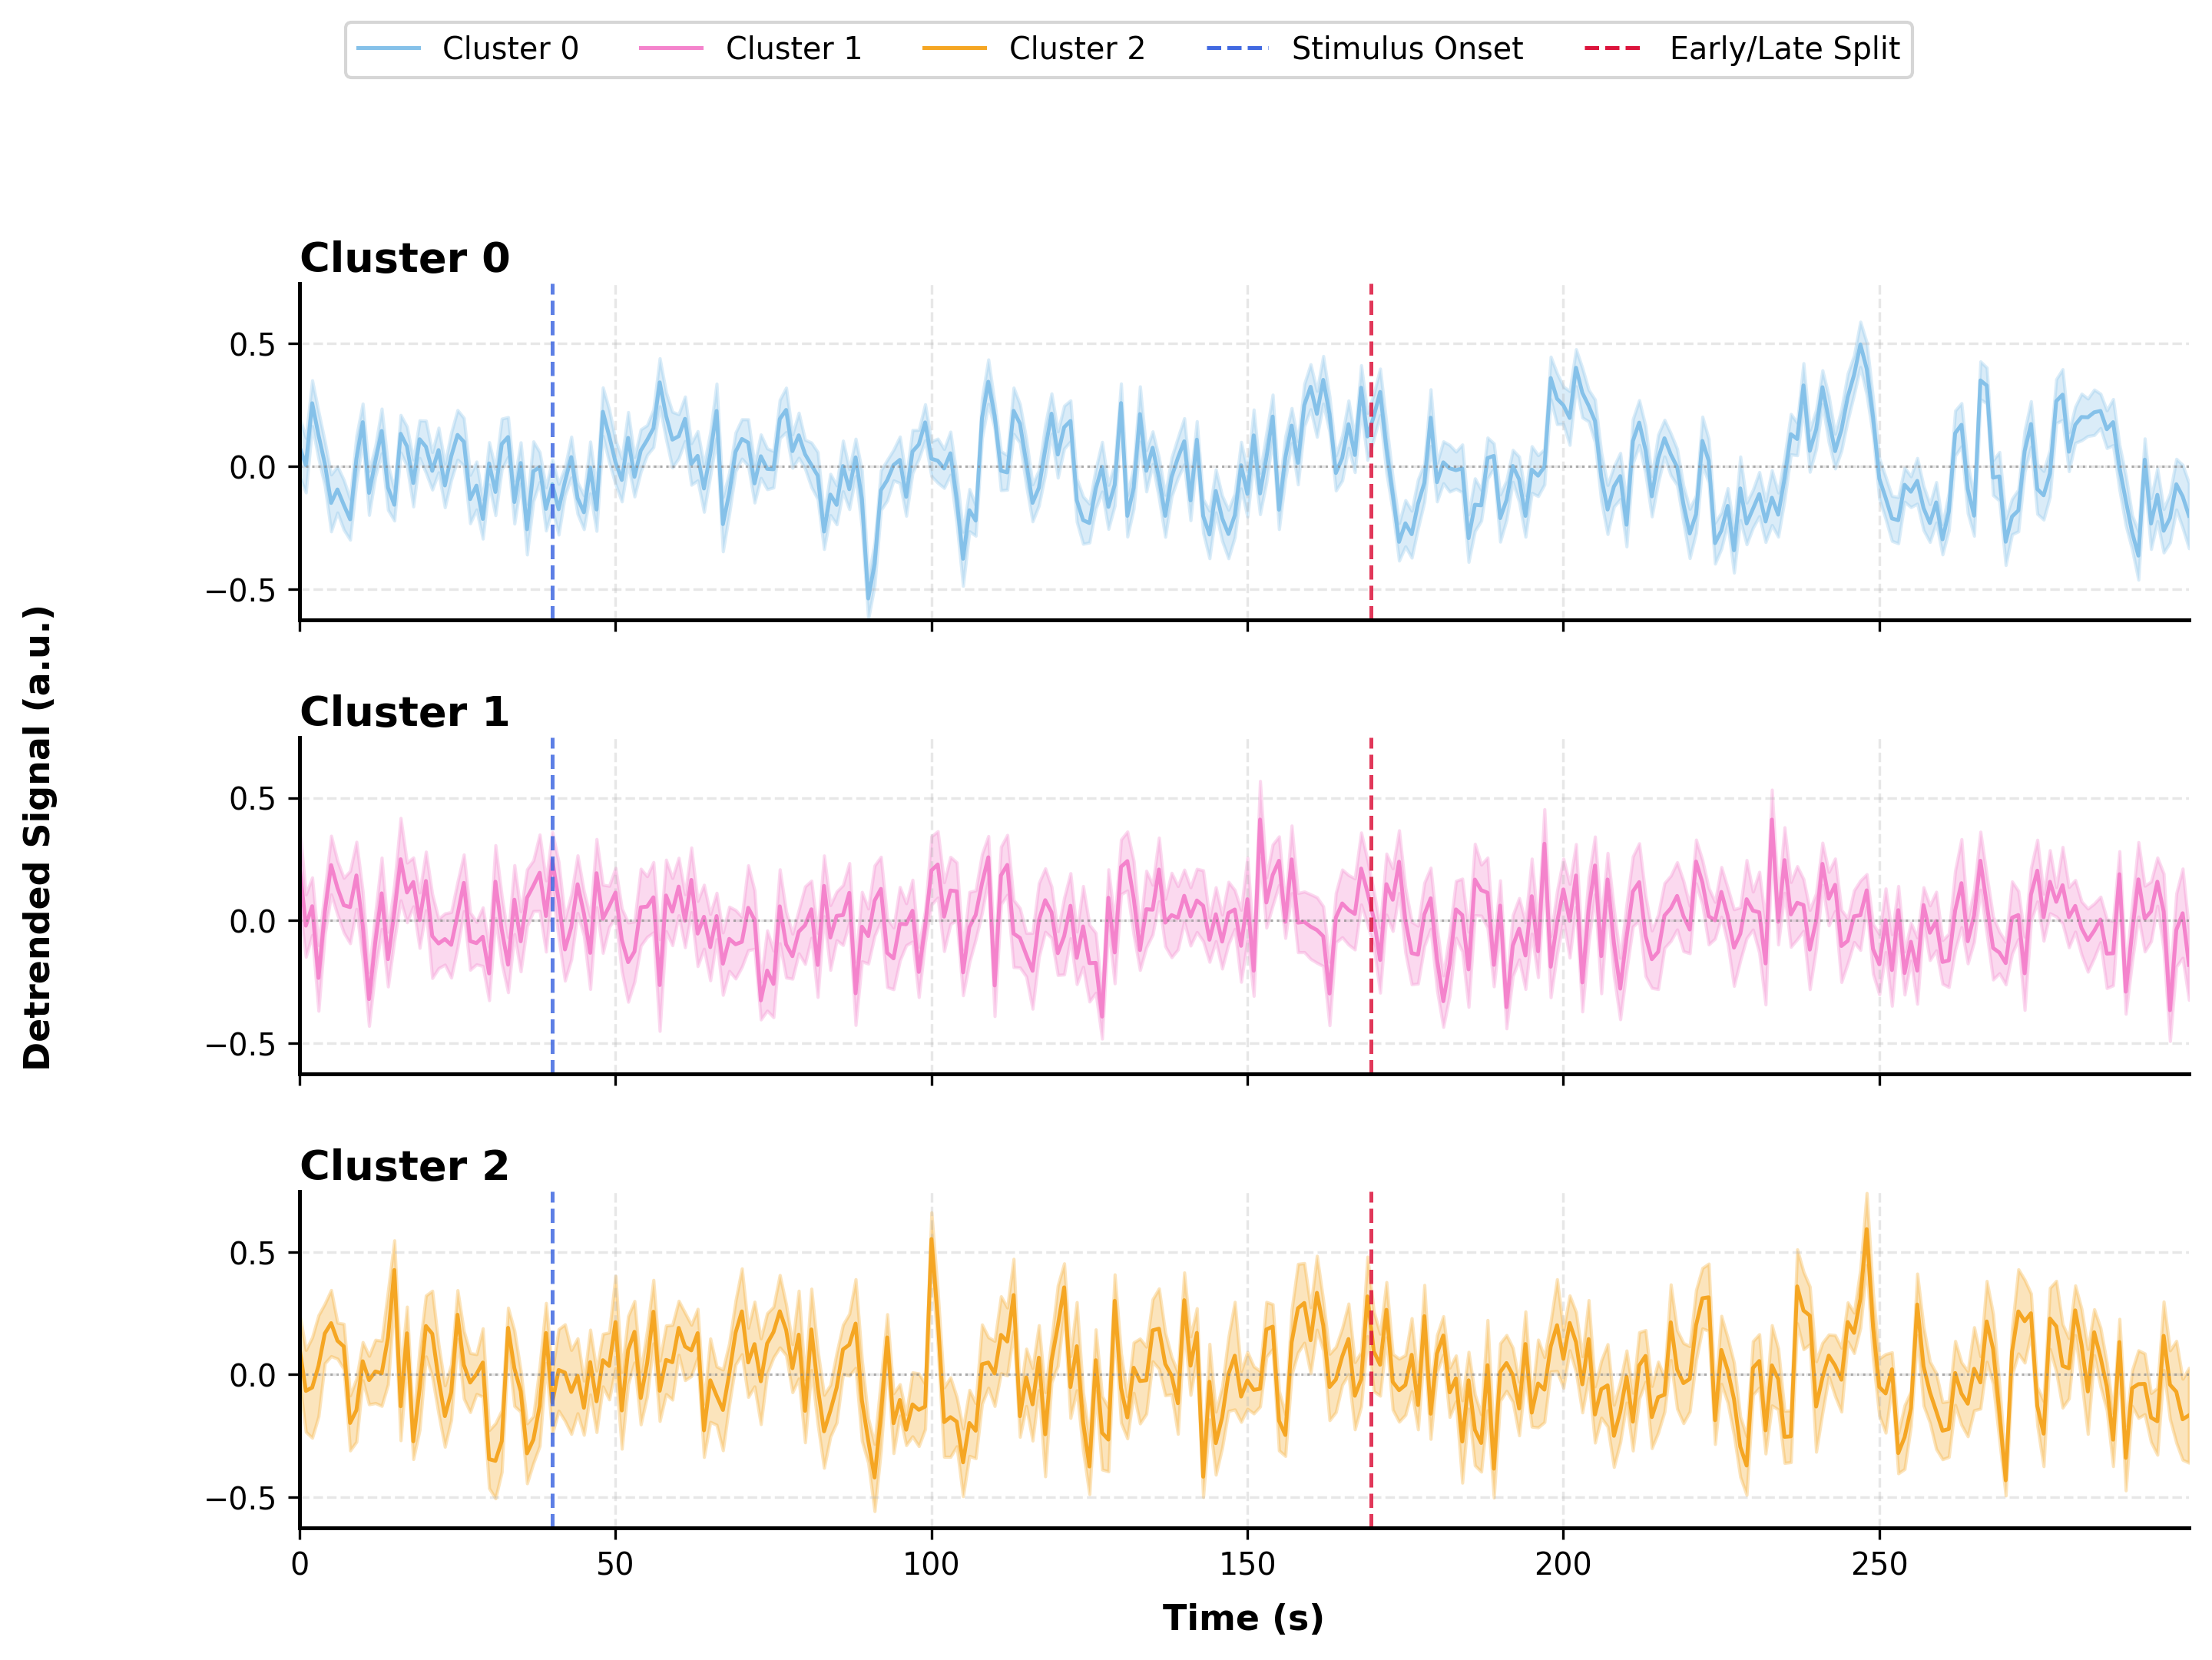

In [ ]:

# Reset parameters to avoid inheriting giant fonts from other blocks
plt.rcParams.update(plt.rcParamsDefault)


def extract_numeric_id(val):
  """Extracts the clean integer ID from any cell ID format."""
  if pd.isna(val):
    return None
  s = str(val).strip()
  numbers = re.findall(r'\d+', s)
  return int(numbers[-1]) if numbers else s.lower()


# ==============================================================================
# 1. PRIORITY SELECTION OF THE SIGNALS DATAFRAME
# ==============================================================================
df_signals = None
candidate_signal_dfs = [
    'df_raw', # Prioritize df_raw which contains the time series data
    'df_combined_all_features',  # Prefer this as it's typically the integrated one
    'df_feat', # Move df_feat down, as it contains features, not signals
    'df_detrended',
    'df_dff',
    'df_signals_detrended',
    'df_clean',
]

for name in candidate_signal_dfs:
  obj = globals().get(name)
  if isinstance(obj, pd.DataFrame) and not obj.empty:
    cols = [str(c).lower() for c in obj.columns]
    if 'time' in cols or any('roi' in c or 'cell' in c for c in cols):
      df_signals = obj
      print(f"✅ Loading signals from DataFrame: '{name}'")
      break

if df_signals is None:
  raise ValueError(
      '❌ Error: No valid processed signals DataFrame found in memory.'
  )

# Robust search for df_umap
df_umap = globals().get('umap_df_pipeline')

if df_umap is None:
    df_umap = globals().get('df_features_res') # Explicitly search for df_features_res

if df_umap is None:
  for var_name, obj in list(globals().items()):
    if (
        isinstance(obj, pd.DataFrame)
        and not obj.empty
        and any('cluster' in str(c).lower() for c in obj.columns)
    ):
      df_umap = obj
      break

if df_umap is None:
    raise ValueError(
        '❌ Error: No UMAP/Clusters DataFrame found in memory.'
    )

# ==============================================================================
# 2. COLUMN SELECTION FOR F/F0 AND MELT
# ==============================================================================
time_col = 'time' if 'time' in df_signals.columns else df_signals.columns[0]
stimulus_onset = globals().get('stimulus_onset_time_global', 60.0)
split_time = globals().get('post_stimulus_split_time_global', 172.0)
total_duration = df_signals[time_col].max()

# Prioritize _detrended, then _norm (F/F0), then _delta_f_f0 ((F-F0)/F0)
signal_cols_for_f_f0 = []
y_axis_label = 'Signal (a.u.)'  # Default label

# Prioritize '_detrended' as requested by the user
for suffix, label_text in [
    ('_detrended', 'Detrended Signal (a.u.)'),
    ('_norm', 'Normalized Signal (F/F0)'),
    ('_delta_f_f0', 'Normalized Signal (ΔF/F0)')
]:
    current_suffix_cols = [c for c in df_signals.columns if c.endswith(suffix)]
    if current_suffix_cols:
        signal_cols_for_f_f0 = current_suffix_cols
        y_axis_label = label_text
        print(f"✅ Found signals using suffix: '{suffix}'") # Updated print message
        break

if not signal_cols_for_f_f0:
    # Fallback if no specific detrended/F/F0 found
    # Removed suffixes already prioritized above
    detrend_suffixes = [
        '_clean', '_signal',
    ]
    signal_cols_for_f_f0 = [c for c in df_signals.columns if any(c.endswith(s) for s in detrend_suffixes)]
    if signal_cols_for_f_f0:
        y_axis_label = 'Detrended Signal (a.u.)'
        print("⚠️ Falling back to general detrended-like signals.")
    else:
        # Last resort: use all numeric columns except time (this is risky, might include raw)
        signal_cols_for_f_f0 = [c for c in df_signals.columns if c != time_col and pd.api.types.is_numeric_dtype(df_signals[c])]
        y_axis_label = 'Raw Signal (a.u.) - WARNING: Raw signals plotted.'
        print("❌ No specific detrended, F/F0, or general detrended-like signals found. Using all numeric columns (except time).")


df_signals_melted = df_signals.melt(
    id_vars=[time_col],
    value_vars=signal_cols_for_f_f0,
    var_name='col_id',
    value_name='signal_value',
)

# NOTE: Removed automatic F-F0 correction. Assuming _norm or _delta_f_f0 are already normalized.

# ==============================================================================
# 3. EXPLICIT ID-BASED ALIGNMENT (IMMUNE TO ROW AND COLUMN DISORDER)
# ==============================================================================
umap_temp = df_umap.copy()

cluster_col = next(
    c for c in ['hierarchical_cluster', 'cluster', 'cluster_label', 'k4_cluster', 'Subensemble']
    if c in umap_temp.columns
)
cell_id_col = next(
    (c for c in ['cell_id', 'canonical_id', 'ROI', 'cell', 'id_clean'] if c in umap_temp.columns),
    None
)

if cell_id_col is None:
    raise ValueError("❌ No cell ID column found in df_umap.")

# Create a clean ID key in both UMAP and signals columns
umap_temp['clean_key'] = umap_temp[cell_id_col].apply(extract_numeric_id)
umap_map = dict(zip(umap_temp['clean_key'], umap_temp[cluster_col]))

def get_base_col_id(col_name):
    """Cleans column suffixes to isolate the cellular identifier."""
    for s in ['_detrended', '_norm', '_delta_f_f0', '_raw', '_clean', '_signal']:
        if col_name.endswith(s):
            return col_name[:-len(s)]
    return col_name

col_to_cluster = {}
unmatched_cols = []

for col in signal_cols_for_f_f0:
    base_name = get_base_col_id(col)
    clean_key = extract_numeric_id(base_name)

    if clean_key in umap_map:
        col_to_cluster[col] = umap_map[clean_key]
    else:
        unmatched_cols.append(col)

if unmatched_cols:
    print(f"⚠️ Warning: {len(unmatched_cols)} columns could not be aligned by ID.")

# Assign mapped cluster
df_signals_melted['clean_cluster'] = df_signals_melted['col_id'].map(col_to_cluster)

# Filter and validate
df_valid = df_signals_melted.dropna(subset=['clean_cluster']).copy()
df_valid['clean_cluster'] = df_valid['clean_cluster'].astype(int)

# Console verification check
print("\n--- Verification of Correct Alignment ---")
print("Unique cells assigned per cluster:")
print(df_valid.groupby('clean_cluster')['col_id'].nunique())

clusters = sorted(df_valid['clean_cluster'].unique())

# ==============================================================================
# 4. RENDERING OF F/F0 SIGNALS BY CLUSTER
# ==============================================================================
# Retrieval of global aesthetic parameters
title_fs = globals().get('title_font_size_global', 10.5) # adapted default
label_fs = globals().get('label_font_size_global', 9.5) # adapted default
tick_fs = globals().get('tick_font_size_global', 9.5) # for tick labels
legend_fs = globals().get('legend_label_font_size_global', 8.0) # adapted default
ax_lw = globals().get('axis_line_width_global', 1.4) # adapted default for signal lines
dpi_val = globals().get('dpi_global', 300)
stimulus_onset = globals().get('stimulus_onset_time_global', 60.0)
split_time = globals().get('post_stimulus_split_time_global', 172.0)
c_map = globals().get(
    'cluster_color_map_global',
    {0: '#4FC3F7', 1: '#E377C2', 2: '#FF9900', 3: '#2CA02C', -1: '#808080'},
)

mean_stats = (
    df_valid.groupby([time_col, 'clean_cluster'])['signal_value']
    .agg(['mean', 'sem'])
    .reset_index()
)

# Calculate global min/max for dynamic y-axis scaling
global_min_signal = (mean_stats['mean'] - mean_stats['sem']).min()
global_max_signal = (mean_stats['mean'] + mean_stats['sem']).max()

# Start with limits directly from data min/max
y_min_plot = global_min_signal
y_max_plot = global_max_signal

# Add a small, fixed absolute margin to the calculated data range
# This avoids cutting off peaks and gives a slight visual buffer.
margin = 0.005 # A very small fixed margin (e.g., 0.5% of typical F/F0 signal)
y_min_plot -= margin
y_max_plot += margin

# Specific adjustments for F/F0 signals
if 'F/F0' in y_axis_label:
    y_min_plot = max(0.0, y_min_plot) # Ensure F/F0 doesn't go below 0

    # Ensure a minimum range if the signal is very flat (e.g., all 1.0 ± very small SEM)
    # This is important if global_min/max are very close, resulting in a tiny range.
    if (y_max_plot - y_min_plot) < 0.05: # If the calculated range is less than 0.05 units
        center = (y_min_plot + y_max_plot) / 2
        y_min_plot = center - 0.025 # Force a minimum range of 0.05 units
        y_max_plot = center + 0.025
        # Re-apply min 0 for F/F0 if forcing the range pushed it negative
        y_min_plot = max(0.0, y_min_plot)


fig, axes = plt.subplots(
    len(clusters),
    1,
    figsize=(10, 2.5 * len(clusters)),
    sharex=True,
    sharey=True,
    squeeze=False,
    dpi=dpi_val,
)

# Apply dynamic y-limits to all subplots (since sharey=True)
axes[0, 0].set_ylim(y_min_plot, y_max_plot)

cluster_handles = []
for idx, cluster_id in enumerate(clusters):
  ax = axes[idx, 0]
  subset = mean_stats[mean_stats['clean_cluster'] == cluster_id]
  color = c_map.get(cluster_id, '#808080')

  (line,) = ax.plot(
      subset[time_col],
      subset['mean'],
      color=color,
      linewidth=ax_lw, # Using global line width
      label=f'Cluster {cluster_id}',
  )
  ax.fill_between(
      subset[time_col],
      subset['mean'] - subset['sem'],
      subset['mean'] + subset['sem'],
      color=color,
      alpha=0.30,
  )

  cluster_handles.append(line)
  ax.axhline(0, color='gray', linestyle=':', linewidth=ax_lw * 0.6, alpha=0.6) # Using adapted global line width
  ax.axvline(
      stimulus_onset,
      color='#4169E1',
      linestyle='--',                 # Royal Blue
      linewidth=ax_lw, # Using global line width
      alpha=0.85,
  )
  if split_time and not np.isnan(split_time):
    ax.axvline(
        split_time, color='#DC143C', linestyle='--', linewidth=ax_lw, alpha=0.85
    )  # Crimson

  ax.set_xlim(0, total_duration)
  ax.set_title(
      f'Cluster {cluster_id}',
      fontsize=title_fs, # Using global font size
      loc='left',
      fontweight='bold',
      pad=title_fs * 0.3, # Using global font size for pad adaptation
  )
  ax.grid(True, linestyle='--', alpha=0.3)

  for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
  for spine in ['left', 'bottom']: # Set linewidth for remaining spines
    ax.spines[spine].set_linewidth(ax_lw)
  ax.tick_params(axis='both', which='major', labelsize=tick_fs) # Using global tick font size

axes[-1, 0].set_xlabel('Time (s)', fontsize=label_fs, fontweight='bold', labelpad=label_fs * 0.6) # Using global font size and adapted labelpad
fig.supylabel(
    y_axis_label, fontsize=label_fs, fontweight='bold', x=0.02 # Using global font size
)

stim_proxy = mlines.Line2D(
    [],
    [],
    color='#4169E1',
    linestyle='--',                 # Royal Blue
    linewidth=ax_lw, # Using global line width
    label='Stimulus Onset',
)
split_proxy = mlines.Line2D(
    [],
    [],
    color='#DC143C',
    linestyle='--',                 # Crimson
    linewidth=ax_lw, # Using global line width
    label='Early/Late Split',
)

fig.legend(
    handles=cluster_handles + [stim_proxy, split_proxy],
    labels=[f'Cluster {c}' for c in clusters]
    + ['Stimulus Onset', 'Early/Late Split'],
    loc='upper center',
    bbox_to_anchor=(0.5, 0.98),
    ncol=len(clusters) + 2,
    fontsize=legend_fs, # Using global font size
    frameon=True,
    facecolor='white',
)

plt.subplots_adjust(top=0.82, bottom=0.10, left=0.14, right=0.96, hspace=0.35)
plt.savefig('mean_cluster_signals_f_f0.png', bbox_inches='tight', dpi=dpi_val)
plt.show()


✅ Datos mapeados con éxito. Clústeres a graficar: [np.int64(0), np.int64(1), np.int64(2)] (Total filas: 10772)


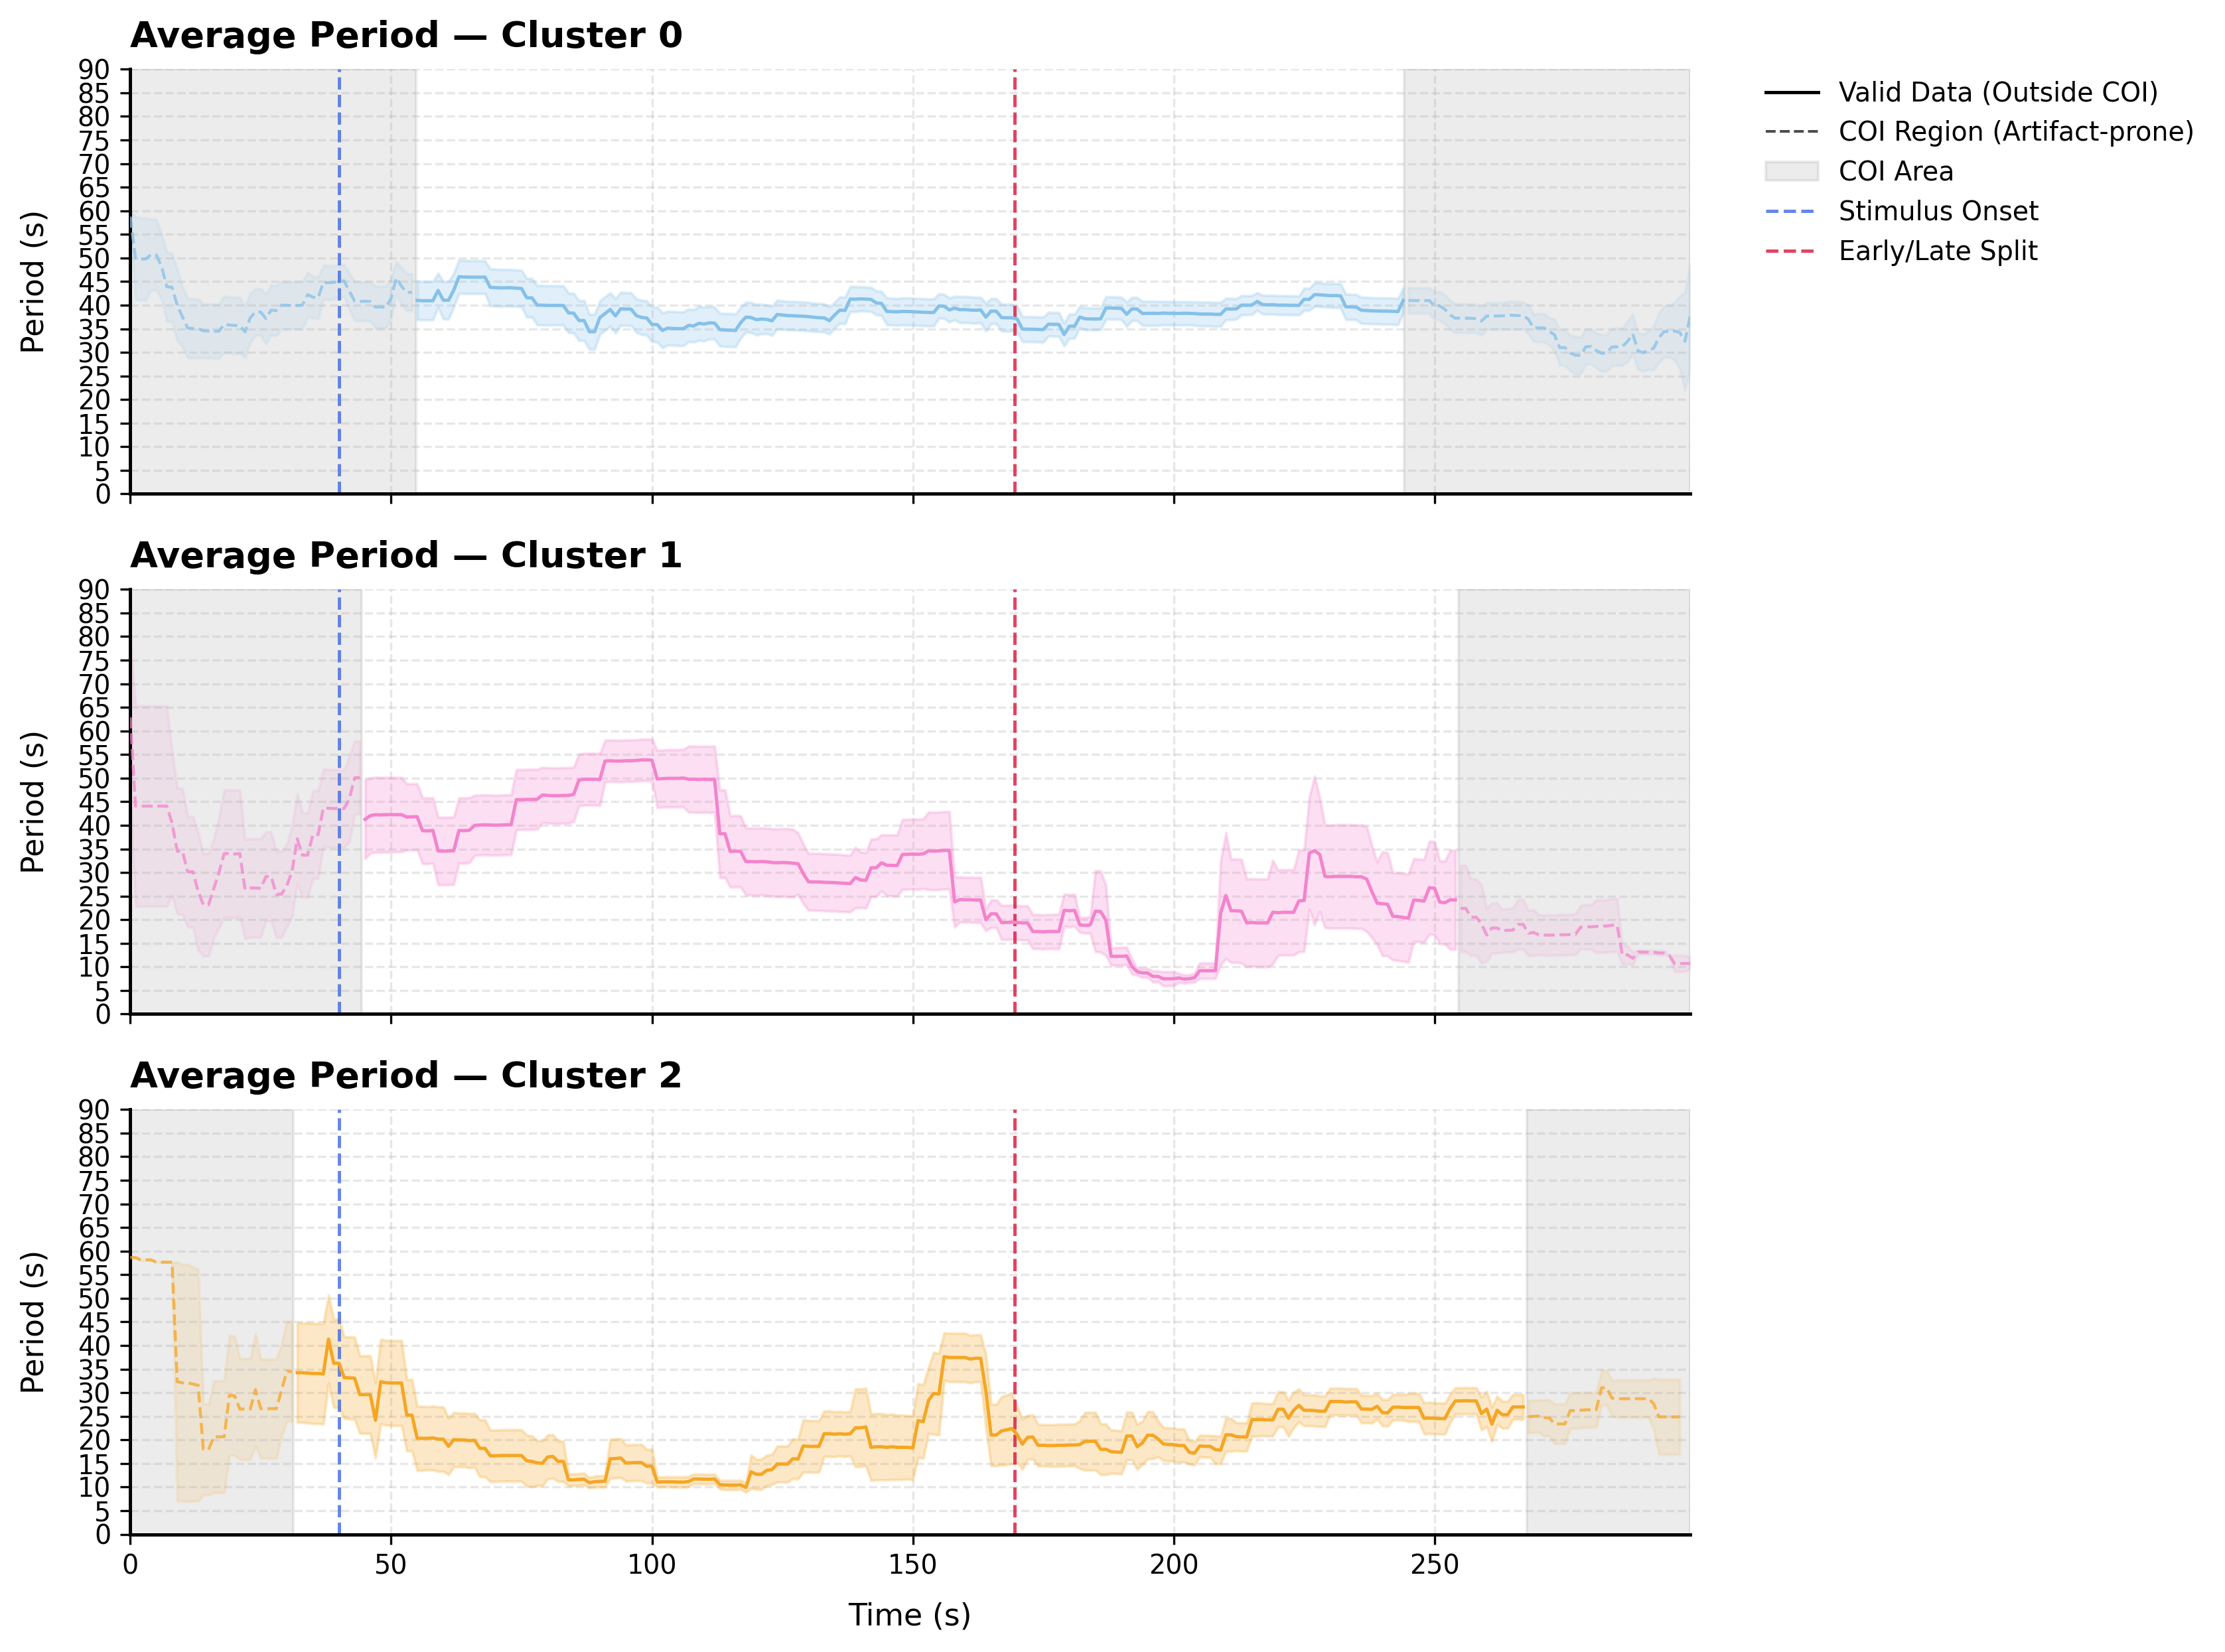

In [ ]:

def extract_numeric_id(val):
    if pd.isna(val):
        return None
    s = str(val).strip()
    numbers = re.findall(r'\d+', s)
    return int(numbers[-1]) if numbers else None


def clean_cell_name(val):
    if pd.isna(val):
        return ''
    s = str(val).strip().lower()
    s = re.sub(
        r'(_periods|_detrended|_delta_f_f0|_norm|_raw|_clean|_signal)$', '', s
    )
    s = re.sub(r'^(roi_|cell_|c_)', '', s)
    return s


def clean_cluster_val(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    nums = re.findall(r'-?\d+', s)
    return int(nums[-1]) if nums else val


# 1. AUTOMATIC SEARCH OF DATAFRAMES
df_combined = globals().get('df_combined_all_features')
if not isinstance(df_combined, pd.DataFrame) or df_combined.empty:
    for name in [
        'df_raw',
        'df_combined',
        'df_feat',
        'df_clean',
        'df_periods_all',
    ]:
        obj = globals().get(name)
        if isinstance(obj, pd.DataFrame) and not obj.empty:
            df_combined = obj
            break

df_umap = globals().get('df_feat')
if df_umap is None or not any(
    c in df_umap.columns
    for c in ['cluster', 'k4_cluster', 'hierarchical_cluster']
):
    df_umap = globals().get(
        'umap_df_pipeline', globals().get('df_features_res')
    )

if df_combined is None or df_umap is None:
    raise ValueError(
        '❌ Error: No valid DataFrames found in memory.'
    )

umap_temp = df_umap.copy()

cluster_col = next(
    (
        c
        for c in [
            'cluster',
            'k4_cluster',
            'hierarchical_cluster',
            'cluster_label',
            'Subensemble',
        ]
        if c in umap_temp.columns
    ),
    'cluster',
)
cell_id_col = next(
    (
        c
        for c in ['cell_id', 'canonical_id', 'ROI', 'cell', 'id_clean']
        if c in umap_temp.columns
    ),
    umap_temp.columns[0],
)

umap_temp['cell_base'] = umap_temp[cell_id_col].apply(clean_cell_name)
umap_temp['clean_num_id'] = umap_temp[cell_id_col].apply(extract_numeric_id)
umap_temp['clean_cluster'] = umap_temp[cluster_col].apply(clean_cluster_val)

map_by_str = (
    umap_temp.dropna(subset=['cell_base'])
    .drop_duplicates(subset=['cell_base'])
    .set_index('cell_base')['clean_cluster']
    .to_dict()
)
map_by_num = (
    umap_temp.dropna(subset=['clean_num_id'])
    .drop_duplicates(subset=['clean_num_id'])
    .set_index('clean_num_id')['clean_cluster']
    .to_dict()
)

# 2. SELECTION OF TIME AND PERIOD COLUMNS
time_col = next(
    (
        c
        for c in ['time', 'Time', 'time_sec', 't']
        if c in df_combined.columns
    ),
    df_combined.columns[0],
)
periods_cols = [c for c in df_combined.columns if c.endswith('_periods')]
if not periods_cols:
    periods_cols = [
        c
        for c in df_combined.columns
        if c != time_col and pd.api.types.is_numeric_dtype(df_combined[c])
    ]

# 3. TRANSFORM TO LONG FORMAT (MELT) AND MERGE WITH CLUSTERS
df_periods_melted = df_combined.melt(
    id_vars=[time_col],
    value_vars=periods_cols,
    var_name='cell_raw',
    value_name='periods_value',
)

df_periods_melted['cell_base'] = df_periods_melted['cell_raw'].apply(
    clean_cell_name
)
df_periods_melted['clean_num_id'] = df_periods_melted['cell_raw'].apply(
    extract_numeric_id
)

df_periods_melted['hierarchical_cluster'] = df_periods_melted['cell_base'].map(
    map_by_str
)
missing_mask = df_periods_melted['hierarchical_cluster'].isna()
df_periods_melted.loc[missing_mask, 'hierarchical_cluster'] = (
    df_periods_melted.loc[missing_mask, 'clean_num_id'].map(map_by_num)
)

df_data = df_periods_melted.dropna(
    subset=['hierarchical_cluster', 'periods_value']
).copy()
df_data = df_data[df_data['hierarchical_cluster'] >= 0].copy()
df_data['hierarchical_cluster'] = df_data['hierarchical_cluster'].astype(int)

if df_data.empty:
    raise ValueError(
        '❌ Could not map the cells between period data and clusters. '
        'Please verify that cell IDs match between DataFrames.'
    )

mean_stats = (
    df_data.groupby([time_col, 'hierarchical_cluster'])['periods_value']
    .agg(['mean', 'sem'])
    .reset_index()
)

clusters = sorted(df_data['hierarchical_cluster'].unique())
print(
    f'✅ Data mapped successfully. Clusters to plot: {clusters} (Total rows: {len(df_data)})'
)

# 4. PLOTTING PARAMETERS CONFIGURATION
title_font_size = globals().get('title_font_size_global', 12)
label_font_size = globals().get('label_font_size_global', 11)
tick_font_size = globals().get('tick_font_size_global', 10)
axis_line_width = globals().get('axis_line_width_global', 1.2)
legend_font_size = globals().get('legend_label_font_size_global', 9)
dpi_val = globals().get('dpi_global', 300)

stimulus_onset = globals().get('stimulus_onset_time_global', 60.0)
split_time = globals().get('post_stimulus_split_time_global', 172.0)
total_duration = df_combined[time_col].max()

c_map_default = {
    0: '#89CFF0',
    1: '#EE82EE',
    2: '#FFA500',
    3: '#2ca02c',
    4: '#d62728',
    -1: '#808080',
}
c_map = globals().get('cluster_color_map_global', c_map_default)

# ROBUST Y-AXIS LIMITS
global_min_per = (mean_stats['mean'] - mean_stats['sem'].fillna(0)).min()
global_max_per = (mean_stats['mean'] + mean_stats['sem'].fillna(0)).max()

if np.isnan(global_min_per) or np.isnan(global_max_per):
    global_min_per, global_max_per = 0, 30

margin = (global_max_per - global_min_per) * 0.10 if global_max_per > global_min_per else 2.0
y_min_plot = max(0, np.floor((global_min_per - margin) / 5.0) * 5.0)
y_max_plot = np.ceil((global_max_per + margin) / 5.0) * 5.0

# 5. MULTIPANEL VISUAL RENDERING
fig, axes = plt.subplots(
    len(clusters),
    1,
    figsize=(11, 2.8 * len(clusters)),
    sharex=True,
    sharey=True,
    squeeze=False,
    dpi=dpi_val,
)

for i, cluster_id in enumerate(clusters):
    ax = axes[i, 0]
    subset = (
        mean_stats[mean_stats['hierarchical_cluster'] == cluster_id]
        .copy()
        .sort_values(time_col)
    )

    color = c_map.get(cluster_id, '#333333')
    n_cells = df_data[df_data['hierarchical_cluster'] == cluster_id][
        'cell_base'
    ].nunique()

    cluster_periods = df_data[
        df_data['hierarchical_cluster'] == cluster_id
    ]['periods_value']
    avg_period = (
        cluster_periods.mean() if not cluster_periods.empty else 8.0
    )
    if np.isnan(avg_period) or avg_period <= 0:
        avg_period = 8.0

    coi_sec = 1.43 * avg_period

    left_coi = subset[subset[time_col] <= coi_sec]
    right_coi = subset[subset[time_col] >= (total_duration - coi_sec)]
    valid_data = subset[
        (subset[time_col] >= coi_sec)
        & (subset[time_col] <= (total_duration - coi_sec))
    ]

    # COI Shadows
    ax.axvspan(0, coi_sec, color='gray', alpha=0.15, zorder=1)
    ax.axvspan(
        total_duration - coi_sec,
        total_duration,
        color='gray',
        alpha=0.15,
        zorder=1,
    )

    if not left_coi.empty:
        ax.plot(
            left_coi[time_col],
            left_coi['mean'],
            color=color,
            linestyle='--',
            linewidth=axis_line_width * 0.9,
            alpha=0.75,
            zorder=3,
        )
        ax.fill_between(
            left_coi[time_col],
            left_coi['mean'] - left_coi['sem'].fillna(0),
            left_coi['mean'] + left_coi['sem'].fillna(0),
            color=color,
            alpha=0.12,
            zorder=1,
        )

    if not right_coi.empty:
        ax.plot(
            right_coi[time_col],
            right_coi['mean'],
            color=color,
            linestyle='--',
            linewidth=axis_line_width * 0.9,
            alpha=0.75,
            zorder=3,
        )
        ax.fill_between(
            right_coi[time_col],
            right_coi['mean'] - right_coi['sem'].fillna(0),
            right_coi['mean'] + right_coi['sem'].fillna(0),
            color=color,
            alpha=0.12,
            zorder=1,
        )

    if not valid_data.empty:
        ax.plot(
            valid_data[time_col],
            valid_data['mean'],
            color=color,
            linestyle='-',
            linewidth=axis_line_width,
            zorder=4,
        )
        ax.fill_between(
            valid_data[time_col],
            valid_data['mean'] - valid_data['sem'].fillna(0),
            valid_data['mean'] + valid_data['sem'].fillna(0),
            color=color,
            alpha=0.25,
            zorder=2,
        )

    ax.axvline(
        stimulus_onset,
        color='#4169E1',
        linestyle='--',
        alpha=0.8,
        linewidth=axis_line_width,
    )
    if split_time is not None and not np.isnan(split_time):
        ax.axvline(
            split_time,
            color='#DC143C',
            linestyle='--',
            alpha=0.8,
            linewidth=axis_line_width,
        )

    ax.set_ylim(y_min_plot, y_max_plot)
    ax.yaxis.set_major_locator(ticker.MultipleLocator(5))
    ax.set_xlim(0, total_duration)

    ax.set_ylabel('Period (s)', fontsize=label_font_size, labelpad=10)
    ax.set_title(
        f'Average Period — Cluster {cluster_id}',
        fontsize=title_font_size,
        loc='left',
        fontweight='bold',
        pad=8,
    )
    ax.grid(True, linestyle='--', alpha=0.3)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(axis_line_width)
    ax.tick_params(axis='both', labelsize=tick_font_size)

axes[-1, 0].set_xlabel('Time (s)', fontsize=label_font_size, labelpad=8)

# Legend
solid_line = mlines.Line2D(
    [0], [0], color='black', linestyle='-', linewidth=axis_line_width, label='Valid Data (Outside COI)'
)
dashed_line = mlines.Line2D(
    [0], [0], color='black', linestyle='--', linewidth=axis_line_width * 0.8, alpha=0.7, label='COI Region (Artifact-prone)'
)
coi_patch = mpatches.Patch(color='gray', alpha=0.15, label='COI Area')
stim_line = mlines.Line2D(
    [0], [0], color='#4169E1', linestyle='--', alpha=0.8, linewidth=axis_line_width, label='Stimulus Onset'
)
split_line = mlines.Line2D(
    [0], [0], color='#DC143C', linestyle='--', alpha=0.8, linewidth=axis_line_width, label='Early/Late Split'
)

fig.legend(
    handles=[solid_line, dashed_line, coi_patch, stim_line, split_line],
    loc='upper left',
    bbox_to_anchor=(0.81, 0.96),
    fontsize=legend_font_size,
    frameon=True,
    facecolor='white',
    edgecolor='none',
)

plt.tight_layout(rect=[0.01, 0, 0.80, 1])
plt.savefig('mean_cluster_periods.png', bbox_inches='tight', dpi=dpi_val)
plt.show()
plt.close(fig)


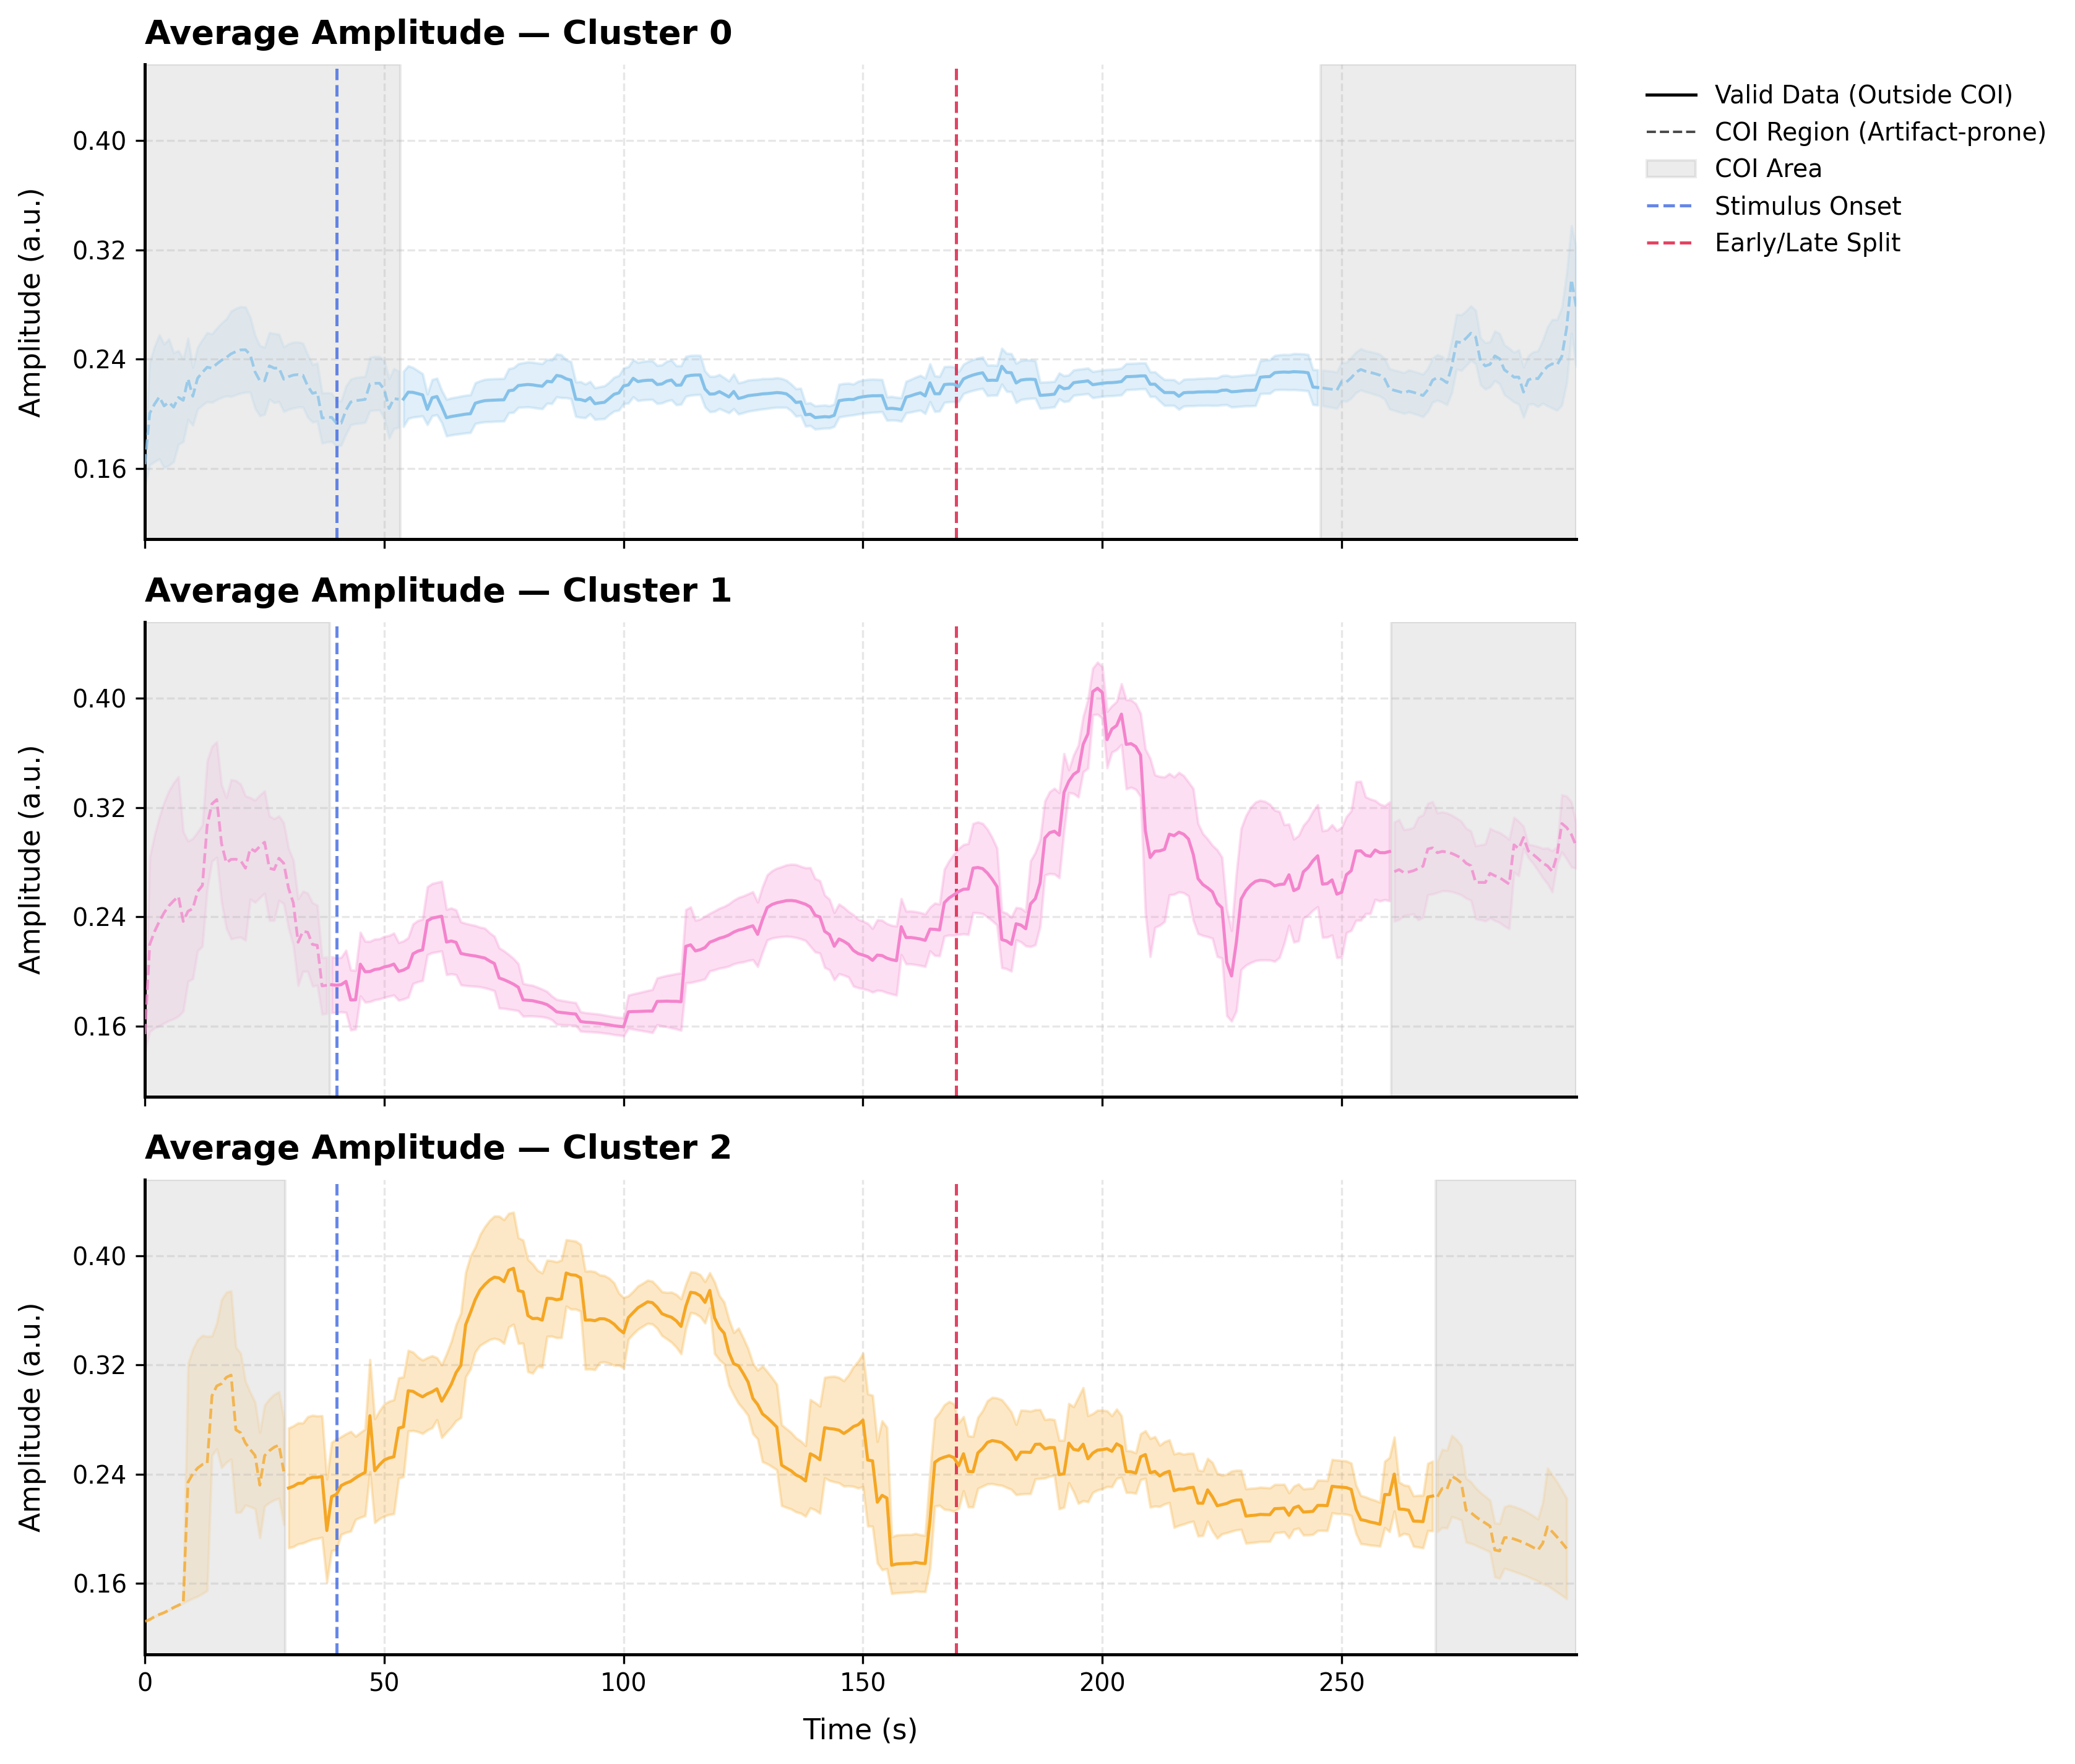

In [ ]:
def extract_numeric_id(val):
    if pd.isna(val):
        return None
    s = str(val).strip()
    numbers = re.findall(r'\d+', s)
    return int(numbers[-1]) if numbers else None


def clean_cell_name(val):
    if pd.isna(val):
        return ''
    s = str(val).strip().lower()
    s = re.sub(
        r'(_amplitude|_periods|_detrended|_delta_f_f0|_norm|_raw|_clean|_signal)$',
        '',
        s,
    )
    s = re.sub(r'^(roi_|cell_|c_)', '', s)
    return s


def clean_cluster_val(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    nums = re.findall(r'-?\d+', s)
    return int(nums[-1]) if nums else val


# ==============================================================================
# CLUSTER FILTERING CONFIGURATION
# ==============================================================================
TARGET_CLUSTERS = None  # Example: [3] to see only Cluster 3, or None for all

# ==============================================================================
# 1. AUTOMATIC DATAFRAME SEARCH AND MAPPING
# ==============================================================================
df_combined = globals().get('df_combined_all_features')
if not isinstance(df_combined, pd.DataFrame) or df_combined.empty:
    for name in [
        'df_combined',
        'df_integrated',
        'df_wavelet_all',
        'df_all',
        'df_raw',
        'df_feat',
        'df_clean',
    ]:
        obj = globals().get(name)
        if isinstance(obj, pd.DataFrame) and not obj.empty:
            df_combined = obj
            break

df_umap = globals().get('umap_df_pipeline')
if df_umap is None or not any(
    c in df_umap.columns
    for c in ['cluster', 'k4_cluster', 'hierarchical_cluster']
):
    df_umap = globals().get(
        'df_feat', globals().get('df_clustering', globals().get('df_features_res'))
    )

if df_combined is None or df_umap is None:
    raise ValueError(
        '❌ Error: No valid DataFrames found in memory.'
    )

umap_temp = df_umap.copy()

cluster_col = next(
    (
        c
        for c in [
            'cluster',
            'k4_cluster',
            'hierarchical_cluster',
            'cluster_label',
            'Subensemble',
        ]
        if c in umap_temp.columns
    ),
    'cluster',
)
cell_id_col = next(
    (
        c
        for c in [
            'cell_id',
            'canonical_id',
            'ROI',
            'cell',
            'id_clean',
            'roi_id',
        ]
        if c in umap_temp.columns
    ),
    umap_temp.columns[0],
)

umap_temp['cell_base'] = umap_temp[cell_id_col].apply(clean_cell_name)
umap_temp['clean_num_id'] = umap_temp[cell_id_col].apply(extract_numeric_id)
umap_temp['clean_cluster'] = umap_temp[cluster_col].apply(clean_cluster_val)

map_by_str = (
    umap_temp.dropna(subset=['cell_base'])
    .drop_duplicates(subset=['cell_base'])
    .set_index('cell_base')['clean_cluster']
    .to_dict()
)
map_by_num = (
    umap_temp.dropna(subset=['clean_num_id'])
    .drop_duplicates(subset=['clean_num_id'])
    .set_index('clean_num_id')['clean_cluster']
    .to_dict()
)

# ==============================================================================
# 2. GLOBAL PARAMETERS AND DATA MERGING
# ==============================================================================
title_font_size = globals().get('title_font_size_global', 12)
label_font_size = globals().get('label_font_size_global', 11)
tick_font_size = globals().get('tick_font_size_global', 10)
axis_line_width = globals().get('axis_line_width_global', 1.2)
legend_font_size = globals().get('legend_label_font_size_global', 9)
dpi_val = globals().get('dpi_global', 300)

time_col = next(
    (
        c
        for c in ['time', 'Time', 'time_sec', 't', 'seg']
        if c in df_combined.columns
    ),
    df_combined.columns[0],
)
stimulus_onset = globals().get('stimulus_onset_time_global', 60.0)
split_time = globals().get('post_stimulus_split_time_global', 180.0)
total_duration = df_combined[time_col].max()

c_map_default = {
    0: '#89CFF0',
    1: '#EE82EE',
    2: '#FFA500',
    3: '#2ca02c',
    4: '#d62728',
    -1: '#808080',
}
c_map = globals().get('cluster_color_map_global', c_map_default)

amplitudes_cols = [c for c in df_combined.columns if c.endswith('_amplitude')]
if not amplitudes_cols:
    amplitudes_cols = [
        c
        for c in df_combined.columns
        if c != time_col and pd.api.types.is_numeric_dtype(df_combined[c])
    ]

df_amp_melted = df_combined.melt(
    id_vars=[time_col],
    value_vars=amplitudes_cols,
    var_name='cell_raw',
    value_name='amplitude_value',
)

df_amp_melted['cell_base'] = df_amp_melted['cell_raw'].apply(clean_cell_name)
df_amp_melted['clean_num_id'] = df_amp_melted['cell_raw'].apply(
    extract_numeric_id
)

df_amp_melted['hierarchical_cluster'] = df_amp_melted['cell_base'].map(
    map_by_str
)
missing_mask = df_amp_melted['hierarchical_cluster'].isna()
df_amp_melted.loc[missing_mask, 'hierarchical_cluster'] = df_amp_melted.loc[
    missing_mask, 'clean_num_id'
].map(map_by_num)

df_data = df_amp_melted.dropna(
    subset=['hierarchical_cluster', 'amplitude_value']
).copy()
df_data = df_data[df_data['hierarchical_cluster'] >= 0].copy()
df_data['hierarchical_cluster'] = df_data['hierarchical_cluster'].astype(int)

# Apply filter if TARGET_CLUSTERS was defined
if TARGET_CLUSTERS is not None:
    df_data = df_data[df_data['hierarchical_cluster'].isin(TARGET_CLUSTERS)]

if df_data.empty:
    raise ValueError(
        f'❌ No data was found for the selected clusters: {TARGET_CLUSTERS}'
    )

mean_stats = (
    df_data.groupby([time_col, 'hierarchical_cluster'])['amplitude_value']
    .agg(['mean', 'sem'])
    .reset_index()
)

clusters = sorted(df_data['hierarchical_cluster'].unique())

# ==============================================================================
# 3. VISUAL RENDERING WITH ROBUST NAN PROTECTION
# ==============================================================================
sem_safe = mean_stats['sem'].fillna(0)
global_min_amp = (mean_stats['mean'] - sem_safe).min()
global_max_amp = (mean_stats['mean'] + sem_safe).max()

if np.isnan(global_min_amp) or np.isnan(global_max_amp):
    global_min_amp, global_max_amp = 0.0, 1.0

margin = (
    (global_max_amp - global_min_amp) * 0.08
    if global_max_amp > global_min_amp
    else 0.1
)
y_min_plot = global_min_amp - margin
y_max_plot = global_max_amp + margin

fig, axes = plt.subplots(
    len(clusters),
    1,
    figsize=(11, max(3.2 * len(clusters), 3.5)),
    sharex=True,
    sharey=True,
    squeeze=False,
    dpi=dpi_val,
)

for i, cluster_id in enumerate(clusters):
    ax = axes[i, 0]
    subset = (
        mean_stats[mean_stats['hierarchical_cluster'] == cluster_id]
        .copy()
        .sort_values(time_col)
    )
    color = c_map.get(cluster_id, '#2ca02c')

    n_cells = df_data[df_data['hierarchical_cluster'] == cluster_id][
        'cell_base'
    ].nunique()

    cluster_cells = set(
        df_data[df_data['hierarchical_cluster'] == cluster_id][
            'cell_base'
        ].unique()
    )

    period_cols = [
        c
        for c in df_combined.columns
        if c.endswith('_periods') and clean_cell_name(c) in cluster_cells
    ]

    avg_period = 8.0
    if period_cols:
        p_mean = df_combined[period_cols].mean(numeric_only=True).mean()
        if not np.isnan(p_mean) and p_mean > 0:
            avg_period = p_mean

    coi_sec = 1.43 * avg_period

    left_coi = subset[subset[time_col] <= coi_sec]
    right_coi = subset[subset[time_col] >= (total_duration - coi_sec)]
    valid_data = subset[
        (subset[time_col] >= coi_sec)
        & (subset[time_col] <= (total_duration - coi_sec))
    ]

    ax.axvspan(0, coi_sec, color='gray', alpha=0.15, zorder=1)
    ax.axvspan(
        total_duration - coi_sec,
        total_duration,
        color='gray',
        alpha=0.15,
        zorder=1,
    )

    if not left_coi.empty:
        sem_left = left_coi['sem'].fillna(0)
        ax.plot(
            left_coi[time_col],
            left_coi['mean'],
            color=color,
            linestyle='--',
            linewidth=axis_line_width * 0.9,
            alpha=0.75,
            zorder=3,
        )
        ax.fill_between(
            left_coi[time_col],
            left_coi['mean'] - sem_left,
            left_coi['mean'] + sem_left,
            color=color,
            alpha=0.12,
            zorder=1,
        )

    if not right_coi.empty:
        sem_right = right_coi['sem'].fillna(0)
        ax.plot(
            right_coi[time_col],
            right_coi['mean'],
            color=color,
            linestyle='--',
            linewidth=axis_line_width * 0.9,
            alpha=0.75,
            zorder=3,
        )
        ax.fill_between(
            right_coi[time_col],
            right_coi['mean'] - sem_right,
            right_coi['mean'] + sem_right,
            color=color,
            alpha=0.12,
            zorder=1,
        )

    if not valid_data.empty:
        sem_valid = valid_data['sem'].fillna(0)
        ax.plot(
            valid_data[time_col],
            valid_data['mean'],
            color=color,
            linestyle='-',
            linewidth=axis_line_width,
            zorder=4,
        )
        ax.fill_between(
            valid_data[time_col],
            valid_data['mean'] - sem_valid,
            valid_data['mean'] + sem_valid,
            color=color,
            alpha=0.25,
            zorder=2,
        )

    ax.axvline(
        stimulus_onset,
        color='#4169E1',
        linestyle='--',
        alpha=0.8,
        linewidth=axis_line_width,
    )
    if split_time is not None and not np.isnan(split_time):
        ax.axvline(
            split_time,
            color='#DC143C',
            linestyle='--',
            alpha=0.8,
            linewidth=axis_line_width,
        )

    ax.set_ylim(y_min_plot, y_max_plot)
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    ax.set_xlim(0, total_duration)

    ax.set_ylabel('Amplitude (a.u.)', fontsize=label_font_size, labelpad=10)
    ax.set_title(
        f'Average Amplitude — Cluster {cluster_id}',
        fontsize=title_font_size,
        loc='left',
        fontweight='bold',
        pad=8,
    )
    ax.grid(True, linestyle='--', alpha=0.3)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(axis_line_width)
    ax.tick_params(axis='both', labelsize=tick_font_size)

axes[-1, 0].set_xlabel('Time (s)', fontsize=label_font_size, labelpad=8)

solid_line = mlines.Line2D(
    [0],
    [0],
    color='black',
    linestyle='-',
    linewidth=axis_line_width,
    label='Valid Data (Outside COI)',
)
dashed_line = mlines.Line2D(
    [0],
    [0],
    color='black',
    linestyle='--',
    linewidth=axis_line_width * 0.8,
    alpha=0.7,
    label='COI Region (Artifact-prone)',
)
coi_patch = mpatches.Patch(color='gray', alpha=0.15, label='COI Area')
stim_line = mlines.Line2D(
    [0],
    [0],
    color='#4169E1',
    linestyle='--',
    alpha=0.8,
    linewidth=axis_line_width,
    label='Stimulus Onset',
)
split_line = mlines.Line2D(
    [0],
    [0],
    color='#DC143C',
    linestyle='--',
    alpha=0.8,
    linewidth=axis_line_width,
    label='Early/Late Split',
)

fig.legend(
    handles=[solid_line, dashed_line, coi_patch, stim_line, split_line],
    loc='upper left',
    bbox_to_anchor=(0.81, 0.96),
    fontsize=legend_font_size,
    frameon=True,
    facecolor='white',
    edgecolor='none',
)

plt.tight_layout(rect=[0.01, 0, 0.80, 1])
plt.savefig('mean_cluster_3_amplitude.png', bbox_inches='tight', dpi=dpi_val)
plt.show()
plt.close(fig)

##Visualization of Temporal Dynamics with Violin Plots

This block generates violin plots grouped by cluster to visualize the evolution of **Wavelet Power** (COI-filtered data) and **Period** (complete segments). Annotations of statistical significance are included, comparing each post-stimulus segment with its respective baseline.

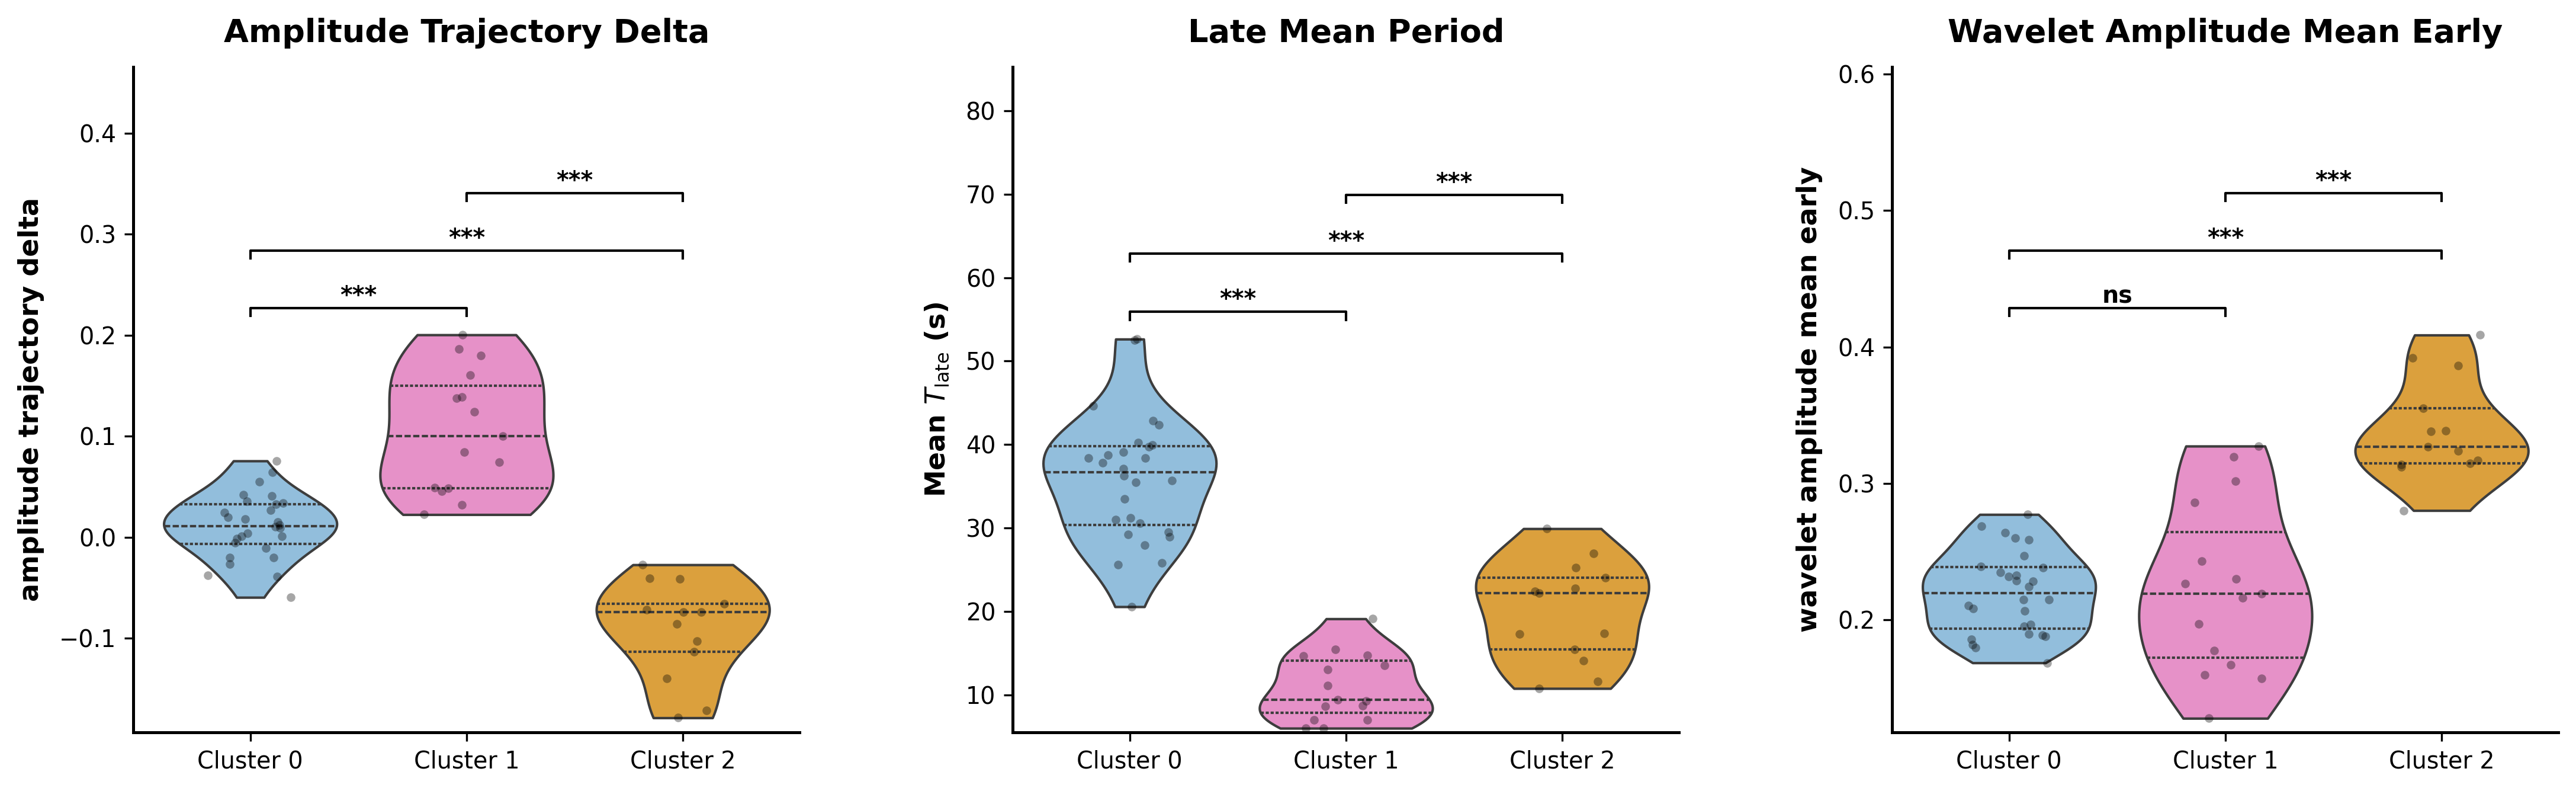

In [ ]:
plt.rcParams.update(plt.rcParamsDefault)


def get_stars(p):
  return (
      '***'
      if p < 0.001
      else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
  )


def format_feature_name(feat_name):
  pretty_names = {
      'power_trajectory_delta': (
          'Power Trajectory Delta',
          r'$\Delta \log_{10}(P)$ (late - early)',
      ),
      'period_trajectory_delta': (
          'Period Trajectory Delta',
          r'$\Delta T$ (late - early) (s)',
      ),
      'wavelet_period_mean_early': (
          'Early Mean Period',
          r'Mean $T_{\text{early}}$ (s)',
      ),
      'wavelet_period_mean_late': (
          'Late Mean Period',
          r'Mean $T_{\text{late}}$ (s)',
      ),
      'wavelet_power_log_mean_early': (
          'Early Log-Power',
          r'$\log_{10}(P_{\text{early}})$',
      ),
      'wavelet_power_log_mean_late': (
          'Late Log-Power',
          r'$\log_{10}(P_{\text{late}})$',
      ),
      'snr_late_vs_basal_log2fc': (
          'SNR Late vs Basal',
          r'$\log_2(\text{SNR}_{\text{late}} / \text{SNR}_{\text{basal}})$',
      ),
      'detrend_std_basal': (
          'Basal Standard Deviation',
          r'$\sigma_{\text{basal}}$ (a.u.)',
      ),
  }
  if feat_name in pretty_names:
    return pretty_names[feat_name]
  return feat_name.replace('_', ' ').title(), feat_name.replace('_', ' ')


MIN_CELLS_PER_CLUSTER = 5

df_stats_ready = globals().get('df_feat')
importances_df = globals().get('importances')

t_fs = globals().get('title_font_size_global', 12)
l_fs = globals().get('label_font_size_global', 11)
tk_fs = globals().get('tick_font_size_global', 9.5)
ax_lw = globals().get('axis_line_width_global', 1.2)
cell_type_label = globals().get('cell_type_global', 'Cell')

if df_stats_ready is not None and 'cluster' in df_stats_ready.columns:
  df_plot_data = df_stats_ready.copy()
  df_plot_data['cluster_str'] = df_plot_data['cluster'].astype(str)

  counts = df_plot_data['cluster_str'].value_counts()
  valid_clusters = counts[counts >= MIN_CELLS_PER_CLUSTER].index.tolist()
  df_plot_data = df_plot_data[
      df_plot_data['cluster_str'].isin(valid_clusters)
  ].copy()

  c_map_raw = globals().get(
      'cluster_color_map_global',
      {0: '#85C1E9', 1: '#F483CC', 2: '#F5A623', 3: '#2CA02C'},
  )
  c_map = {str(k): v for k, v in c_map_raw.items()}
  cluster_order = sorted(
      df_plot_data['cluster_str'].unique(), key=lambda x: int(x)
  )
  x_tick_labels = [f'Cluster {cl}' for cl in cluster_order]

  if importances_df is not None and not importances_df.empty:
    top_3_cols = importances_df.head(3)['feature'].tolist()
  else:
    top_3_cols = [
        c
        for c in df_plot_data.columns
        if c not in ['cell_id', 'cluster', 'cluster_str', 'UMAP_1', 'UMAP_2']
    ][:3]

  metrics = [
      (col, *format_feature_name(col))
      for col in top_3_cols
      if col in df_plot_data.columns
  ]
  n_plots = len(metrics)
  fig, axes = plt.subplots(1, n_plots, figsize=(5 * n_plots, 4.8), dpi=300)

  if n_plots == 1:
    axes = [axes]

  for i, (col, title, y_label) in enumerate(metrics):
    ax = axes[i]

    sns.violinplot(
        data=df_plot_data,
        x='cluster_str',
        y=col,
        order=cluster_order,
        palette=c_map,
        hue='cluster_str',
        legend=False,
        inner='quartile',
        cut=0,
        linewidth=1,
        ax=ax,
    )
    sns.stripplot(
        data=df_plot_data,
        x='cluster_str',
        y=col,
        order=cluster_order,
        color='black',
        alpha=0.35,
        size=3.5,
        jitter=0.2,
        ax=ax,
    )

    ax.set_title(title, fontsize=t_fs, fontweight='bold', pad=10)
    ax.set_xlabel('', fontsize=l_fs)
    ax.set_ylabel(y_label, fontsize=l_fs, fontweight='bold', labelpad=6)
    ax.set_xticklabels(x_tick_labels, fontsize=tk_fs)
    ax.tick_params(axis='both', labelsize=tk_fs)

    for spine in ['top', 'right']:
      ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
      ax.spines[spine].set_linewidth(ax_lw)

    # 1. PRIOR OMNIBUS KRUSKAL-WALLIS TEST
    group_data = [
        df_plot_data[df_plot_data['cluster_str'] == cl][col].dropna().values
        for cl in cluster_order
    ]
    kw_stat, kw_p = kruskal(*group_data)

    # 2. PAIRWISE COMPARISONS ONLY IF KRUSKAL-WALLIS IS SIGNIFICANT (p < 0.05)
    if kw_p < 0.05:
      pairs = list(combinations(range(len(cluster_order)), 2))
      raw_pvals, valid_pairs = [], []

      for idx1, idx2 in pairs:
        g1, g2 = group_data[idx1], group_data[idx2]
        if len(g1) >= MIN_CELLS_PER_CLUSTER and len(g2) >= MIN_CELLS_PER_CLUSTER:
          stat, p = mannwhitneyu(g1, g2, alternative='two-sided')
          raw_pvals.append(p)
          valid_pairs.append((idx1, idx2))

      if raw_pvals:
        _, adj_pvals, _, _ = multipletests(raw_pvals, method='fdr_bh')
        y_min, y_max = df_plot_data[col].min(), df_plot_data[col].max()
        plot_h = y_max - y_min if y_max != y_min else 1.0

        extra_top = plot_h * (0.25 + len(valid_pairs) * 0.15)
        ax.set_ylim(
            y_min - abs(y_min) * 0.08 if not np.isnan(y_min) else -1,
            y_max + extra_top if not np.isnan(y_max) else 1,
        )

        for p_idx, (idx1, idx2) in enumerate(valid_pairs):
          p_adj = adj_pvals[p_idx]
          h = y_max + (p_idx * plot_h * 0.15) + (plot_h * 0.05)
          ax.plot(
              [idx1, idx1, idx2, idx2],
              [h, h + plot_h * 0.02, h + plot_h * 0.02, h],
              lw=1.0,
              c='black',
          )
          ax.text(
              (idx1 + idx2) * 0.5,
              h + plot_h * 0.02,
              get_stars(p_adj),
              ha='center',
              va='bottom',
              fontsize=tk_fs,
              fontweight='bold',
          )

  plt.subplots_adjust(
      left=0.07, right=0.98, top=0.90, bottom=0.12, wspace=0.32
  )
  plt.savefig(
      f'{cell_type_label.lower()}_top_features_publication.png',
      dpi=300,
      bbox_inches='tight',
  )
  plt.show()

##Statical Report Dynamics

In [ ]:

# ==============================================================================
# 1. PARAMETERS AND DATA RETRIEVAL
# ==============================================================================
MIN_CELLS_PER_CLUSTER = 6
N_TOP_FEATURES_TO_REPORT = (
    3  # Same number of variables as in the Block 1 figure
)

df_feat = globals().get("df_feat")
# Removed fallback to df_stats_ready as df_feat is directly populated by run_pipeline
# and should be the primary source for features data.

importances_df = globals().get("importances")
cell_type_label = globals().get("cell_type_global", "Cellular")

print(
    f"Generating Publication-Ready Statistical Report for {cell_type_label} (Top Features)..."
)

if df_feat is not None and not df_feat.empty and "cluster" in df_feat.columns:
  output = io.StringIO()
  sys.stdout = output

  print("=================================================================")
  print(
      f"       STATISTICAL REPORT: {cell_type_label.upper()} DYNAMICS (TOP"
      " FEATURES)"
  )
  print("  Omnibus Test: Kruskal-Wallis H-test                            ")
  print("  Post-hoc Standards: Non-parametric (Wilcoxon / Mann-Whitney U) ")
  print("  Multi-Testing Correction: Benjamini-Hochberg FDR               ")
  print("  Effect Size: Rosenthal's r (|Z| / sqrt(N))                     ")
  print("=================================================================\n")

  try:
    clusters = sorted(df_feat["cluster"].unique(), key=lambda x: int(x))
  except (ValueError, TypeError):
    clusters = sorted(df_feat["cluster"].unique())

  # ==============================================================================
  # 2. INTRA-CLUSTER TEMPORAL DYNAMICS (Wilcoxon Signed-Rank Tests)
  # ==============================================================================
  print(
      "--- 1. INTRA-CLUSTER TEMPORAL DYNAMICS (Wilcoxon Signed-Rank Tests)"
      " ---"
  )

  possible_pairs = [
      (
          "wavelet_period_mean_early",
          "wavelet_period_mean_late",
          "Mean Period: Early vs Late",
      ),
      (
          "wavelet_power_log_mean_early",
          "wavelet_power_log_mean_late",
          "Log-Power: Early vs Late",
      ),
      (
          "detrend_std_basal",
          "detrend_std_early",
          "Std Deviation: Basal vs Early",
      ),
      (
          "detrend_std_early",
          "detrend_std_late",
          "Std Deviation: Early vs Late",
      ),
  ]

  valid_paired_tests = [
      (c1, c2, lbl)
      for c1, c2, lbl in possible_pairs
      if c1 in df_feat.columns and c2 in df_feat.columns
  ]

  if valid_paired_tests:
    for clus in clusters:
      df_c = df_feat[df_feat["cluster"] == clus]
      print(f"\n[Cluster {clus}] (Total N={len(df_c)})")

      for c1, c2, label in valid_paired_tests:
        paired = df_c[[c1, c2]].dropna()
        n_paired = len(paired)
        if n_paired >= MIN_CELLS_PER_CLUSTER:
          diff = paired[c1] - paired[c2]
          if np.all(diff == 0):
            p, r_val, signif = 1.0, 0.0, "ns"
          else:
            stat, p = wilcoxon(paired[c1], paired[c2])
            p_safe = np.clip(p, 1e-15, 1.0)
            z_score = norm.ppf(1 - p_safe / 2)
            r_val = z_score / np.sqrt(n_paired)
            signif = (
                "***"
                if p < 0.001
                else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
            )

          m1, iqr1 = paired[c1].median(), paired[c1].quantile(
              0.75
          ) - paired[c1].quantile(0.25)
          m2, iqr2 = paired[c2].median(), paired[c2].quantile(
              0.75
          ) - paired[c2].quantile(0.25)

          print(f"  * {label} (N={n_paired}):")
          print(
              f"    - Median [IQR]: {c1}={m1:.3f} [{iqr1:.3f}] vs"
              f" {c2}={m2:.3f} [{iqr2:.3f}]"
          )
          print(
              f"    - Statistics: p = {p:.4e} ({signif}), Rosenthal r ="
              f" {r_val:.3f}"
          )
        else:
          print(
              f"  * {label}: Insufficient paired data (N={n_paired} <"
              f" {MIN_CELLS_PER_CLUSTER})."
          )

  # ==============================================================================
  # 3. INTER-CLUSTER COMPARISON ON TOP PLOTTED FEATURES
  # ==============================================================================
  print(
      "\n\n--- 2. INTER-CLUSTER COMPARISON ON TOP PLOTTED FEATURES"
      " (Kruskal-Wallis + Post-hoc Mann-Whitney U) ---"
  )

  # Strict filtering to the Top N variables selected by Random Forest
  if importances_df is not None and not importances_df.empty:
    top_metrics = importances_df.head(N_TOP_FEATURES_TO_REPORT)[
        "feature"
    ].tolist()
  else:
    exclude_cols = {
        "cell_id",
        "cluster",
        "cluster_str",
        "UMAP_1",
        "UMAP_2",
        "cluster_label",
    }
    top_metrics = [c for c in df_feat.columns if c not in exclude_cols][
        :N_TOP_FEATURES_TO_REPORT
    ]

  for col in top_metrics:
    if col not in df_feat.columns:
      continue

    print(f"\n[Metric: {col}]")

    # Descriptive statistics
    group_data_dict = {}
    for c in clusters:
      vals = df_feat[df_feat["cluster"] == c][col].dropna().values
      group_data_dict[c] = vals
      if len(vals) > 0:
        med = np.median(vals)
        q25, q75 = np.percentile(vals, 25), np.percentile(vals, 75)
        print(
            f"  • Cluster {c} (N={len(vals)}): Median = {med:.3f} [IQR:"
            f" {q25:.3f} - {q75:.3f}]"
        )

    # Kruskal-Wallis Test (Omnibus)
    valid_groups = [
        vals
        for vals in group_data_dict.values()
        if len(vals) >= MIN_CELLS_PER_CLUSTER
    ]
    if len(valid_groups) >= 2:
      kw_stat, kw_p = kruskal(*valid_groups)
      kw_signif = (
          "***"
          if kw_p < 0.001
          else "**" if kw_p < 0.01 else "*" if kw_p < 0.05 else "ns"
      )
      print(
          f"  • Omnibus Kruskal-Wallis H-test: H = {kw_stat:.3f}, p ="
          f" {kw_p:.4e} ({kw_signif})"
      )

      # Post-hoc Mann-Whitney U only if Kruskal-Wallis is significant
      if kw_p < 0.05:
        pairs = list(combinations(range(len(clusters)), 2))
        raw_pvals, valid_pairs, effect_sizes, n_totals = [], [], [], []

        for idx1, idx2 in pairs:
          c1, c2 = clusters[idx1], clusters[idx2]
          g1, g2 = group_data_dict[c1], group_data_dict[c2]

          if (
              len(g1) >= MIN_CELLS_PER_CLUSTER
              and len(g2) >= MIN_CELLS_PER_CLUSTER
          ):
            stat, p = mannwhitneyu(g1, g2, alternative="two-sided")
            n1, n2 = len(g1), len(g2)
            n_tot = n1 + n2

            # Exact calculation of Z for Mann-Whitney U
            mean_u = (n1 * n2) / 2.0
            std_u = np.sqrt((n1 * n2 * (n1 + n2 + 1)) / 12.0)
            z_score = abs(stat - mean_u) / std_u if std_u > 0 else 0.0
            r_val = z_score / np.sqrt(n_tot)

            raw_pvals.append(p)
            valid_pairs.append((c1, c2))
            effect_sizes.append(r_val)
            n_totals.append((n1, n2))

        if raw_pvals:
          _, adj_pvals, _, _ = multipletests(raw_pvals, method="fdr_bh")
          print("  Pairwise Post-hoc Comparisons (Benjamini-Hochberg FDR):")
          for p_idx, (c1, c2) in enumerate(valid_pairs):
            p_adj = adj_pvals[p_idx]
            p_raw = raw_pvals[p_idx]
            r_val = effect_sizes[p_idx]
            n1, n2 = n_totals[p_idx]
            signif = (
                "***"
                if p_adj < 0.001
                else "**" if p_adj < 0.01 else "*" if p_adj < 0.05 else "ns"
            )
            print(
                f"   * Cluster {c1} (N={n1}) vs Cluster {c2} (N={n2}):"
                f" p_raw={p_raw:.4e}, p_adj={p_adj:.4e} ({signif}), r={r_val:.3f}"
            )
      else:
        print(
            "  Post-hoc pairwise tests omitted: Kruskal-Wallis test was not"
            " significant."
        )
    else:
      print(
          "  Omnibus Kruskal-Wallis H-test omitted: Insufficient valid groups (N <"
          f" {MIN_CELLS_PER_CLUSTER})."
      )

  sys.stdout = sys.__stdout__
  report_str = output.getvalue()

  txt_filename = f"{cell_type_label.lower()}_statistical_report.txt"
  with open(txt_filename, "w") as f:
    f.write(report_str)

  print(report_str)
  print(
      f"\nReport successfully saved to '{txt_filename}' (Filtered to Top"
      " Features)."
  )
else:
  print(
      f"Error: 'df_feat' not found or empty, or 'cluster' column is missing."
      " Please ensure the pipeline has run successfully."
  )


Generating Publication-Ready Statistical Report for Cluster (Top Features)...


##Visualization of Phase Delta Box Plots by Cluster

##COI-Filtered Phase Delta Calculation
This block calculates the instantaneous phase difference between pairs of clusters using only data outside the COI (1.43×T).

##Violin Plots of Phase Trajectory and Significance
 Visualization of inter-cluster coupling using a biological scale of π and Wilcoxon/t-tests.

In [ ]:

# ------------------------------------------------------------------------------
# VERIFICATION AND SECURE RETRIEVAL OF GLOBAL VARIABLES
# ------------------------------------------------------------------------------
# Searches both 'df_combined_all_features' / 'umap_df_pipeline' and 'df_raw' /
# 'df_feat' generated during the main pipeline run.
df_combined = globals().get(
    'df_combined_all_features', globals().get('df_raw')
)
df_umap = globals().get('umap_df_pipeline', globals().get('df_feat'))

if df_combined is None or df_umap is None:
    raise ValueError(
        'Missing required global DataFrames: Se requieren ("df_raw" y'
        ' "df_feat") o ("df_combined_all_features" y "umap_df_pipeline").'
    )

# Flexible detection of the time column
t_col = next(
    (c for c in ['time', 'Time', 'time_sec', 't'] if c in df_combined.columns),
    None,
)
time_pts = df_combined[t_col].values if t_col is not None else np.array([])

split_val = globals().get('post_stimulus_split_time_global', 180.0)

cell_col = next(
    (
        c
        for c in ['cell_id', 'canonical_id', 'ROI', 'cell']
        if c in df_umap.columns
    ),
    df_umap.columns[0],
)
cluster_col = next(
    (
        c
        for c in [
            'hierarchical_cluster',
            'cluster',
            'cluster_label',
            'k3_cluster',
        ]
        if c in df_umap.columns
    ),
    None,
)

if cluster_col is None:
    raise ValueError("No cluster column found in 'umap_df_pipeline' / 'df_feat'.")

# Robust cluster mapping (supports both int and string labels)
cluster_map = {}
for cell_id, cl_val in (
    df_umap.set_index(cell_col)[cluster_col].dropna().items()
):
    try:
        cluster_map[cell_id] = int(cl_val)
    except (ValueError, TypeError):
        cluster_map[cell_id] = str(cl_val)

phase_cols_raw = [
    col for col in df_combined.columns if col.endswith('_phase')
]
df_phases = df_combined[phase_cols_raw].copy()
df_phases.columns = [col.replace('_phase', '') for col in phase_cols_raw]

# Robust extraction of Well/FOV identifiers
meta_data = []
for c_id in df_phases.columns:
    well_match = re.match(r'^(well
\d+)_', c_id, re.IGNORECASE)
    if not well_match:
        well_match = re.match(r'^(.*?)_', c_id)
    well_clean = well_match.group(1) if well_match else 'unknown_well'
    meta_data.append({'id_clean': c_id, 'well_clean': well_clean})
meta_working = pd.DataFrame(meta_data)


# ------------------------------------------------------------------------------
# CIRCULAR STATISTICAL FUNCTIONS (WITH NaN HANDLING)
# ------------------------------------------------------------------------------
def rayleigh_test(angles):
    """Rayleigh test to evaluate angular concentration."""
    angles = np.asarray(angles)
    angles = angles[~np.isnan(angles)]
    n = len(angles)
    if n < 3:
        return np.nan, np.nan
    R = np.abs(np.mean(np.exp(1j * angles)))
    Z = n * (R**2)
    p_val = np.exp(-Z) * (
        1
        + (2 * Z - Z**2) / (4 * n)
        - (24 * Z - 132 * Z**2 + 76 * Z**3 - 9 * Z**4) / (288 * n**2)
    )
    return R, max(0.0, min(1.0, p_val))


def circular_permutation_test(angles1, angles2, n_perm=2000):
    """Non-parametric circular permutation test for Early vs Late."""
    a1 = np.asarray(angles1)
    a2 = np.asarray(angles2)
    a1 = a1[~np.isnan(a1)]
    a2 = a2[~np.isnan(a2)]

    n1, n2 = len(a1), len(a2)
    if n1 < 3 or n2 < 3:
        return np.nan

    z1_obs = np.mean(np.exp(1j * a1))
    z2_obs = np.mean(np.exp(1j * a2))
    obs_dist = np.abs(z1_obs - z2_obs)

    combined = np.concatenate([a1, a2])
    count = 0

    for _ in range(n_perm):
        np.random.shuffle(combined)
        p_z1 = np.mean(np.exp(1j * combined[:n1]))
        p_z2 = np.mean(np.exp(1j * combined[n1:]))
        if np.abs(p_z1 - p_z2) >= obs_dist:
            count += 1

    return count / n_perm


# ------------------------------------------------------------------------------
# INTER-CLUSTER PHASE COUPLING PROCESSING
# ------------------------------------------------------------------------------
try:
    unique_clusters = sorted(
        list(set(cluster_map.values())), key=lambda x: int(x)
    )
except (ValueError, TypeError):
    unique_clusters = sorted(list(set(cluster_map.values())))

inter_cluster_pairs = list(itertools.combinations(unique_clusters, 2))

rows_cell_summary = []
MIN_COI_POINTS = 25

for well_id, well_group in meta_working.groupby('well_clean'):
    valid_cells = [
        c
        for c in well_group['id_clean'].values
        if c in df_phases.columns and c in cluster_map
    ]
    if len(valid_cells) < 2:
        continue

    clusters = set(cluster_map[c] for c in valid_cells)
    cluster_centroids = {}
    for cl in clusters:
        cells_in_cl = [c for c in valid_cells if cluster_map[c] == cl]
        phases_cl = df_phases[cells_in_cl].values
        cluster_centroids[cl] = np.nanmean(np.exp(1j * phases_cl), axis=1)

    for c in valid_cells:
        cl_source = cluster_map[c]
        p_cell = df_phases[c].values

        for cl1, cl2 in inter_cluster_pairs:
            if cl_source not in (cl1, cl2):
                continue

            cl_target = cl2 if cl_source == cl1 else cl1
            if cl_target not in cluster_centroids:
                continue

            z_target = cluster_centroids[cl_target]
            dphi = np.arctan2(
                np.sin(p_cell - np.angle(z_target)),
                np.cos(p_cell - np.angle(z_target)),
            )

            # Normalization of vector direction
            if cl_source == cl2:
                dphi = -dphi

            mask_e = (time_pts <= split_val) & (~np.isnan(dphi))
            mask_l = (time_pts > split_val) & (~np.isnan(dphi))

            c_pair_label = f'C{cl1}–C{cl2}'

            if np.sum(mask_e) >= MIN_COI_POINTS:
                z_e = np.mean(np.exp(1j * dphi[mask_e]))
                rows_cell_summary.append({
                    'well_id': well_id,
                    'cell_id': c,
                    'cluster_pair': c_pair_label,
                    'segment': 'Early',
                    'delta_phi': np.angle(z_e),
                    'plv': np.abs(z_e),
                })

            if np.sum(mask_l) >= MIN_COI_POINTS:
                z_l = np.mean(np.exp(1j * dphi[mask_l]))
                rows_cell_summary.append({
                    'well_id': well_id,
                    'cell_id': c,
                    'cluster_pair': c_pair_label,
                    'segment': 'Late',
                    'delta_phi': np.angle(z_l),
                    'plv': np.abs(z_l),
                })

df_cells_summary = pd.DataFrame(rows_cell_summary)

# ------------------------------------------------------------------------------
# POLAR PLOTTING
# ------------------------------------------------------------------------------
stats_list = []

if not df_cells_summary.empty:
    early_segment_color = '#1F77B4'
    late_segment_color = '#D62728'

    for well in df_cells_summary['well_id'].unique():
        sub_df = df_cells_summary[df_cells_summary['well_id'] == well]
        pairs_present = sorted(sub_df['cluster_pair'].unique())
        n_pairs = len(pairs_present)

        if n_pairs == 0:
            continue

        fig, axes = plt.subplots(
            1,
            n_pairs,
            figsize=(4.5 * n_pairs, 5.0),
            subplot_kw={'projection': 'polar'},
            dpi=150,
        )
        if n_pairs == 1:
            axes = [axes]

        fig.suptitle(
            f'Inter-Cluster Phase Coupling — FOV: {well}',
            fontsize=13,
            fontweight='bold',
            y=1.08,
        )

        for idx, c_pair in enumerate(pairs_present):
            ax = axes[idx]
            pair_data = sub_df[sub_df['cluster_pair'] == c_pair]

            e_angles = pair_data[pair_data['segment'] == 'Early'][
                'delta_phi'
            ].values
            l_angles = pair_data[pair_data['segment'] == 'Late'][
                'delta_phi'
            ].values

            R_e, p_ray_e = rayleigh_test(e_angles)
            mean_e = (
                np.angle(np.mean(np.exp(1j * e_angles)))
                if len(e_angles) > 0
                else np.nan
            )

            R_l, p_ray_l = rayleigh_test(l_angles)
            mean_l = (
                np.angle(np.mean(np.exp(1j * l_angles)))
                if len(l_angles) > 0
                else np.nan
            )

            p_perm = circular_permutation_test(e_angles, l_angles, n_perm=2000)

            stats_list.append({
                'FOV': well,
                'Cluster Pair': c_pair,
                'N (cells)': len(e_angles),
                'Mean Phase Early (rad)': (
                    f'{mean_e:.2f}' if not np.isnan(mean_e) else 'N/A'
                ),
                'PLV Early (R)': f'{R_e:.3f}' if not np.isnan(R_e) else 'N/A',
                'p (Rayleigh Early)': (
                    f'{p_ray_e:.3e}' if not np.isnan(p_ray_e) else 'N/A'
                ),
                'Mean Phase Late (rad)': (
                    f'{mean_l:.2f}' if not np.isnan(mean_l) else 'N/A'
                ),
                'PLV Late (R)': f'{R_l:.3f}' if not np.isnan(R_l) else 'N/A',
                'p_perm_raw': p_perm,
            })

            # Individual cell points
            if len(e_angles) > 0:
                ax.scatter(
                    e_angles,
                    [0.92] * len(e_angles),
                    color=early_segment_color,
                    alpha=0.45,
                    s=14,
                    zorder=3,
                )
            if len(l_angles) > 0:
                ax.scatter(
                    l_angles,
                    [1.00] * len(l_angles),
                    color=late_segment_color,
                    alpha=0.45,
                    s=14,
                    zorder=3,
                )

            # Average vectors
            if len(e_angles) > 0 and not np.isnan(R_e):
                ax.annotate(
                    '',
                    xy=(mean_e, R_e),
                    xytext=(0, 0),
                    arrowprops=dict(
                        arrowstyle='->',
                        color=early_segment_color,
                        lw=2.5,
                        mutation_scale=15,
                    ),
                )

            if len(l_angles) > 0 and not np.isnan(R_l):
                ax.annotate(
                    '',
                    xy=(mean_l, R_l),
                    xytext=(0, 0),
                    arrowprops=dict(
                        arrowstyle='->',
                        color=late_segment_color,
                        lw=2.5,
                        mutation_scale=15,
                    ),
                )

            ax.plot(
                [],
                [],
                color=early_segment_color,
                lw=2.5,
                label='Early Segment',
            )
            ax.plot([], [], color=late_segment_color, lw=2.5, label='Late Segment')

            ax.set_theta_zero_location('E')
            ax.set_theta_direction(1)
            ax.set_ylim(0, 1.05)

            ax.set_title(
                f'{c_pair}\n($N = {len(e_angles)}$ cells)',
                fontsize=10,
                pad=35,
                fontweight='bold',
            )
            ax.set_rticks([0.5, 1.0])
            ax.set_yticklabels(['0.5', '1.0 (PLV)'], fontsize=8)
            ax.set_rlabel_position(22.5)

            ax.legend(
                loc='upper center',
                bbox_to_anchor=(0.5, -0.18),
                fontsize=8,
                frameon=True,
            )

        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------------------------
# FINAL SUMMARY TABLE WITH SAFE FDR CORRECTION
# ------------------------------------------------------------------------------
df_stats_summary = pd.DataFrame(stats_list)

if not df_stats_summary.empty:
    p_raw = df_stats_summary['p_perm_raw'].values
    valid_mask = ~np.isnan(p_raw)

    adj_ps = np.full_like(p_raw, np.nan, dtype=float)
    if np.sum(valid_mask) > 0:
        _, adj_ps[valid_mask], _, _ = multipletests(
            p_raw[valid_mask], method='fdr_bh'
        )

    df_stats_summary['p (Permutation Raw)'] = [
        f'{p:.3e}' if not np.isnan(p) else 'N/A' for p in p_raw
    ]
    df_stats_summary['p (Permutation FDR)'] = [
        f'{p:.3e}' if not np.isnan(p) else 'N/A' for p in adj_ps
    ]
    df_stats_summary.drop(columns=['p_perm_raw'], inplace=True)

display(df_stats_summary)

##Statical Report Phase Trajectory

In [ ]:

# =========================================================================
# 1. CIRCULAR STATISTICAL FUNCTIONS AND FDR ADJUSTMENT
# =========================================================================
def compute_circular_stats(angles):
    """Computes complete circular metrics: Mean Angle, PLV Vector (R), and Rayleigh Test."""
    clean = np.asarray(angles, dtype=float)
    clean = clean[~np.isnan(clean)]
    n = len(clean)

    if n < 5:
        return np.nan, 0.0, 1.0, np.nan

    # Mean vector in the complex plane
    z_mean = np.mean(np.exp(1j * clean))
    mean_angle = np.angle(z_mean)  # Radians in [-pi, pi]
    R = np.abs(z_mean)  # Phase Locking Value [0, 1]

    # Circular standard deviation
    circ_sd = np.sqrt(-2 * np.log(R)) if R > 0 else np.nan

    # Rayleigh Test with high-order correction
    Z = n * (R**2)
    p_rayleigh = np.exp(-Z) * (
        1
        + (2 * Z - Z**2) / (4 * n)
        - (24 * Z - 132 * Z**2 + 76 * Z**3 - 9 * Z**4) / (288 * n**2)
    )
    p_rayleigh = max(0.0, min(1.0, p_rayleigh))

    return mean_angle, R, p_rayleigh, circ_sd


def adjust_fdr_safe(p_values):
    """Benjamini-Hochberg (FDR) adjustment over valid p-values."""
    p_arr = np.asarray(p_values, dtype=float)
    valid_mask = ~np.isnan(p_arr)
    fdr = np.full_like(p_arr, np.nan)

    if np.sum(valid_mask) > 0:
        _, fdr[valid_mask], _, _ = multipletests(
            p_arr[valid_mask], method="fdr_bh"
        )
    return fdr


# =========================================================================
# 2. GENERATION OF THE INTER-CLUSTER STATISTICAL REPORT
# =========================================================================
df_cells_summary = globals().get("df_cells_summary")

if df_cells_summary is None or df_cells_summary.empty:
    print(
        "Error: 'df_cells_summary' DataFrame not found or empty. Please ensure you have run the previous circular analysis block."
    )
else:
    records = []

    # Group by FOV / Well and by Cluster Pair
    for (well_id, pair_label), group in df_cells_summary.groupby(
        ["well_id", "cluster_pair"]
    ):
        e_data = (
            group[group["segment"] == "Early"]["delta_phi"].dropna().values
        )
        l_data = group[group["segment"] == "Late"]["delta_phi"].dropna().values

        n_e, n_l = len(e_data), len(l_data)
        n_cells = max(n_e, n_l)

        if n_e < 5 or n_l < 5:
            records.append({
                "Well": well_id,
                "Cluster_Pair": pair_label,
                "N_cells": n_cells,
                "Early_Mean_Rad": np.nan,
                "Early_Mean_Deg": np.nan,
                "Early_R": 0.0,
                "Early_p_Rayleigh": 1.0,
                "Late_Mean_Rad": np.nan,
                "Late_Mean_Deg": np.nan,
                "Late_R": 0.0,
                "Late_p_Rayleigh": 1.0,
                "Delta_R": 0.0,
                "p_perm_raw": 1.0,
                "Status": "Insufficient Data (N < 5)",
            })
            continue

        # Early Statistics
        mean_e, r_e, p_ray_e, _ = compute_circular_stats(e_data)

        # Late Statistics
        mean_l, r_l, p_ray_l, _ = compute_circular_stats(l_data)

        # Coupling Change Magnitude (Effect Size)
        delta_r = r_l - r_e

        # Circular Permutation Test (Early vs Late)
        z1_obs = np.mean(np.exp(1j * e_data))
        z2_obs = np.mean(np.exp(1j * l_data))
        obs_dist = np.abs(z1_obs - z2_obs)

        combined = np.concatenate([e_data, l_data])
        n_perm = 2000
        count = 0
        np.random.seed(42)  # Reproducibility
        for _ in range(n_perm):
            np.random.shuffle(combined)
            p_z1 = np.mean(np.exp(1j * combined[:n_e]))
            p_z2 = np.mean(np.exp(1j * combined[n_e:]))
            if np.abs(p_z1 - p_z2) >= obs_dist:
                count += 1
        p_perm_raw = count / n_perm

        records.append({
            "Well": well_id,
            "Cluster_Pair": pair_label,
            "N_cells": n_cells,
            "Early_Mean_Rad": mean_e,
            "Early_Mean_Deg": (
                np.degrees(mean_e) if not np.isnan(mean_e) else np.nan
            ),
            "Early_R": r_e,
            "Early_p_Rayleigh": p_ray_e,
            "Late_Mean_Rad": mean_l,
            "Late_Mean_Deg": (
                np.degrees(mean_l) if not np.isnan(mean_l) else np.nan
            ),
            "Late_R": r_l,
            "Late_p_Rayleigh": p_ray_l,
            "Delta_R": delta_r,
            "p_perm_raw": p_perm_raw,
            "Status": "Evaluated",
        })

    df_stats_report = pd.DataFrame(records)

    # Global FDR adjustment over Permutation Test p-values
    if not df_stats_report.empty:
        df_stats_report["p_perm_FDR"] = adjust_fdr_safe(
            df_stats_report["p_perm_raw"].values
        )

    # =========================================================================
    # 3. TEXT REPORT FORMATTING AND PRINTING
    # =========================================================================
    output = io.StringIO()
    old_stdout = sys.stdout

    try:
        sys.stdout = output

        print(
            "========================================================================="
        )
        print("      STATISTICAL REPORT: INTER-CLUSTER PHASE COUPLING DYNAMICS")
        print(
            "========================================================================="
        )
        print("Methods:")
        print("  1. Rayleigh Test of Circular Uniformity (Per Segment)")
        print(
            "  2. Two-Sample Circular Permutation Test (Early vs. Late Shift, N = 2000)"
        )
        print("  3. Benjamini-Hochberg False Discovery Rate (FDR) Adjustment")
        print("Effect Size Metric: Delta R = R_Late - R_Early (PLV Difference)")
        print("Sample Size Criterion: N >= 5 cells per cluster pair\n")

        for well_name, df_w in df_stats_report.groupby("Well"):
            print(
                "========================================================================="
            )
            print(f" FOV / WELL: {well_name}")
            print(
                "========================================================================="
            )

            for _, row in df_w.iterrows():
                pair = row["Cluster_Pair"]
                n_cells = int(row["N_cells"])

                if row["Status"] == "Insufficient Data (N < 5)":
                    print(f"\nCluster Pair: {pair}")
                    print(
                        "  - Status: Excluded due to low sample size (N ="
                        f" {n_cells} < 5)."
                    )
                    continue

                r_e, p_ray_e = row["Early_R"], row["Early_p_Rayleigh"]
                deg_e, rad_e = row["Early_Mean_Deg"], row["Early_Mean_Rad"]

                r_l, p_ray_l = row["Late_R"], row["Late_p_Rayleigh"]
                deg_l, rad_l = row["Late_Mean_Deg"], row["Late_Mean_Rad"]

                delta_r = row["Delta_R"]
                p_perm_raw = row["p_perm_raw"]
                p_perm_fdr = row["p_perm_FDR"]

                # Formal statistical decision
                if p_perm_fdr < 0.05 and abs(delta_r) >= 0.15:
                    sig_status = (
                        "SIGNIFICANT PHASE COUPLING SHIFT (FDR p < 0.05)"
                    )
                elif p_perm_fdr < 0.05 and abs(delta_r) < 0.15:
                    sig_status = (
                        "STATISTICALLY SIGNIFICANT SHIFT, SMALL EFFECT SIZE"
                        " (|ΔR| < 0.15)"
                    )
                else:
                    sig_status = "NO SIGNIFICANT SHIFT (FDR p >= 0.05)"

                # Safe printing format
                str_e = (
                    f"Mean Δϕ = {rad_e:+.2f} rad ({deg_e:+.1f}°)"
                    if pd.notna(rad_e)
                    else "Mean Δϕ = N/A"
                )
                str_l = (
                    f"Mean Δϕ = {rad_l:+.2f} rad ({deg_l:+.1f}°)"
                    if pd.notna(rad_l)
                    else "Mean Δϕ = N/A"
                )

                print(f"\nCluster Pair: {pair} (N = {n_cells} cells)")
                print(
                    f"  * Early Segment : {str_e} | PLV (R) = {r_e:.3f} |"
                    f" Rayleigh p = {p_ray_e:.3e}"
                )
                print(
                    f

##Phase Coherence (R)

In [ ]:

warnings.filterwarnings('ignore', category=RuntimeWarning)

print(
    '--- Visualizing Intra-Cluster Coherence R(t) with Synchronized Palette ---'
)

# ------------------------------------------------------------------------------
# 1. VERIFICATION AND LOADING OF GLOBAL VARIABLES AND PALETTE
# ------------------------------------------------------------------------------
df_combined = globals().get(
    'df_combined_all_features', globals().get('df_raw')
)
umap_df = globals().get('umap_df_pipeline', globals().get('df_feat'))

if df_combined is None or umap_df is None:
    raise ValueError(
        'Missing global DataFrames: Ensure you have executed the previous pipeline.'
    )

# Detection of key columns
cell_col = next(
    (
        c
        for c in ['cell_id', 'canonical_id', 'ROI', 'cell']
        if c in umap_df.columns
    ),
    umap_df.columns[0],
)
cluster_col = next(
    (
        c
        for c in [
            'cluster',
            'hierarchical_cluster',
            'cluster_label',
            'k3_cluster',
        ]
        if c in umap_df.columns
    ),
    None,
)

if cluster_col is None:
    raise ValueError("No cluster column found in df_feat/umap_df.")

# Construction/retrieval of well metadata (FOV)
meta_working = globals().get('meta_working')
if meta_working is None or not isinstance(meta_working, pd.DataFrame):
    phase_cols = [c for c in df_combined.columns if c.endswith('_phase')]
    cell_ids = (
        [c.replace('_phase', '') for c in phase_cols]
        if phase_cols
        else list(umap_df[cell_col].unique())
    )

    meta_data = []
    for c_id in cell_ids:
        well_match = pd.Series(str(c_id)).str.extract(r'^(well\d+)_', expand=False)
        well_clean = (
            well_match.iloc[0] if pd.notna(well_match.iloc[0]) else 'well1'
        )
        meta_data.append({'id_clean': c_id, 'well_clean': well_clean})
    meta_working = pd.DataFrame(meta_data)

well_col = next(
    (
        c
        for c in ['well_clean', 'well_id', 'FOV', 'well']
        if c in meta_working.columns
    ),
    meta_working.columns[0],
)
meta_cell_col = next(
    (
        c
        for c in ['id_clean', 'cell_id', 'canonical_id', 'ROI', 'cell']
        if c in meta_working.columns
    ),
    meta_working.columns[0],
)

# Mapping clusters per cell
cluster_map = umap_df.set_index(cell_col)[cluster_col].dropna().to_dict()
cell_to_well = meta_working.set_index(meta_cell_col)[well_col].to_dict()

# Strict synchronization of colors from CONFIG / cluster_color_map_global
c_map = globals().get('cluster_color_map_global', {})
if not c_map:
    c_map = {0: '#85C1E9', 1: '#F483CC', 2: '#F5A623', 3: '#2CA02C', -1: '#808080'}

# Temporal and graphic parameters
title_font_size = globals().get('title_font_size_global', 13)
label_font_size = globals().get('label_font_size_global', 11)
tick_font_size = globals().get('tick_font_size_global', 9.5)
legend_label_fs = globals().get('legend_label_font_size_global', 9.5)
axis_line_width = globals().get('axis_line_width_global', 1.2)

time_col = next(
    (c for c in ['time', 'Time', 'time_sec', 't'] if c in df_combined.columns),
    df_combined.columns[0],
)
stimulus_onset = float(globals().get('stimulus_onset_time_global', 60.0) or 60.0)
split_time_val = globals().get('post_stimulus_split_time_global')
split_time = float(split_time_val) if split_time_val is not None else 180.0

time_array = df_combined[time_col].values
total_duration = time_array.max()

# ------------------------------------------------------------------------------
# 2. PROCESSING AND PLOTTING BY FOV
# ------------------------------------------------------------------------------
unique_wells = sorted(meta_working[well_col].unique())

for well_id in unique_wells:
    well_cells = [
        c
        for c, w in cell_to_well.items()
        if w == well_id
        and c in cluster_map
        and (f'{c}_phase' in df_combined.columns or c in df_combined.columns)
    ]
    if not well_cells:
        continue

    try:
        well_clusters = sorted(
            list(set(cluster_map[c] for c in well_cells)), key=lambda x: int(x)
        )
    except (ValueError, TypeError):
        well_clusters = sorted(list(set(cluster_map[c] for c in well_cells)))

    n_clusters = len(well_clusters)

    fig, axes = plt.subplots(
        n_clusters,
        1,
        figsize=(10, 2.8 * n_clusters),
        sharex=True,
        dpi=globals().get('dpi_global', 300),
    )
    if n_clusters == 1:
        axes = [axes]

    fig.suptitle(
        f'Intra-Cluster Synchronization — FOV: {well_id}',
        fontsize=title_font_size + 2,
        fontweight='bold',
        y=1.02,
    )

    cluster_handles, cluster_labels = [], []

    for idx, cluster_id in enumerate(well_clusters):
        ax = axes[idx]
        cells_in_cl = [c for c in well_cells if cluster_map[c] == cluster_id]

        phase_cols = [
            f'{c}_phase' if f'{c}_phase' in df_combined.columns else c
            for c in cells_in_cl
        ]
        period_cols = [
            f'{c}_periods'
            for c in cells_in_cl
            if f'{c}_periods' in df_combined.columns
        ]
        n_cells = len(cells_in_cl)

        # Guaranteed color selection from model palette
        color = c_map.get(
            cluster_id, c_map.get(int(cluster_id) if str(cluster_id).isdigit() else -1, '#808080')
        )

        if n_cells < 2:
            ax.text(
                0.5,
                0.5,
                f'Cluster {cluster_id}: Insufficient cells (N = {n_cells})',
                ha='center',
                va='center',
                transform=ax.transAxes,
                fontsize=tick_font_size,
                fontstyle='italic',
            )
            ax.set_ylim(0, 1.05)
            continue

        phases = df_combined[phase_cols].values
        complex_vectors = np.exp(1j * phases)
        R_t = np.abs(np.nanmean(complex_vectors, axis=1))

        # Cone of Influence (COI)
        if period_cols:
            avg_period = np.nanmean(df_combined[period_cols].mean(axis=1).values)
            coi_period = (
                avg_period if not np.isnan(avg_period) and avg_period > 0 else 8.0
            )
        else:
            coi_period = 8.0

        coi_w_seconds = 1.414 * coi_period
        coi_mask = (time_array < coi_w_seconds) | (
            time_array > (total_duration - coi_w_seconds)
        )

        valid_R, coi_R = R_t.copy(), R_t.copy()
        valid_R[coi_mask] = np.nan
        coi_R[~coi_mask] = np.nan

        (line_valid,) = ax.plot(
            time_array,
            valid_R,
            color=color,
            linewidth=axis_line_width,
            label=f'Cluster {cluster_id}',
        )
        ax.plot(
            time_array,
            coi_R,
            color=color,
            linewidth=axis_line_width - 0.3,
            linestyle='--',
            alpha=0.7,
        )

        cluster_handles.append(line_valid)
        cluster_labels.append(f'Cluster {cluster_id} (N={n_cells})')

        # Confidence Intervals (Bootstrap 95%) with continuous interpolation of NaNs
        if n_cells >= 5:
            n_boot = 1000
            np.random.seed(42)
            boot_indices = np.random.choice(
                n_cells, size=(n_boot, n_cells), replace=True
            )
            boot_complex = complex_vectors[:, boot_indices].transpose(1, 0, 2)
            boot_R = np.abs(np.nanmean(boot_complex, axis=2))

            ci_low = np.percentile(boot_R, 2.5, axis=0)
            ci_high = np.percentile(boot_R, 97.5, axis=0)

            # Interpolation to correct gaps by NaNs in SEM/CI shading
            ci_low = pd.Series(ci_low).interpolate(method='linear').bfill().ffill().values
            ci_high = pd.Series(ci_high).interpolate(method='linear').bfill().ffill().values

            ax.fill_between(time_array, ci_low, ci_high, color=color, alpha=0.18)

        # COI zones and temporal markers
        ax.axvspan(
            0, min(coi_w_seconds, total_duration / 2), color='gray', alpha=0.12
        )
        ax.axvspan(
            max(0, total_duration - coi_w_seconds),
            total_duration,
            color='gray',
            alpha=0.12,
        )

        ax.axvline(stimulus_onset, color='blue', linestyle='--', alpha=0.8, lw=1.2)
        ax.axvline(split_time, color='red', linestyle='--', alpha=0.8, lw=1.2)

        title_suffix = '' if n_cells >= 5 else ' — [N < 5: CI Omitted]'
        ax.set_title(
            f'Cluster {cluster_id} — (N = {n_cells} cells){title_suffix}',
            fontsize=title_font_size - 1,
            loc='left',
            fontweight='bold',
        )
        ax.set_ylabel('Coherence R(t)', fontsize=label_font_size, fontweight='bold')
        ax.set_ylim(0, 1.05)
        ax.set_xlim(0, total_duration)
        ax.tick_params(axis='both', labelsize=tick_font_size)
        ax.grid(True, linestyle=':', alpha=0.5)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        for spine in ['left', 'bottom']:
            ax.spines[spine].set_linewidth(axis_line_width)

    axes[-1].set_xlabel('Time (s)', fontsize=label_font_size, fontweight='bold')

    # ------------------------------------------------------------------------------
    # 3. CLEAN LEGEND WITHOUT CHANCE LEVEL
    # ------------------------------------------------------------------------------
    coi_patch = mpatches.Patch(color='gray', alpha=0.15, label='COI Region')
    coi_line_proxy = plt.Line2D(
        [0], [0], color='black', linestyle='--', label='Data in COI'
    )
    stim_proxy = plt.Line2D(
        [0], [0], color='blue', linestyle='--', label='Stimulus Onset'
    )
    split_proxy = plt.Line2D(
        [0], [0], color='red', linestyle='--', label='Early/Late Split'
    )

    final_handles = cluster_handles + [
        coi_patch,
        coi_line_proxy,
        stim_proxy,
        split_proxy,
    ]
    final_labels = cluster_labels + [
        'COI Region',
        'Data in COI',
        'Stimulus Onset',
        'Early/Late Split',
    ]

    fig.legend(
        final_handles,
        final_labels,
        loc='center left',
        bbox_to_anchor=(1.01, 0.5),
        fontsize=legend_label_fs,
        frameon=True,
        facecolor='white',
    )

    plt.tight_layout()
    plt.show()